# Sharp-wave ripple (SWR) timing relative to flight

SWR events are stored per recording probe in
`<parent>/RPL_converted/<session>/RPL_probe*.mat` as `RPL_out.table` records
with fields `t` (event time, s) and `dur` (event duration, s), in the **same
time frame as the behavior** (`Extracted_Behavior_*.mat`).  This matches how
`preprocess-data-v0j-share.ipynb` loads ripples for its non-flight SWR mask.

Here we pull SWR times and flight bouts (contiguous runs of `bflying > 0`) and
visualize when ripples occur relative to flights.  Ripple data exists only for
the canonical Dataset 1–3 sessions (Krishna sessions have no `RPL_converted`).

In [29]:
%load_ext autoreload
%autoreload 2

import os, sys, glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.io import loadmat

%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, DEFAULT_PARENT_FOLDER
from digitalbat.utility.utils import bat_palette, parse_bat

sns.set_context('notebook')
BAT_PALETTE = bat_palette()
PARENT = DEFAULT_PARENT_FOLDER.rstrip('/')

# Include Dataset_3_14543_240419 (dropped from the default joint-fit list but it
# still has ripple + behavior data).
SESSION_NAMES = ['Dataset_3_14543_240419'] + list(DEFAULT_SESSION_NAMES)
print(f'{len(SESSION_NAMES)} candidate sessions')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
18 candidate sessions


In [30]:
# --- Loaders: flight bouts and SWR events (same time frame, seconds) ---

def load_flight_bouts(session_name):
    """(start_t, stop_t) arrays of flight bout start/stop times in seconds.
    Flights = contiguous runs of bflying > 0 in Extracted_Behavior_*.mat."""
    bhv = loadmat(glob.glob(f'{PARENT}/{session_name}/Extracted_Behavior_*.mat')[0])
    fly = bhv['bflying'][:, 0] > 0
    # Dataset_2 stores t as a column; Datasets 1/3 as a row.
    t = bhv['t'][:, 0] if 'Dataset_2' in session_name else bhv['t'][0, :]
    d = np.diff(fly.astype(np.int8))
    starts = np.where(d == 1)[0] + 1
    stops = np.where(d == -1)[0] + 1
    if fly[0]:
        starts = np.r_[0, starts]
    if fly[-1]:
        stops = np.r_[stops, len(fly)]
    return t[starts], t[stops - 1]


def load_swr_events(session_name, merge_across_probes=True):
    """(event_time, event_dur) for ripples pooled over probes.  With
    merge_across_probes, overlapping ripple intervals (e.g. the same event seen on
    >1 probe) are merged into one event (union interval, midpoint as event time)."""
    t_list, dur_list = [], []
    for f in sorted(glob.glob(f'{PARENT}/RPL_converted/{session_name}/RPL_probe*.mat')):
        tbl = np.atleast_1d(loadmat(f, squeeze_me=True, struct_as_record=True)['RPL_out']['table'].item())
        if tbl.size == 0:
            continue
        t_list.append(np.asarray(tbl['t'], dtype=float).ravel())
        dur_list.append(np.asarray(tbl['dur'], dtype=float).ravel())
    if not t_list:
        return np.zeros(0), np.zeros(0)
    t = np.concatenate(t_list)
    dur = np.concatenate(dur_list)
    if not merge_across_probes:
        return t, dur
    order = np.argsort(t)
    s, e = t[order], (t + dur)[order]
    ms, me = [s[0]], [e[0]]
    for i in range(1, len(s)):
        if s[i] <= me[-1]:           # overlaps current cluster -> extend
            me[-1] = max(me[-1], e[i])
        else:
            ms.append(s[i]); me.append(e[i])
    ms, me = np.array(ms), np.array(me)
    return (ms + me) / 2, me - ms


def swr_signed_rel_to_flights(swr_t, start_t, stop_t):
    """For each SWR, signed time (s) to the nearest flight bout:
    0 if during a flight, <0 if before the next takeoff, >0 if after the previous
    landing.  Also returns a boolean during-flight mask."""
    order = np.argsort(start_t)
    s, e = np.asarray(start_t)[order], np.asarray(stop_t)[order]
    te = np.asarray(swr_t)
    # during flight: last bout with start <= te also has stop >= te
    i = np.searchsorted(s, te, side='right') - 1
    during = (i >= 0) & (e[np.clip(i, 0, len(e) - 1)] >= te)
    # gap to previous flight offset / next flight onset
    e_sorted = np.sort(e)
    j = np.searchsorted(e_sorted, te, side='right') - 1
    gap_post = np.where(j >= 0, te - e_sorted[np.clip(j, 0, len(e_sorted) - 1)], np.inf)
    k = np.searchsorted(s, te, side='left')
    gap_pre = np.where(k < len(s), s[np.clip(k, 0, len(s) - 1)] - te, np.inf)
    signed = np.where(gap_post <= gap_pre, gap_post, -gap_pre)
    signed[during] = 0.0
    return signed, during


def peri_event_diffs(event_times, swr_t, window):
    """All (swr - event) within +-window, over every event (flight edge)."""
    out = []
    for et in event_times:
        d = swr_t - et
        out.append(d[np.abs(d) <= window])
    return np.concatenate(out) if out else np.zeros(0)

In [31]:
# --- Build per-SWR table and peri-flight-edge table across sessions ---
PSTH_WIN = 30.0   # s, window for peri-flight-onset/offset SWR rate

swr_rows, peri_rows = [], []
for sess in SESSION_NAMES:
    if not glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat'):
        print(f'skip {sess}: no behavior file'); continue
    if not os.path.isdir(f'{PARENT}/RPL_converted/{sess}'):
        print(f'skip {sess}: no RPL_converted'); continue
    start_t, stop_t = load_flight_bouts(sess)
    swr_t, swr_dur = load_swr_events(sess)
    if len(start_t) == 0 or len(swr_t) == 0:
        print(f'skip {sess}: {len(start_t)} flights, {len(swr_t)} SWR'); continue
    signed, during = swr_signed_rel_to_flights(swr_t, start_t, stop_t)
    swr_rows.append(pd.DataFrame(dict(
        session=sess, bat=parse_bat(sess), swr_time=swr_t, swr_dur=swr_dur,
        signed_rel=signed, during_flight=during, n_flights=len(start_t))))
    for align, edges in (('onset', start_t), ('offset', stop_t)):
        dt = peri_event_diffs(edges, swr_t, PSTH_WIN)
        peri_rows.append(pd.DataFrame(dict(
            session=sess, bat=parse_bat(sess), align=align, dt=dt, n_flights=len(start_t))))
    print(f'{sess}: {len(start_t):3d} flights, {len(swr_t):5d} SWR, '
          f'{during.mean():5.1%} during flight')

swr_df = pd.concat(swr_rows, ignore_index=True)
peri_df = pd.concat(peri_rows, ignore_index=True)
print(f'\n{len(swr_df):,} SWR events across {swr_df.session.nunique()} sessions, '
      f'{swr_df.bat.nunique()} bats')

Dataset_3_14543_240419:  38 flights,  7572 SWR,  0.6% during flight
Dataset_3_14543_240420: 136 flights,  6013 SWR,  0.3% during flight
Dataset_3_14543_240421: 113 flights,  7334 SWR,  0.0% during flight
Dataset_3_29959_240402: 154 flights,  3227 SWR,  1.3% during flight
Dataset_3_29959_240403: 131 flights,  4264 SWR,  0.6% during flight
Dataset_3_29959_240404:  79 flights,  4978 SWR,  0.2% during flight
Dataset_2_14445_231208:  78 flights,  8600 SWR,  0.2% during flight
Dataset_2_14445_231209:  77 flights, 10854 SWR,  0.7% during flight
Dataset_1_32622_231009:  82 flights,  8481 SWR,  0.0% during flight
Dataset_1_32622_231010:  94 flights,  6366 SWR,  0.1% during flight
Dataset_1_32622_231007:  98 flights,  7343 SWR,  0.2% during flight
Dataset_2_14611_231208:  64 flights,  3512 SWR,  0.4% during flight
Dataset_2_14611_231209:  79 flights,  6097 SWR,  0.4% during flight
Dataset_3_00000_240402:  81 flights, 12349 SWR,  0.1% during flight
Dataset_3_00000_240403: 112 flights,  7985 SWR, 

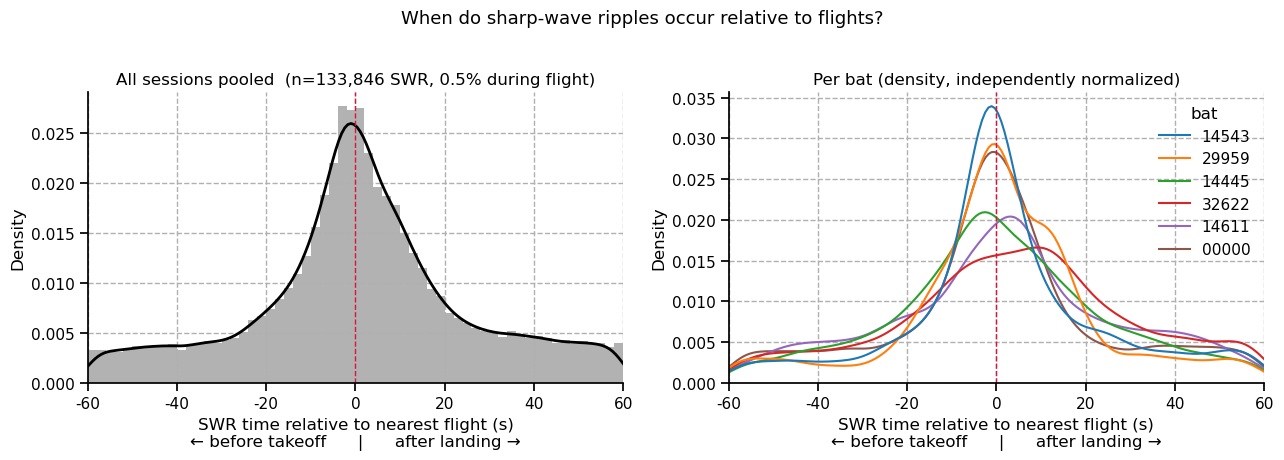

In [32]:
# --- SWR timing relative to the nearest flight bout ---
# during-flight events sit at exactly 0 by definition; exclude them from the
# pre/post histogram and report their fraction in the title instead.
WIN = 60.0
rest = swr_df[~swr_df.during_flight & (swr_df.signed_rel.abs() <= WIN)]
frac_fly = swr_df.during_flight.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=rest, x='signed_rel', bins=60, stat='density',
             color='0.6', edgecolor='none', ax=axes[0])
sns.kdeplot(data=rest, x='signed_rel', color='k', lw=2, ax=axes[0])
axes[0].axvline(0, color='crimson', ls='--', lw=1)
axes[0].set_title(f'All sessions pooled  (n={len(swr_df):,} SWR, {frac_fly:.1%} during flight)')

sns.kdeplot(data=rest, x='signed_rel', hue='bat', palette=BAT_PALETTE,
            common_norm=False, lw=1.5, ax=axes[1])
axes[1].axvline(0, color='crimson', ls='--', lw=1)
axes[1].set_title('Per bat (density, independently normalized)')

for ax in axes:
    ax.set_xlabel('SWR time relative to nearest flight (s)\n'
                  '← before takeoff      |      after landing →')
    ax.set_xlim(-WIN, WIN)
fig.suptitle('When do sharp-wave ripples occur relative to flights?', y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

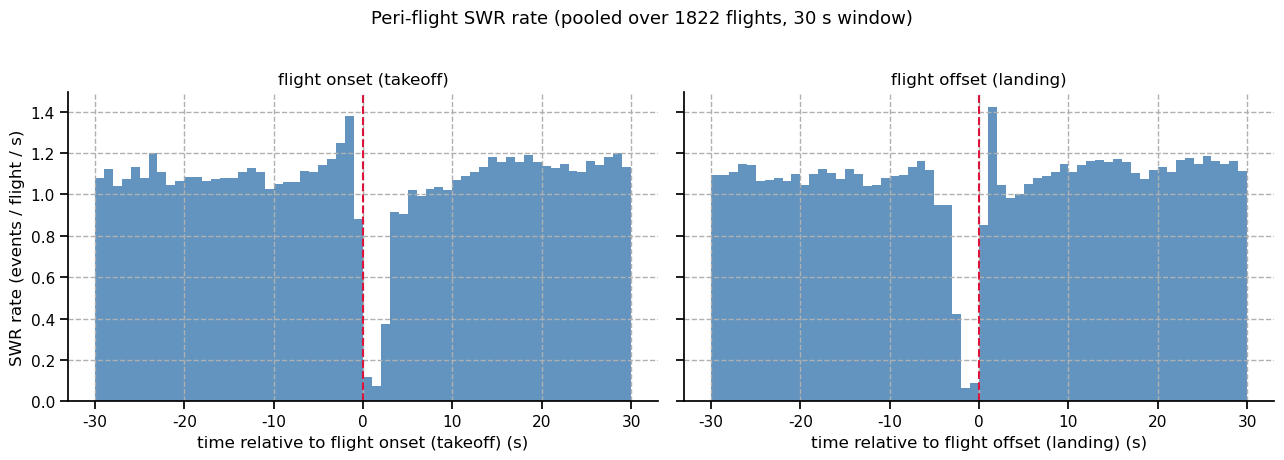

In [33]:
# --- Peri-flight-edge SWR rate: events / flight / s around takeoff & landing ---
BW = 1.0
bins = np.arange(-PSTH_WIN, PSTH_WIN + BW, BW)
centers = bins[:-1] + BW / 2
total_flights = swr_df.groupby('session').n_flights.first().sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (align, lab) in zip(axes, [('onset', 'flight onset (takeoff)'),
                                   ('offset', 'flight offset (landing)')]):
    dt = peri_df.loc[peri_df['align'] == align, 'dt'].values
    rate = np.histogram(dt, bins=bins)[0] / (total_flights * BW)
    ax.bar(centers, rate, width=BW, color='steelblue', alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.set_xlabel(f'time relative to {lab} (s)')
    ax.set_title(lab)
axes[0].set_ylabel('SWR rate (events / flight / s)')
fig.suptitle(f'Peri-flight SWR rate (pooled over {total_flights} flights, '
             f'{PSTH_WIN:.0f} s window)', y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

non-reward edges (perch + other): 958 takeoffs, 965 landings


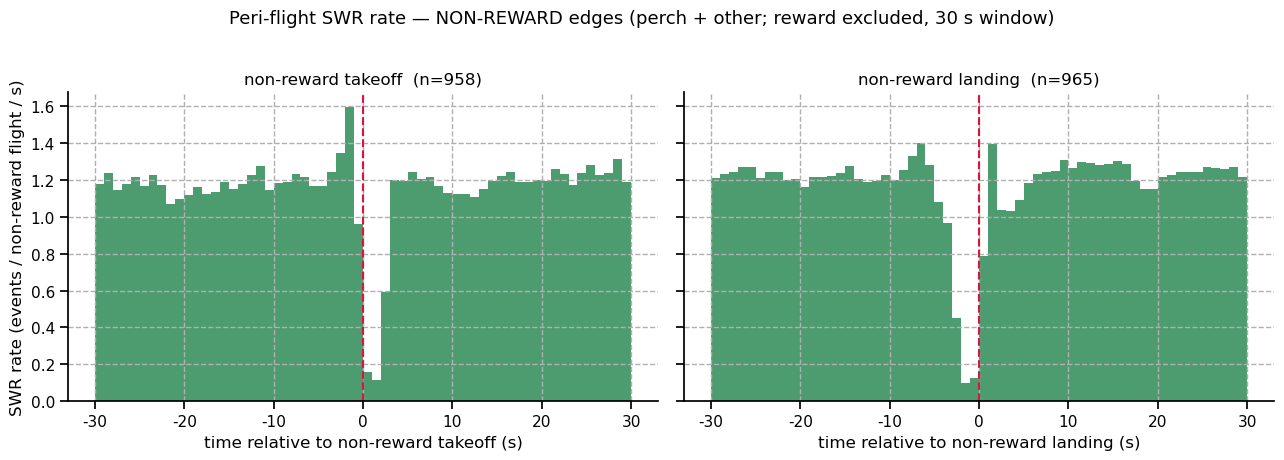

In [51]:
# --- Peri-flight SWR rate for NON-REWARD takeoffs / landings (rule out reward) ---
# Same peri-flight-edge PSTH as above, but dropping only flight edges AT A REWARD (takeoff
# panel = non-reward takeoffs, landing panel = non-reward landings = perch + 'other'), so any
# peri-flight SWR modulation can't be attributed to reward delivery / consumption at the edge.
# Non-reward = perch OR other, matching Task 1's edge_class (perch takes precedence over reward
# when a position is near both), via proximity to the session's reward/perch locations.
from notebook_helpers import compute_target_proximity

def load_flight_bout_edges(session_name):
    """(start_t, stop_t, toff_xyz, land_xyz) for the same bflying bouts as
    load_flight_bouts, plus 3-D position (N, 3) at each takeoff / landing frame."""
    bhv = loadmat(glob.glob(f'{PARENT}/{session_name}/Extracted_Behavior_*.mat')[0])
    fly = bhv['bflying'][:, 0] > 0
    t = bhv['t'][:, 0] if 'Dataset_2' in session_name else bhv['t'][0, :]
    r = np.asarray(bhv['r'])                        # 3-D position, (3, T)
    if r.shape[0] != 3 and r.shape[1] == 3:
        r = r.T
    d = np.diff(fly.astype(np.int8))
    starts = np.where(d == 1)[0] + 1
    stops = np.where(d == -1)[0] + 1
    if fly[0]:
        starts = np.r_[0, starts]
    if fly[-1]:
        stops = np.r_[stops, len(fly)]
    land_idx = stops - 1
    return t[starts], t[land_idx], r[:, starts].T, r[:, land_idx].T

def _non_reward(xyz, sess):
    """True for edges that are NOT classified 'reward' (= perch or other)."""
    prox = compute_target_proximity(xyz, session_name=sess)
    return prox['at_perch'] | ~prox['at_rew']

nonrew_peri_rows, n_nonrew = [], {'onset': 0, 'offset': 0}
for sess in SESSION_NAMES:
    if not glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat'):
        continue
    if not os.path.isdir(f'{PARENT}/RPL_converted/{sess}'):
        continue
    start_t, stop_t, toff_xyz, land_xyz = load_flight_bout_edges(sess)
    swr_t, _ = load_swr_events(sess)
    if len(start_t) == 0 or len(swr_t) == 0:
        continue
    for align, edges, keep in (('onset', start_t, _non_reward(toff_xyz, sess)),
                               ('offset', stop_t, _non_reward(land_xyz, sess))):
        e = np.asarray(edges)[keep]
        n_nonrew[align] += len(e)
        nonrew_peri_rows.append(pd.DataFrame(dict(
            session=sess, bat=parse_bat(sess), align=align,
            dt=peri_event_diffs(e, swr_t, PSTH_WIN), n_edges=len(e))))
nonrew_peri_df = pd.concat(nonrew_peri_rows, ignore_index=True)
print(f'non-reward edges (perch + other): {n_nonrew["onset"]} takeoffs, {n_nonrew["offset"]} landings')

BW = 1.0
bins = np.arange(-PSTH_WIN, PSTH_WIN + BW, BW)
centers = bins[:-1] + BW / 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (align, lab, n_e) in zip(axes, [('onset', 'non-reward takeoff', n_nonrew['onset']),
                                        ('offset', 'non-reward landing', n_nonrew['offset'])]):
    dt = nonrew_peri_df.loc[nonrew_peri_df['align'] == align, 'dt'].values
    rate = np.histogram(dt, bins=bins)[0] / (max(n_e, 1) * BW)      # events / non-reward flight / s
    ax.bar(centers, rate, width=BW, color='seagreen', alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.set_xlabel(f'time relative to {lab} (s)')
    ax.set_title(f'{lab}  (n={n_e})')
axes[0].set_ylabel('SWR rate (events / non-reward flight / s)')
fig.suptitle(f'Peri-flight SWR rate — NON-REWARD edges (perch + other; reward excluded, '
             f'{PSTH_WIN:.0f} s window)', y=1.02, fontsize=13)
fig.tight_layout()
plt.show()

## Linking SWRs to individual flights

The section above pooled SWRs against raw flight bouts. The analyses below need
each SWR tied to a *specific* flight with its **cluster id**, **endpoint type**
(perch / reward), and (for Task 2) the joint model's per-flight decode error and
Jacobian magnification. We therefore rebuild a per-flight table whose
`flight_path_index` **exactly matches** the joint model's `batch.flight_path_index`
by replaying `Data_Prep_for_Raw.get_flight_cluster()`'s construction (same
acceleration filter, cluster ordering). This uses the model's 17-session set
(Datasets 1–3, excluding `Dataset_3_14543_240419`); all 17 have ripple data.

In [20]:
# --- Reconstruct per-flight table aligned to flight_path_index ---
import io, contextlib
import digitalbat.datasets.data as _ddata
from notebook_helpers import compute_target_proximity

FLIGHT_SESSIONS = [s for s in SESSION_NAMES if s != 'Dataset_3_14543_240419']  # joint model's 17
BIN_WIDTH, MAX_ACCEL = 0.10, 50

def session_room(s):
    if '_fs' in s:               return 'krishna_fs'
    if s.startswith('Dataset_2_'): return 'dataset_2'
    return 'lab'

def reconstruct_flights(session_name):
    folder = f'{PARENT}/{session_name}'
    su = f'{PARENT}/To_transfer/out_Gunits_probe*_{session_name}_with_metrics.mat'
    dp = _ddata.Data_Prep_for_Raw(
        parent_folder=folder, su_file_path=su, only_flight_flag=True,
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=BIN_WIDTH, max_acceleration=MAX_ACCEL)
    with contextlib.redirect_stdout(io.StringIO()):       # silence pipeline prints
        dp.get_all_behavior(); dp.get_all_spike(); dp.get_flight_cluster()
    bhv = loadmat(glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    bhv_t = bhv['t'][:, 0] if 'Dataset_2' in session_name else bhv['t'][0, :]
    fcr, atf = dp.flight_cluster_results, dp.all_time_flight
    pre = []
    for cid in np.unique(fcr['id']):
        sel = np.where(fcr['id'] == cid)[0]
        st, sp = bhv_t[fcr['start_frame'][sel]], bhv_t[fcr['stop_frame'][sel]]
        for ii in range(len(st)):
            ind = np.where((atf >= st[ii]) & (atf <= sp[ii]))[0]
            if len(ind):
                pos = dp.all_behavior[:3, ind].T
                acc = np.gradient(np.gradient(pos, BIN_WIDTH, axis=0), BIN_WIDTH, axis=0)
                pre.append((int(cid), float(st[ii]), float(sp[ii]),
                            pos[0], pos[-1], float(np.linalg.norm(acc, axis=1).max())))
    kept = [r for r in pre if r[5] <= MAX_ACCEL]          # same accel filter -> same index
    assert [r[0] for r in kept] == list(dp.all_behavior_type), session_name
    rows = []
    for fpi, (cid, st, sp, toff, land, _) in enumerate(kept):
        rows.append(dict(session=session_name, bat=parse_bat(session_name),
            room=session_room(session_name), flight_path_index=fpi, flight_type_index=cid,
            start_t=st, stop_t=sp, dur=sp - st,
            toff_x=toff[0], toff_y=toff[1], toff_z=toff[2],
            land_x=land[0], land_y=land[1], land_z=land[2]))
    return pd.DataFrame(rows)

_parts = []
for sess in FLIGHT_SESSIONS:
    fdf = reconstruct_flights(sess)
    for kind, cols in (('toff', ['toff_x','toff_y','toff_z']), ('land', ['land_x','land_y','land_z'])):
        prox = compute_target_proximity(fdf[cols].to_numpy(), session_name=sess)
        fdf[f'{kind}_at_perch'], fdf[f'{kind}_at_rew'] = prox['at_perch'], prox['at_rew']
        fdf[f'{kind}_dist_perch'], fdf[f'{kind}_dist_rew'] = prox['dist_perch'], prox['dist_rew']
    _parts.append(fdf)
flight_df = pd.concat(_parts, ignore_index=True)
print(f'{len(flight_df)} flights, {flight_df.session.nunique()} sessions, {flight_df.bat.nunique()} bats')

1754 flights, 17 sessions, 6 bats


In [21]:
# --- Attach peri-flight SWR context + cluster annotations to each flight ---
# pre_takeoff / post_landing = # SWR events in a W_PERI-s window before takeoff /
# after landing. The W=3 s window captures the peri-flight burst (see PSTH above).
W_PERI = 3.0

def edge_class(at_perch, at_rew):
    return np.where(at_perch, 'perch', np.where(at_rew, 'reward', 'other'))

swr_times_by_session, _parts = {}, []
for sess, fdf in flight_df.groupby('session'):
    swr_t = np.sort(load_swr_events(sess)[0]); swr_times_by_session[sess] = swr_t
    fdf = fdf.copy()
    st, sp = fdf['start_t'].to_numpy(), fdf['stop_t'].to_numpy()
    fdf['pre_takeoff']  = np.searchsorted(swr_t, st) - np.searchsorted(swr_t, st - W_PERI)
    fdf['post_landing'] = np.searchsorted(swr_t, sp + W_PERI) - np.searchsorted(swr_t, sp)
    fdf['takeoff_class'] = edge_class(fdf['toff_at_perch'].to_numpy(), fdf['toff_at_rew'].to_numpy())
    fdf['landing_class'] = edge_class(fdf['land_at_perch'].to_numpy(), fdf['land_at_rew'].to_numpy())
    fdf = fdf.sort_values('start_t')
    fdf['next_takeoff_t'] = fdf['start_t'].shift(-1)
    fdf['dwell_after'] = fdf['next_takeoff_t'] - fdf['stop_t']   # rest duration after landing
    _parts.append(fdf)
flights = pd.concat(_parts, ignore_index=True)

# cluster annotations: size, repeated vs unique, most-frequent (top) cluster
flights['cluster_size'] = flights.groupby(['session','flight_type_index'])['flight_path_index'].transform('size')
flights['repeated'] = np.where(flights['cluster_size'] > 1, 'repeated', 'unique')
flights['top_cluster'] = flights.groupby('session')['flight_type_index'].transform(
    lambda s: s == s.value_counts().idxmax())
flights['room2'] = np.where(flights['room'] == 'lab', 'lab', 'field station')

# within-session position: flight number (0-based, by takeoff time) and normalized
# flight number in [0,1] -- used as a session-time covariate in the mixed models so
# cluster-size / SWR effects can be separated from the within-session decline (Task 5).
flights['flight_num'] = flights.groupby('session')['start_t'].rank(method='first').astype(int) - 1
flights['flight_frac'] = flights.groupby('session')['flight_num'].transform(lambda s: s / max(s.max(), 1))

# session SWR baseline rate (events/s over the recording span)
base = {s: (len(t) / (t.max() - t.min()) if len(t) > 1 else np.nan)
        for s, t in swr_times_by_session.items()}
flights['baseline_rate'] = flights['session'].map(base)
print('mean pre/post SWR per flight:', flights[['pre_takeoff','post_landing']].mean().round(2).to_dict(),
      '| baseline rate (Hz):', round(np.nanmean(list(base.values())), 3))
print('repeated:', (flights.repeated=='repeated').mean().round(2),
      '| top-cluster flights:', flights.top_cluster.mean().round(2))

mean pre/post SWR per flight: {'pre_takeoff': 3.46, 'post_landing': 3.29} | baseline rate (Hz): 1.445
repeated: 0.84 | top-cluster flights: 0.31


In [22]:
# --- reusable session-level contrast plot (nonparametric, dots colored by bat) ---
from digitalbat.utility.utils import wilcoxon_safe, add_significance_bracket, stars_for_p
from scipy.stats import mannwhitneyu, spearmanr, friedmanchisquare, pearsonr

def session_contrast(ax, long_df, order, value_label, paired=True, legend=False):
    '''long_df cols: session, bat, cond, val. One dot per (session, cond) coloured by
    bat; black bar = mean; paired sessions connected. Wilcoxon (paired) / Mann-Whitney
    (unpaired); 3-tier stars, n.s. hidden (project convention).'''
    sns.stripplot(data=long_df, x='cond', y='val', order=order, hue='bat', palette=BAT_PALETTE,
                  ax=ax, size=7, jitter=0.12, edgecolor='k', linewidth=0.4, zorder=3, legend=legend)
    means = long_df.groupby('cond')['val'].mean()
    for i, c in enumerate(order):
        if c in means.index:
            ax.hlines(means[c], i - 0.32, i + 0.32, color='k', lw=2.2, zorder=4)
    p, n = np.nan, 0
    if len(order) == 2:
        if paired:
            piv = long_df.pivot_table(index='session', columns='cond', values='val').dropna()
            for _, r in piv.iterrows():
                ax.plot([0, 1], [r[order[0]], r[order[1]]], color='0.78', lw=0.5, zorder=1)
            _, p = wilcoxon_safe((piv[order[0]] - piv[order[1]]).values); n = len(piv)
        else:
            a = long_df[long_df.cond == order[0]]['val'].dropna()
            b = long_df[long_df.cond == order[1]]['val'].dropna()
            if len(a) and len(b):
                _, p = mannwhitneyu(a, b); n = f'{len(a)},{len(b)}'
        add_significance_bracket(ax, 0, 1, p)
    ax.set_ylabel(value_label); ax.set_xlabel(''); ax.set_title(f'p={p:.3f} (n={n})', fontsize=9)
    return p

def bat_legend(fig):
    import matplotlib.patches as mpatches
    h = [mpatches.Patch(color=c, label=b) for b, c in BAT_PALETTE.items()]
    fig.legend(handles=h, title='bat', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8)

def session_threeway(ax, long_df, order, value_label, legend=False):
    '''Three-group session-level comparison: stripplot (dots by bat) + mean bars,
    omnibus Friedman across complete sessions, and pairwise Wilcoxon brackets
    (n.s. hidden). long_df cols: session, bat, cond, val.'''
    sns.stripplot(data=long_df, x='cond', y='val', order=order, hue='bat', palette=BAT_PALETTE,
                  ax=ax, size=7, jitter=0.12, edgecolor='k', linewidth=0.4, zorder=3, legend=legend)
    means = long_df.groupby('cond')['val'].mean()
    for i, c in enumerate(order):
        if c in means.index:
            ax.hlines(means[c], i - 0.32, i + 0.32, color='k', lw=2.2, zorder=4)
    wide = long_df.pivot_table(index='session', columns='cond', values='val')
    piv = wide[[c for c in order if c in wide.columns]].dropna()
    p_omni = (friedmanchisquare(*[piv[c].values for c in order])[1]
              if piv.shape[1] == len(order) and len(piv) >= 3 else np.nan)
    ymax, ymin = long_df['val'].max(), long_df['val'].min(); span = (ymax - ymin) or 1.0
    lvl = 0
    for a, b in [(0, 1), (1, 2), (0, 2)]:
        if order[a] in wide.columns and order[b] in wide.columns:
            two = wide[[order[a], order[b]]].dropna()
            _, pp = wilcoxon_safe((two[order[a]] - two[order[b]]).values)
            if stars_for_p(pp):
                add_significance_bracket(ax, a, b, pp, y=ymax + (0.05 + 0.11 * lvl) * span); lvl += 1
    ax.set_ylabel(value_label); ax.set_xlabel('')
    ax.set_title(f'Friedman p={p_omni:.3f} (n={len(piv)})', fontsize=9)
    return p_omni

## Task 1 — SWRs around perch vs reward takeoffs & landings

Are SWRs more likely *after* a landing or *before* a takeoff, and does the
endpoint type (perch vs reward) matter? First the peri-flight SWR-rate time
course split by endpoint class, then per-session contrasts (rate = SWR count in a
3 s window / window length), tested with paired session-level Wilcoxon, dots
coloured by bat. The endpoint contrasts — **perch vs reward**, **perch vs
non-perch**, **reward vs non-reward** — are each computed **separately for
landings and takeoffs**, alongside the overall after-landing vs before-takeoff
comparison. Finally a **three-way** test (perch vs reward vs other) — omnibus
Friedman plus pairwise brackets — is run separately for landings and takeoffs.

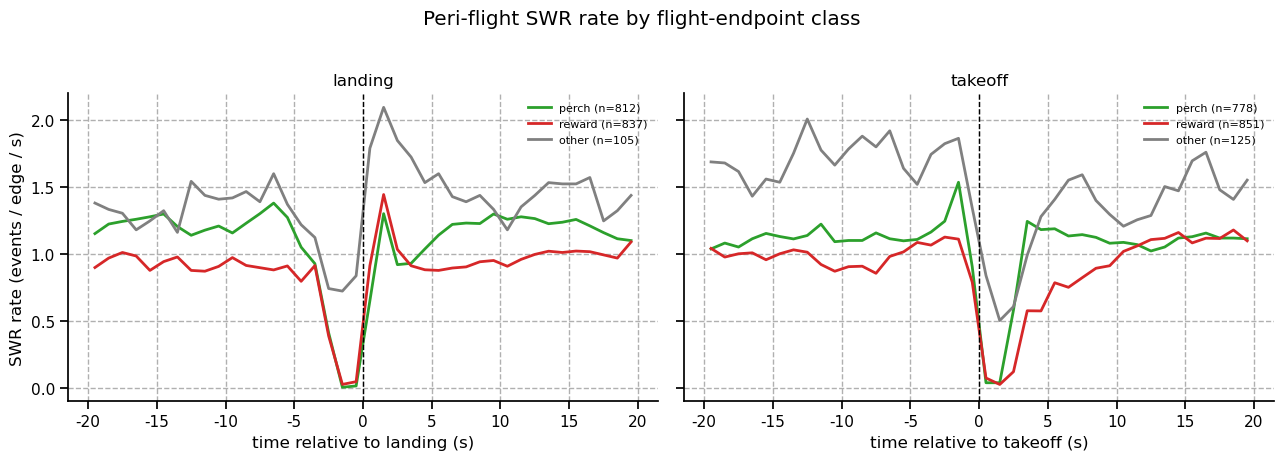

In [23]:
# --- Peri-flight SWR rate split by endpoint class (perch/reward/other) ---
WIN, BW = 20.0, 1.0
bins = np.arange(-WIN, WIN + BW, BW); ctr = bins[:-1] + BW / 2
CLASSES = ['perch', 'reward', 'other']
CCOL = {'perch': 'tab:green', 'reward': 'tab:red', 'other': '0.5'}

land_d = {c: [] for c in CLASSES}; toff_d = {c: [] for c in CLASSES}
n_land = {c: 0 for c in CLASSES}; n_toff = {c: 0 for c in CLASSES}
for sess, fdf in flights.groupby('session'):
    swr_t = swr_times_by_session[sess]
    for sp, c in zip(fdf['stop_t'], fdf['landing_class']):
        land_d[c].append(swr_t[(swr_t >= sp - WIN) & (swr_t <= sp + WIN)] - sp); n_land[c] += 1
    for st, c in zip(fdf['start_t'], fdf['takeoff_class']):
        toff_d[c].append(swr_t[(swr_t >= st - WIN) & (swr_t <= st + WIN)] - st); n_toff[c] += 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, dd, ne, lab in [(axes[0], land_d, n_land, 'landing'), (axes[1], toff_d, n_toff, 'takeoff')]:
    for c in CLASSES:
        d = np.concatenate(dd[c]) if dd[c] else np.zeros(0)
        ax.plot(ctr, np.histogram(d, bins=bins)[0] / (max(ne[c], 1) * BW),
                color=CCOL[c], lw=2, label=f'{c} (n={ne[c]})')
    ax.axvline(0, color='k', ls='--', lw=1); ax.set_xlabel(f'time relative to {lab} (s)')
    ax.set_title(lab); ax.legend(fontsize=8)
axes[0].set_ylabel('SWR rate (events / edge / s)')
fig.suptitle('Peri-flight SWR rate by flight-endpoint class', y=1.02); fig.tight_layout(); plt.show()

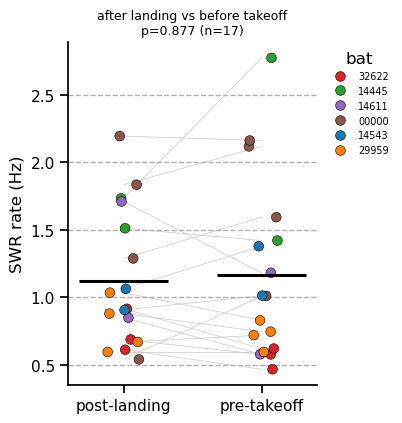

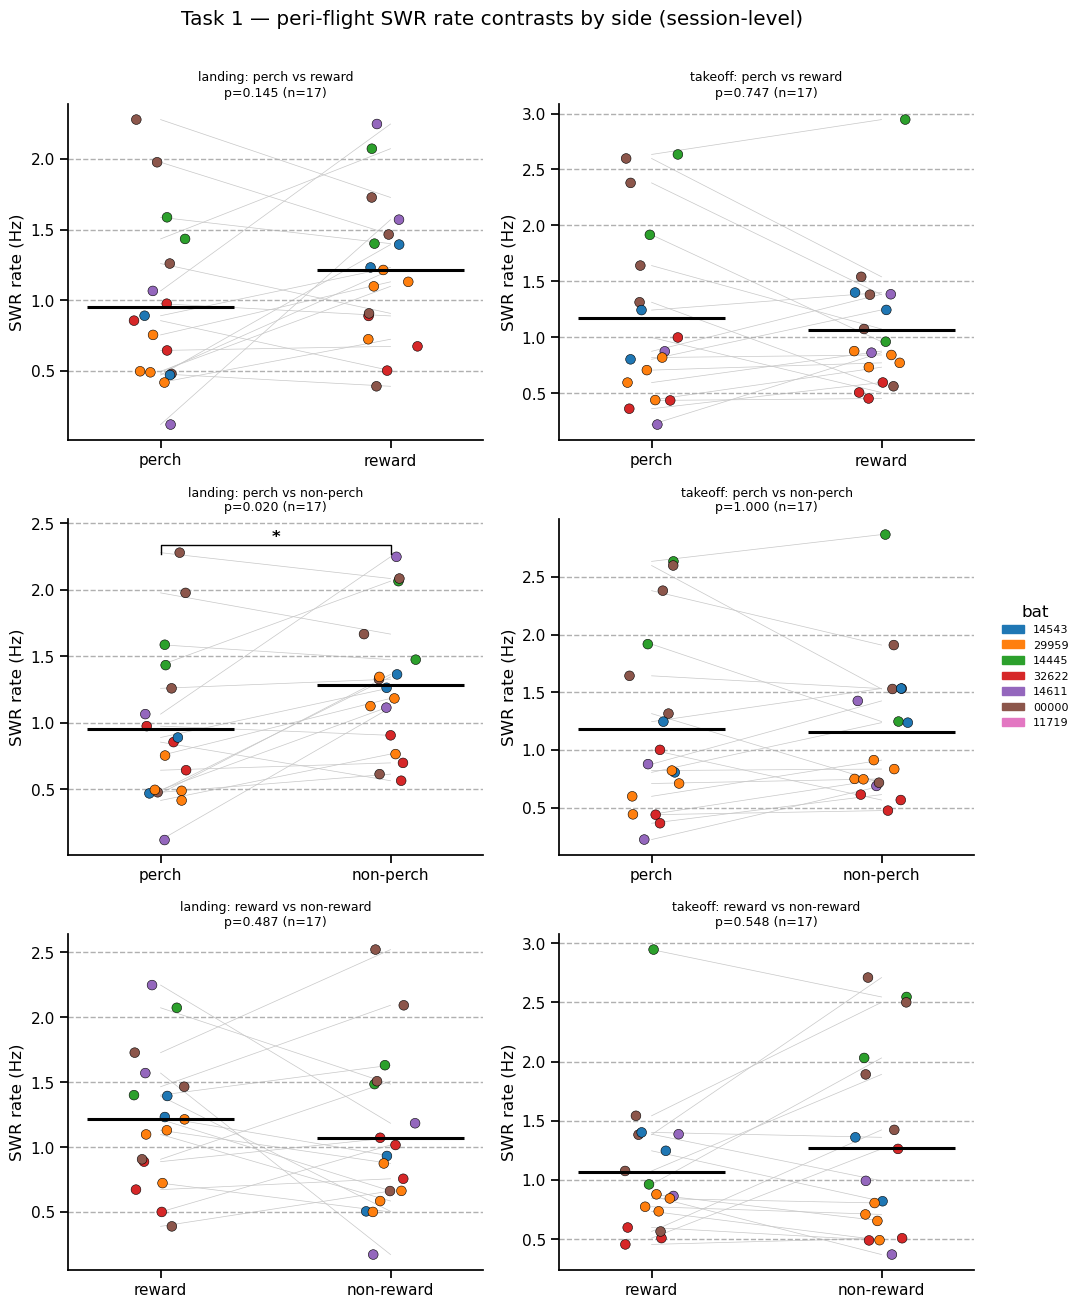

after landing vs before takeoff (Hz): {'post-landing': 1.098, 'pre-takeoff': 1.155}
 landing | perch vs reward: {'perch': np.float64(0.958), 'reward': np.float64(1.131)}
 takeoff | perch vs reward: {'perch': np.float64(1.229), 'reward': np.float64(1.01)}
 landing | perch vs non-perch: {'perch': np.float64(0.958), 'non-perch': np.float64(1.218)}
 takeoff | perch vs non-perch: {'perch': np.float64(1.229), 'non-perch': np.float64(1.095)}
 landing | reward vs non-reward: {'reward': np.float64(1.131), 'non-reward': np.float64(1.067)}
 takeoff | reward vs non-reward: {'reward': np.float64(1.01), 'non-reward': np.float64(1.291)}


In [24]:
# --- Per-session SWR-rate contrasts around flight edges ---
edges = pd.concat([
    flights[['session','bat','pre_takeoff','takeoff_class']].rename(
        columns={'pre_takeoff':'n','takeoff_class':'cls'}).assign(side='pre-takeoff'),
    flights[['session','bat','post_landing','landing_class']].rename(
        columns={'post_landing':'n','landing_class':'cls'}).assign(side='post-landing'),
], ignore_index=True)
edges['rate'] = edges['n'] / W_PERI

edges['perch_grp']  = np.where(edges.cls == 'perch',  'perch',  'non-perch')
edges['reward_grp'] = np.where(edges.cls == 'reward', 'reward', 'non-reward')

def per_session(df, group):
    return (df.groupby(['session','bat', group])['rate'].mean().reset_index()
              .rename(columns={group:'cond','rate':'val'}))

SIDES = ['post-landing', 'pre-takeoff']
SIDE_LABEL = {'post-landing': 'landing', 'pre-takeoff': 'takeoff'}

# (i) overall: after landing vs before takeoff (pooled over endpoint types)
fig0, ax0 = plt.subplots(figsize=(4.2, 4.4))
session_contrast(ax0, per_session(edges, 'side'), SIDES, 'SWR rate (Hz)', legend=True)
ax0.set_title('after landing vs before takeoff\n' + ax0.get_title(), fontsize=9)
ax0.legend(title='bat', fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
fig0.tight_layout(); plt.show()

# (ii) endpoint-type contrasts, each split by side (landing vs takeoff)
ROWS = [('perch vs reward',     'cls',        ['perch', 'reward'],      True),
        ('perch vs non-perch',  'perch_grp',  ['perch', 'non-perch'],   False),
        ('reward vs non-reward','reward_grp', ['reward', 'non-reward'], False)]
fig, axes = plt.subplots(3, 2, figsize=(10, 13))
for r, (name, gcol, order, pr_only) in enumerate(ROWS):
    for c, side in enumerate(SIDES):
        sub = edges[edges.side == side]
        if pr_only:
            sub = sub[sub.cls.isin(['perch', 'reward'])]
        session_contrast(axes[r, c], per_session(sub, gcol), order, 'SWR rate (Hz)')
        axes[r, c].set_title(f'{SIDE_LABEL[side]}: {name}\n' + axes[r, c].get_title(), fontsize=9)
bat_legend(fig)
fig.suptitle('Task 1 — peri-flight SWR rate contrasts by side (session-level)', y=1.005)
fig.tight_layout(); plt.show()

print('after landing vs before takeoff (Hz):', edges.groupby('side').rate.mean().round(3).to_dict())
for name, gcol, order, pr_only in ROWS:
    for side in SIDES:
        sub = edges[edges.side == side]
        if pr_only:
            sub = sub[sub.cls.isin(['perch', 'reward'])]
        m = sub.groupby(gcol).rate.mean().round(3)
        print(f'{SIDE_LABEL[side]:>8} | {name}:', {k: m[k] for k in order if k in m.index})

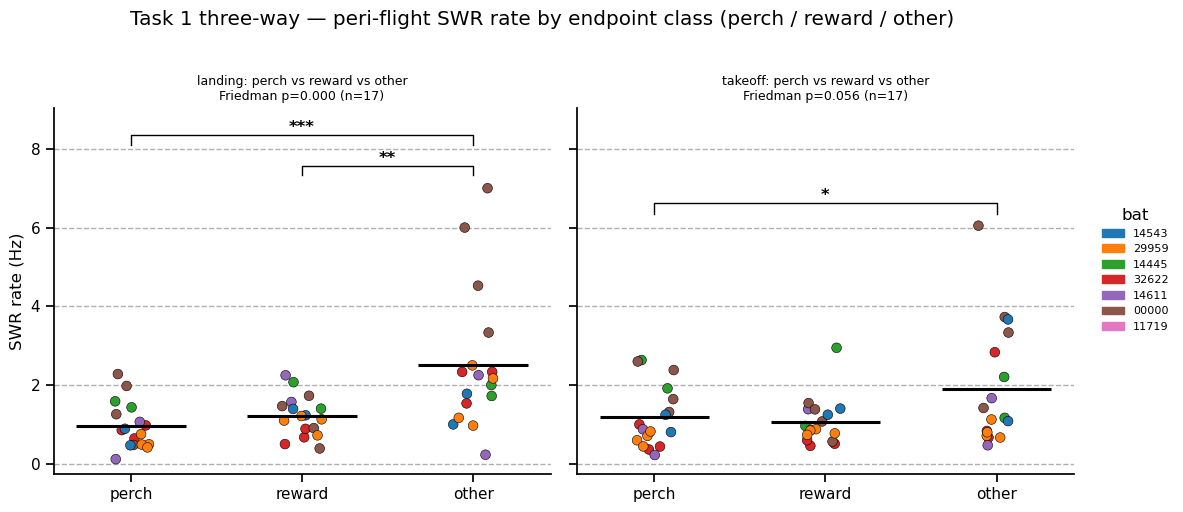

 landing mean SWR rate (Hz): {'perch': np.float64(0.958), 'reward': np.float64(1.131), 'other': np.float64(1.911)}
 takeoff mean SWR rate (Hz): {'perch': np.float64(1.229), 'reward': np.float64(1.01), 'other': np.float64(1.677)}


In [25]:
# --- Task 1 three-way: perch vs reward vs other, separately by side ---
# Omnibus Friedman across the 3 endpoint classes (paired over sessions with all
# three present) + pairwise Wilcoxon brackets, for landings and takeoffs.
CLS3 = ['perch', 'reward', 'other']
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, side, lab in [(axes[0], 'post-landing', 'landing'), (axes[1], 'pre-takeoff', 'takeoff')]:
    ps = (edges[edges.side == side].groupby(['session', 'bat', 'cls'])['rate'].mean()
          .reset_index().rename(columns={'cls': 'cond', 'rate': 'val'}))
    session_threeway(ax, ps, CLS3, 'SWR rate (Hz)')
    ax.set_title(f'{lab}: perch vs reward vs other\n' + ax.get_title(), fontsize=9)
bat_legend(fig)
fig.suptitle('Task 1 three-way — peri-flight SWR rate by endpoint class (perch / reward / other)', y=1.02)
fig.tight_layout(); plt.show()

for side, lab in [('post-landing', 'landing'), ('pre-takeoff', 'takeoff')]:
    m = edges[edges.side == side].groupby('cls').rate.mean().round(3)
    print(f'{lab:>8} mean SWR rate (Hz):', {c: m.get(c, np.nan) for c in CLS3})

## Task 3 — Do SWRs predict / retrodict flight clusters?

Flights are clustered by trajectory shape (Fréchet). For each flight we ask
whether peri-flight SWR activity differs by cluster identity:
**predict** = SWRs *before* takeoff (`pre_takeoff`) vs the upcoming flight's
cluster; **retrodict** = SWRs *after* landing (`post_landing`) vs the just-flown
cluster. We contrast **repeated** (cluster flown >1×) vs **unique** flights and
the session's **most-frequent (top)** cluster vs the rest.

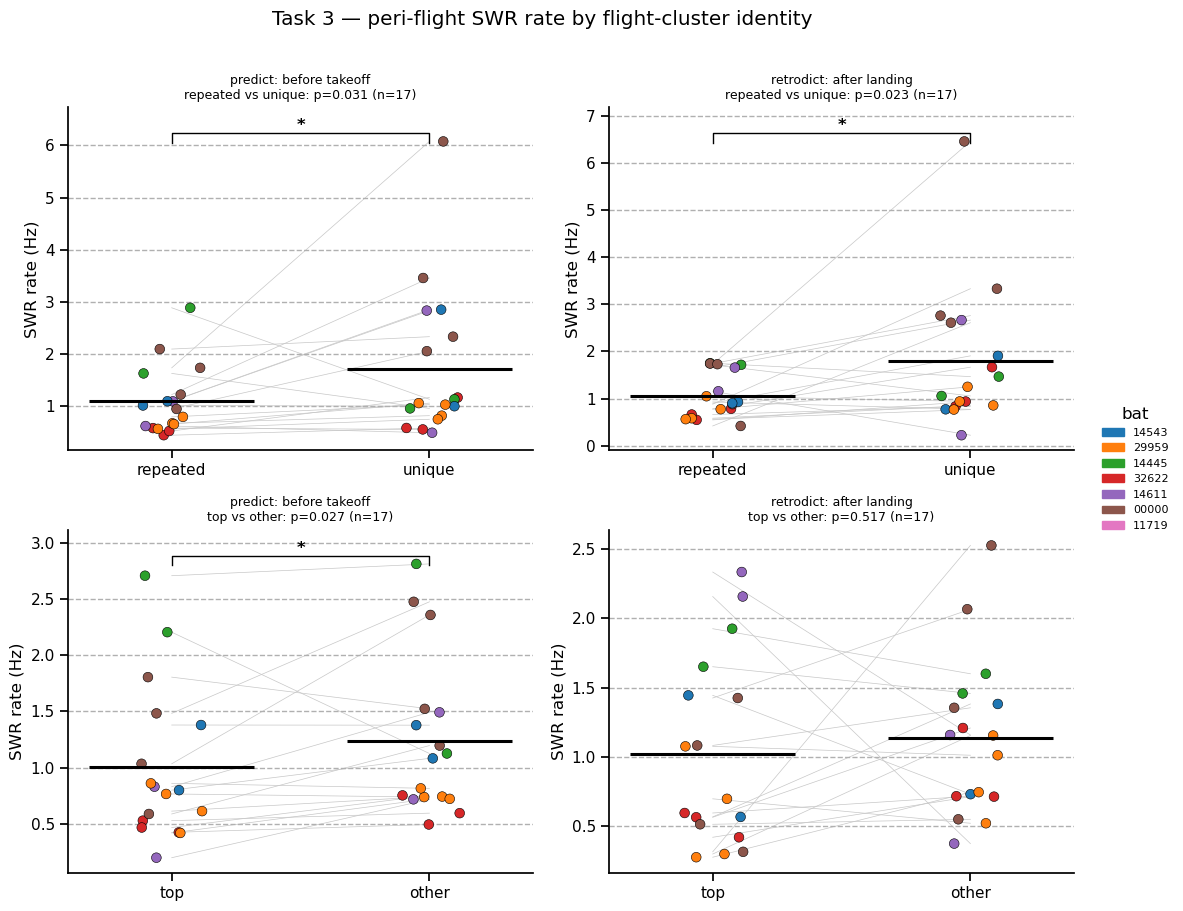

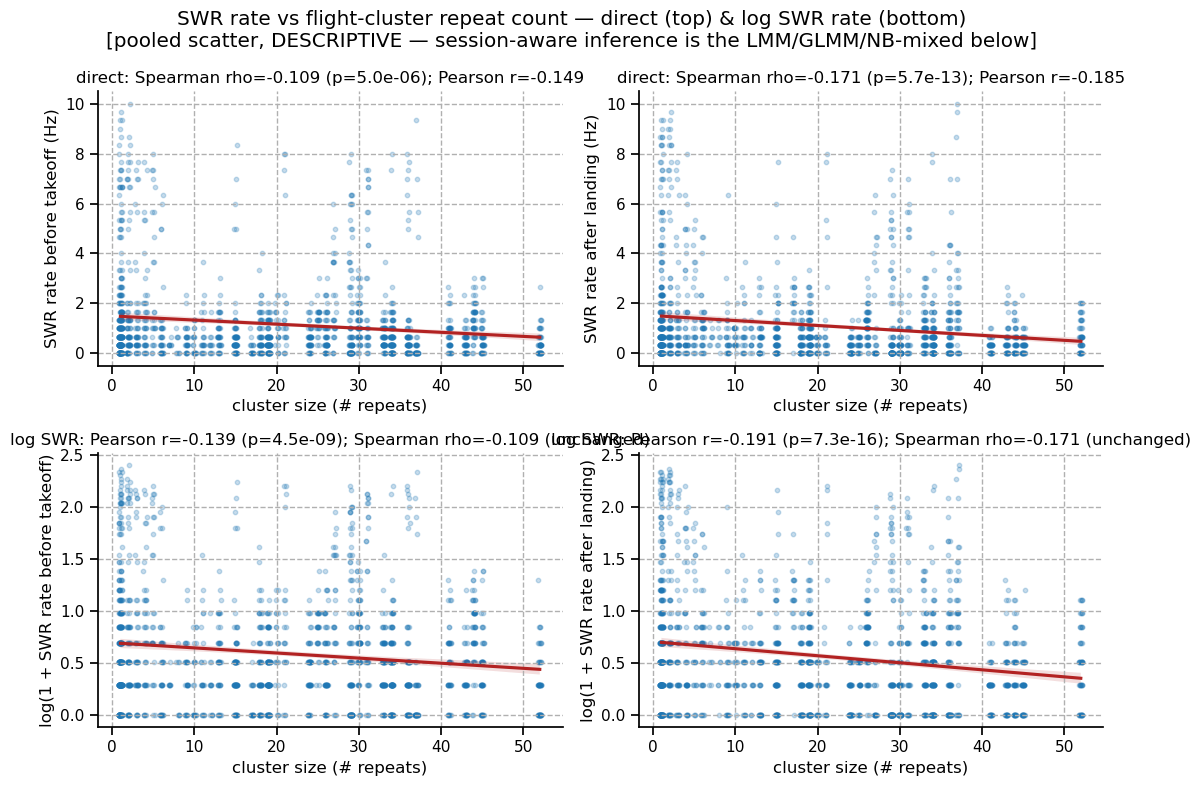

predict (pre-takeoff) repeated vs unique (Hz): {'repeated': 1.083, 'unique': 1.519}
predict (pre-takeoff) top vs other (Hz): {'other': 1.229, 'top': 0.988}
retrodict (post-landing) repeated vs unique (Hz): {'repeated': 1.01, 'unique': 1.543}


In [26]:
# --- SWR before/after flight vs cluster identity ---
flights['pre_rate'] = flights['pre_takeoff'] / W_PERI
flights['post_rate'] = flights['post_landing'] / W_PERI

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
specs = [
    (axes[0,0], 'pre_rate', 'repeated', ['repeated','unique'], 'predict: before takeoff'),
    (axes[0,1], 'post_rate', 'repeated', ['repeated','unique'], 'retrodict: after landing'),
    (axes[1,0], 'pre_rate', 'top', ['top','other'], 'predict: before takeoff'),
    (axes[1,1], 'post_rate', 'top', ['top','other'], 'retrodict: after landing'),
]
for ax, metric, flag, order, ttl in specs:
    g = flights.copy()
    if flag == 'repeated':
        g['cond'] = g['repeated']
    else:
        g['cond'] = np.where(g['top_cluster'], 'top', 'other')
    ps = g.groupby(['session','bat','cond'])[metric].mean().reset_index().rename(columns={metric:'val'})
    session_contrast(ax, ps, order, 'SWR rate (Hz)')
    ax.set_title(f'{ttl}\n{order[0]} vs {order[1]}: ' + ax.get_title(), fontsize=9)
bat_legend(fig)
fig.suptitle('Task 3 — peri-flight SWR rate by flight-cluster identity', y=1.01)
fig.tight_layout(); plt.show()

# SWR rate vs cluster repeat count (per flight, pooled): direct AND log-transformed
# SWR rate. Spearman (rank) is invariant to the log, so the log mainly affects the
# linear (Pearson) fit; rate can be 0, so we use log1p.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for j, (metric, lab) in enumerate([('pre_rate','before takeoff'), ('post_rate','after landing')]):
    cs = flights['cluster_size'].values.astype(float)
    rate = flights[metric].values.astype(float)
    rho, p_s = spearmanr(cs, rate)
    # direct
    a = axes[0, j]
    sns.regplot(x=cs, y=rate, ax=a, x_jitter=0.2, scatter_kws=dict(s=10, alpha=0.25),
                line_kws=dict(color='firebrick'))
    r_d, p_d = pearsonr(cs, rate)
    a.set(xlabel='cluster size (# repeats)', ylabel=f'SWR rate {lab} (Hz)',
          title=f'direct: Spearman rho={rho:.3f} (p={p_s:.1e}); Pearson r={r_d:.3f}')
    # log-transformed SWR rate
    a = axes[1, j]
    lr = np.log1p(rate)
    sns.regplot(x=cs, y=lr, ax=a, x_jitter=0.2, scatter_kws=dict(s=10, alpha=0.25),
                line_kws=dict(color='firebrick'))
    r_l, p_l = pearsonr(cs, lr)
    a.set(xlabel='cluster size (# repeats)', ylabel=f'log(1 + SWR rate {lab})',
          title=f'log SWR: Pearson r={r_l:.3f} (p={p_l:.1e}); Spearman rho={rho:.3f} (unchanged)')
fig.suptitle('SWR rate vs flight-cluster repeat count — direct (top) & log SWR rate (bottom)\n'
             '[pooled scatter, DESCRIPTIVE — session-aware inference is the LMM/GLMM/NB-mixed below]')
fig.tight_layout(); plt.show()

_top = np.where(flights.top_cluster, 'top', 'other')
print('predict (pre-takeoff) repeated vs unique (Hz):', flights.groupby('repeated').pre_rate.mean().round(3).to_dict())
print('predict (pre-takeoff) top vs other (Hz):', flights.groupby(_top).pre_rate.mean().round(3).to_dict())
print('retrodict (post-landing) repeated vs unique (Hz):', flights.groupby('repeated').post_rate.mean().round(3).to_dict())

### Task 3 — mixed-effects / count models for SWR rate vs cluster size

The pooled correlation above ignores the nested data structure and the count
nature of SWRs. We add three model families, with cluster size entered **raw** and
**log-transformed**, separately for the **pre-takeoff** ("predict") and
**post-landing** ("retrodict") windows. Here the SWR count is taken over the
**actual rest interval** adjacent to the flight (pre = previous-landing→takeoff;
post = landing→next-takeoff) so the exposure varies and an offset is meaningful;
`rate = count / interval`.

- **LMM** `rate ~ cluster_size + (1 | subject / session / trajectory_cluster)`
  (Gaussian; the requested nested random intercepts).
- **Poisson GLMM** `count ~ cluster_size + log(interval) + (1|subject)+(1|session)`
  via `PoissonBayesMixedGLM` (MAP fit; the `vb` optimiser is unstable here). The
  log-interval term plays the role of the offset; inference is the Laplace
  posterior mean ± sd (z, approx p).
- **NB mixed model** `glmer.nb(count ~ cluster_size + offset(log interval) +
  (1 | subject/session))` fit directly in R's **lme4** via **pymer4/rpy2** — the
  requested model, with a true offset, overdispersion (NB), and nested random
  effects together. (Run in the `gpu` conda env with `R_HOME` set.)
- **NB GLM** `count ~ cluster_size + offset(log interval)` with subject
  **cluster-robust** SEs — a no-R cross-check.

An overdispersion check (Poisson Pearson χ²/df) motivates the NB. If `glmer.nb`
can't be reached (no rpy2/R/lme4), that one row is simply skipped.

All four models also include **normalized flight number** (`flight_frac`) as a
covariate, so the cluster-size effect is separated from the within-session decline
(Task 5) — early-session flights are disproportionately novel. The table reports
the cluster predictor (`beta`/`p`) *and* `flight_frac` (`beta_ff`/`p_ff`).

In [27]:
# --- Task 3: LMM + Poisson GLMM + NB GLM for SWR vs cluster size ---
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.genmod.bayes_mixed_glm import PoissonBayesMixedGLM
from scipy.stats import norm
import warnings

# SWR counts over the actual adjacent rest interval (variable exposure)
fl = flights.sort_values(['session','start_t']).copy()
gg = fl.groupby('session')
fl['prev_stop'] = gg['stop_t'].shift(1); fl['next_start'] = gg['start_t'].shift(-1)
fl['exp_pre'] = fl['start_t'] - fl['prev_stop']; fl['exp_post'] = fl['next_start'] - fl['stop_t']
fl['pre_cnt'] = np.nan; fl['post_cnt'] = np.nan
for sess, idx in fl.groupby('session').groups.items():
    t = swr_times_by_session[sess]; d = fl.loc[idx]
    m1 = d['prev_stop'].notna().values
    pc = np.full(len(d), np.nan)
    pc[m1] = np.searchsorted(t, d['start_t'].values[m1]) - np.searchsorted(t, d['prev_stop'].values[m1])
    fl.loc[idx, 'pre_cnt'] = pc
    m2 = d['next_start'].notna().values
    qc = np.full(len(d), np.nan)
    qc[m2] = np.searchsorted(t, d['next_start'].values[m2]) - np.searchsorted(t, d['stop_t'].values[m2])
    fl.loc[idx, 'post_cnt'] = qc
fl['log_cs'] = np.log(fl['cluster_size'])

# All models also include normalized flight number (flight_frac, the within-session
# time covariate from Task 5) so the cluster-size effect is separated from the
# session-time decline. Each helper reports the cluster predictor AND flight_frac.
def lmm_rate(d, xcol):
    m = smf.mixedlm(f'rate ~ {xcol} + flight_frac', d, groups=d['bat'], re_formula='1',
                    vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(clu_uid)'})
    r = m.fit(reml=True, method='lbfgs', maxiter=400)
    return dict(model='LMM rate', beta=r.params[xcol], se=r.bse[xcol],
                stat=r.params[xcol]/r.bse[xcol], p=r.pvalues[xcol],
                beta_ff=r.params['flight_frac'], p_ff=r.pvalues['flight_frac'])

def pois_glmm(d, xcol):
    pm = PoissonBayesMixedGLM.from_formula(f'count ~ {xcol} + log_exp + flight_frac',
            {'subject': '0 + C(bat)', 'session': '0 + C(session)'}, d)
    r = pm.fit_map(); names = list(r.model.exog_names)
    i = names.index(xcol); z = r.fe_mean[i]/r.fe_sd[i]
    j = names.index('flight_frac'); zf = r.fe_mean[j]/r.fe_sd[j]
    return dict(model='Poisson GLMM', beta=r.fe_mean[i], se=r.fe_sd[i], stat=z,
                p=2*(1 - norm.cdf(abs(z))), beta_ff=r.fe_mean[j], p_ff=2*(1 - norm.cdf(abs(zf))))

def nb_glm(d, xcol):
    X = sm.add_constant(d[[xcol, 'flight_frac']].astype(float))
    r = sm.NegativeBinomial(d['count'].astype(float), X, offset=d['log_exp'].values).fit(
        disp=0, cov_type='cluster', cov_kwds={'groups': d['bat']})
    return dict(model='NB GLM (offset)', beta=r.params[xcol], se=r.bse[xcol],
                stat=r.params[xcol]/r.bse[xcol], p=r.pvalues[xcol],
                beta_ff=r.params['flight_frac'], p_ff=r.pvalues['flight_frac'])

# Negative-binomial MIXED model via R lme4::glmer.nb (rpy2): true offset + nested RE
import os as _os
_os.environ.setdefault('R_HOME', '/home/alowet/miniconda3/envs/gpu/lib/R')
try:
    import rpy2.robjects as _ro
    from rpy2.robjects import pandas2ri as _p2r
    import rpy2.rinterface_lib.callbacks as _rcb
    _rcb.consolewrite_print = lambda *a, **k: None
    _rcb.consolewrite_warnerror = lambda *a, **k: None
    _ro.r('suppressMessages(library(lme4))')
    _HAVE_NB_MIXED = True
except Exception as _e:
    _HAVE_NB_MIXED = False
    print('glmer.nb unavailable (need pymer4/rpy2 + R lme4):', str(_e)[:90])

def nb_mixed(d, xcol):
    sub = d[['count', 'log_exp', 'bat', 'session', 'flight_frac', xcol]].copy()
    with (_ro.default_converter + _p2r.converter).context():
        _ro.globalenv['d'] = sub
        _ro.r('d$bat <- factor(d$bat); d$session <- factor(d$session)')
        _ro.r(f'm <- suppressWarnings(lme4::glmer.nb(count ~ {xcol} + flight_frac + offset(log_exp) '
              f'+ (1|bat/session), data=d))')
        co = np.array(_ro.r('summary(m)$coefficients'))
        rn = list(_ro.r('rownames(summary(m)$coefficients)'))
    i = rn.index(xcol); j = rn.index('flight_frac')
    return dict(model='NB mixed (glmer.nb)', beta=co[i, 0], se=co[i, 1], stat=co[i, 2], p=co[i, 3],
                beta_ff=co[j, 0], p_ff=co[j, 3])

SIDE = {'pre-takeoff': ('pre_cnt', 'exp_pre'), 'post-landing': ('post_cnt', 'exp_post')}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for side, (ccol, ecol) in SIDE.items():
        d0 = fl.dropna(subset=[ccol, ecol]).copy(); d0 = d0[d0[ecol] > 0]
        d0['count'] = d0[ccol].astype(float); d0['log_exp'] = np.log(d0[ecol].astype(float))
        d0['rate'] = d0['count'] / d0[ecol]; d0['clu_uid'] = d0['session'] + '_' + d0['flight_type_index'].astype(str)
        pg = sm.GLM(d0['count'], sm.add_constant(d0[['cluster_size']].astype(float)),
                    family=sm.families.Poisson(), offset=d0['log_exp'].values).fit()
        print(f'{side}: n={len(d0)}, exposure median={d0[ecol].median():.1f}s, '
              f'Poisson overdispersion (Pearson chi2/df)={pg.pearson_chi2/pg.df_resid:.2f}')
        model_fns = [lmm_rate, pois_glmm, nb_glm] + ([nb_mixed] if _HAVE_NB_MIXED else [])
        for xcol in ['cluster_size', 'log_cs']:
            dd = d0.dropna(subset=[xcol, 'rate'])
            for fn in model_fns:
                try:
                    res = fn(dd, xcol)
                except Exception as e:
                    res = dict(model=fn.__name__, beta=np.nan, se=np.nan, stat=np.nan, p=np.nan,
                               beta_ff=np.nan, p_ff=np.nan)
                res.update(side=side, predictor=xcol, n=len(dd)); rows.append(res)
res_df = pd.DataFrame(rows)[['side', 'predictor', 'model', 'n', 'beta', 'p', 'beta_ff', 'p_ff']]
print('\\nSWR(count/rate) ~ cluster_size + flight_frac, nested models  [p two-sided]')
print('  beta/p = cluster predictor (controlling session time); beta_ff/p_ff = normalized flight number')
print(res_df.round(4).to_string(index=False))

pre-takeoff: n=1737, exposure median=19.7s, Poisson overdispersion (Pearson chi2/df)=52.04
post-landing: n=1737, exposure median=19.7s, Poisson overdispersion (Pearson chi2/df)=52.35
\nSWR(count/rate) ~ cluster_size + flight_frac, nested models  [p two-sided]
  beta/p = cluster predictor (controlling session time); beta_ff/p_ff = normalized flight number
        side    predictor               model    n    beta      p  beta_ff   p_ff
 pre-takeoff cluster_size            LMM rate 1737 -0.0245 0.0005  -1.3900 0.0000
 pre-takeoff cluster_size        Poisson GLMM 1737 -0.0078 0.0000  -0.9896 0.0000
 pre-takeoff cluster_size     NB GLM (offset) 1737 -0.0113 0.0187  -1.2090 0.0214
 pre-takeoff cluster_size NB mixed (glmer.nb) 1737 -0.0108 0.0000  -0.9332 0.0000
 pre-takeoff       log_cs            LMM rate 1737 -0.2271 0.0001  -1.3839 0.0000
 pre-takeoff       log_cs        Poisson GLMM 1737 -0.0948 0.0000  -0.9746 0.0000
 pre-takeoff       log_cs     NB GLM (offset) 1737 -0.1284 0.0402  -1

## Task 4 — Lab vs field station SWR signatures

The **field station** (outdoor arena = `Dataset_2`, bats 14445 & 14611) vs the
indoor **lab** (`Dataset_1` & `Dataset_3`, bats 32622, 14543, 29959, 00000). We
compare baseline SWR rate, event duration, peri-flight enrichment, and the
peri-flight time course. This cross-sectional comparison uses Dataset 2 (2 animals)
vs Datasets 1 & 3 (4 animals); the Krishna bat (11719), which was recorded in **both**
environments on the same day with the same units, is compared **within-animal** in
the next cell.

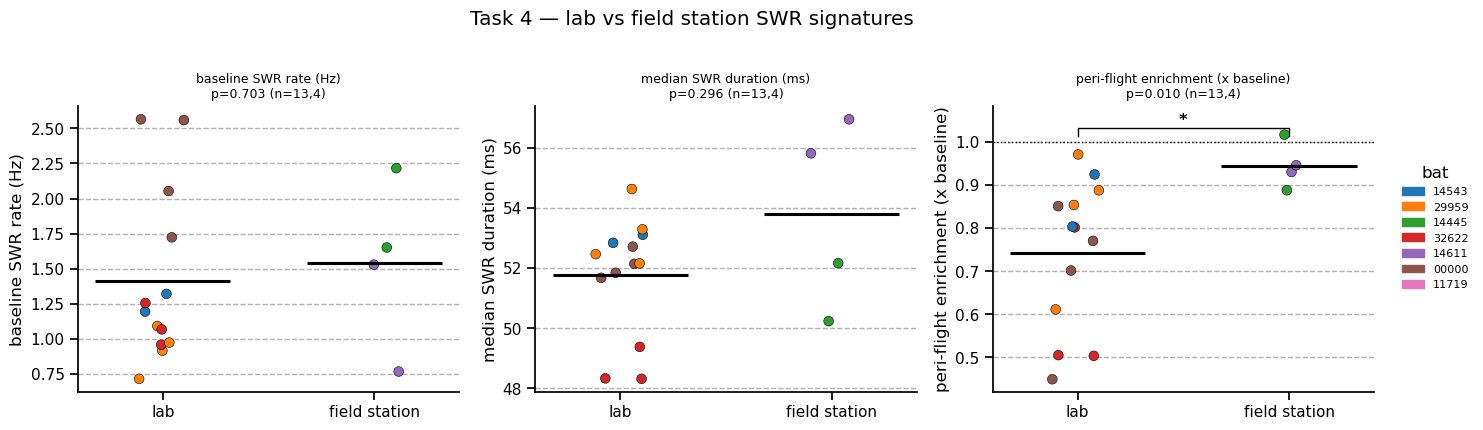

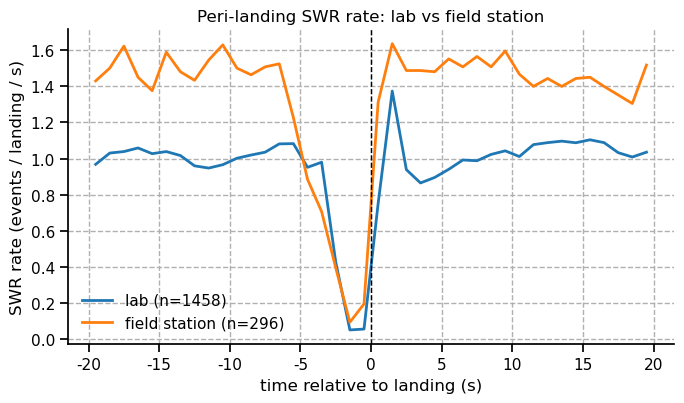

In [28]:
# --- Lab vs field station SWR signatures ---
# per-session SWR summaries
sess_swr = []
for sess in FLIGHT_SESSIONS:
    t, dur = load_swr_events(sess)
    sess_swr.append(dict(session=sess, bat=parse_bat(sess), room2=session_room(sess),
                         n_swr=len(t), span=(t.max()-t.min()) if len(t)>1 else np.nan,
                         med_dur_ms=np.median(dur)*1000))
sess_swr = pd.DataFrame(sess_swr)
sess_swr['room2'] = np.where(sess_swr['room2']=='lab', 'lab', 'field station')
sess_swr['rate'] = sess_swr['n_swr'] / sess_swr['span']

# peri-flight enrichment per session = peri-flight SWR rate / baseline rate
g = flights.groupby('session')
peri = pd.DataFrame({
    'peri_rate': (g['pre_takeoff'].sum() + g['post_landing'].sum()) / (2 * g.size() * W_PERI),
    'baseline_rate': g['baseline_rate'].first(),
    'bat': g['bat'].first(), 'room2': g['room2'].first(),
}).reset_index()
peri['enrichment'] = peri['peri_rate'] / peri['baseline_rate']

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, df, col, lab in [(axes[0], sess_swr, 'rate', 'baseline SWR rate (Hz)'),
                         (axes[1], sess_swr, 'med_dur_ms', 'median SWR duration (ms)'),
                         (axes[2], peri, 'enrichment', 'peri-flight enrichment (x baseline)')]:
    d = df.rename(columns={'room2':'cond', col:'val'})
    session_contrast(ax, d[['session','bat','cond','val']], ['lab','field station'], lab, paired=False)
    ax.set_title(f'{lab}\n' + ax.get_title(), fontsize=9)
    if lab.startswith('peri'): ax.axhline(1, color='k', ls=':', lw=1)
bat_legend(fig); fig.suptitle('Task 4 — lab vs field station SWR signatures', y=1.02)
fig.tight_layout(); plt.show()

# peri-flight PSTH overlay: lab vs field station (landing-aligned)
fig, ax = plt.subplots(figsize=(7, 4.2))
for room2, col in [('lab','tab:blue'), ('field station','tab:orange')]:
    diffs, ne = [], 0
    for sess, fdf in flights[flights.room2==room2].groupby('session'):
        swr_t = swr_times_by_session[sess]
        for sp in fdf['stop_t']:
            diffs.append(swr_t[(swr_t>=sp-WIN)&(swr_t<=sp+WIN)] - sp); ne += 1
    d = np.concatenate(diffs) if diffs else np.zeros(0)
    ax.plot(ctr, np.histogram(d, bins=bins)[0]/(max(ne,1)*BW), color=col, lw=2, label=f'{room2} (n={ne})')
ax.axvline(0, color='k', ls='--', lw=1); ax.set(xlabel='time relative to landing (s)',
    ylabel='SWR rate (events / landing / s)', title='Peri-landing SWR rate: lab vs field station')
ax.legend(); fig.tight_layout(); plt.show()

Krishna sessions with SWR (RPL) data: 7/7
animal-days with BOTH lab & field-station envs (within-animal pairs once SWR exists):
  bat 11719 250812: ['field station', 'lab']
  bat 11719 250814: ['field station', 'lab']


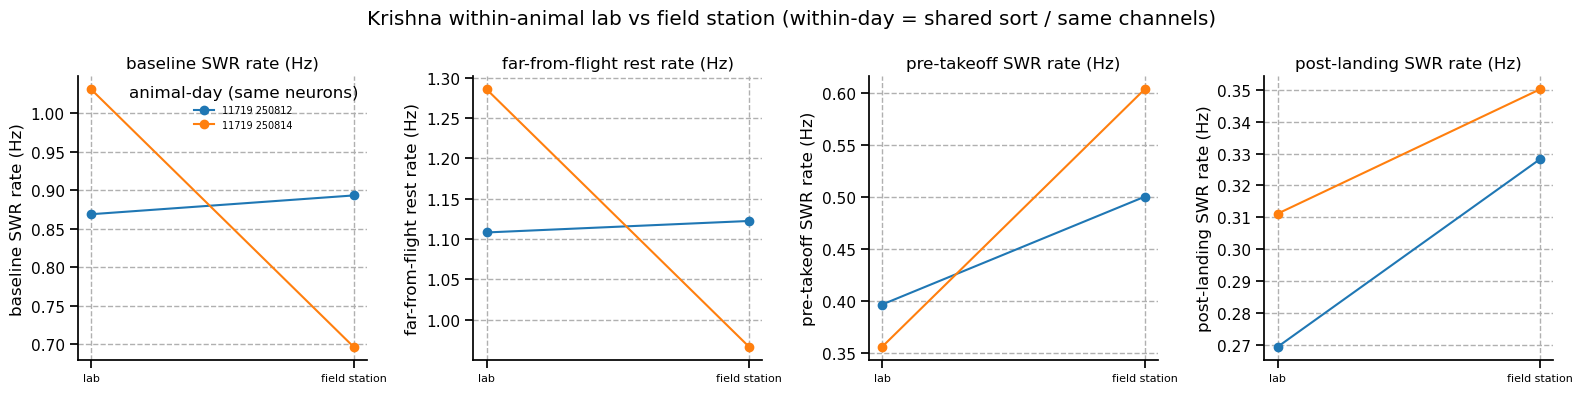

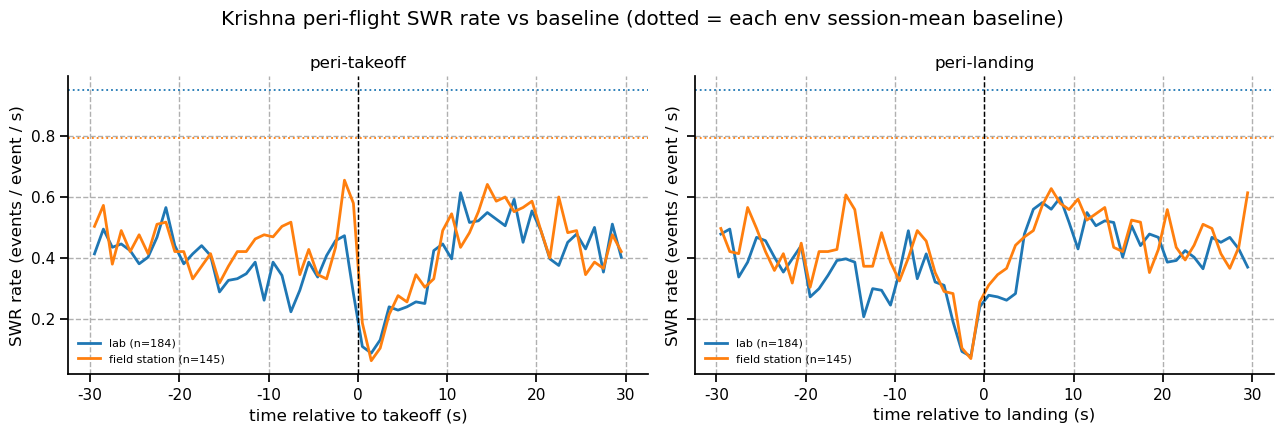

  bat   date           env  baseline  far_rest  med_dur_ms  pre_rate  post_rate  pre_enrich  post_enrich
11719 250812 field station     0.893     1.122      42.064     0.500      0.328       0.560        0.368
11719 250812           lab     0.869     1.108      44.285     0.396      0.269       0.439        0.310
11719 250813           lab     1.123     1.204      45.889     0.810      0.317       0.721        0.283
11719 250814 field station     0.697     0.966      44.111     0.603      0.350       0.866        0.503
11719 250814           lab     1.031     1.286      45.498     0.356      0.311       0.345        0.302
\nWhy peri-flight rate < baseline: the whole-session baseline is dominated by far-from-flight quiescent\nrest (far_rest ~1-1.5 Hz, the densest SWR epochs), while the +-3 s peri-flight windows abut the\nmovement-suppression dip (in-flight SWR rate ~0.1 Hz). So enrichment<1 = ripples are suppressed near\nflights relative to the rest-dominated session mean.


In [29]:
# --- Within-animal lab vs field station (Krishna: both envs, same day/neurons) ---
from digitalbat.datasets.defaults import KRISHNA_SESSION_NAMES
import collections
def krishna_env(s):
    return 'field station' if '_fs' in s else 'lab'

krip = {s: bool(glob.glob(f'{PARENT}/RPL_converted/{s}/RPL_probe*.mat')) for s in KRISHNA_SESSION_NAMES}
have = [s for s, v in krip.items() if v]
print(f'Krishna sessions with SWR (RPL) data: {len(have)}/{len(KRISHNA_SESSION_NAMES)}')
byday = collections.defaultdict(set)
for s in KRISHNA_SESSION_NAMES:
    byday[(s.split('_')[2], s.split('_')[3])].add(krishna_env(s))
pairable = [(b, d) for (b, d), e in sorted(byday.items()) if {'lab', 'field station'} <= e]
print('animal-days with BOTH lab & field-station envs (within-animal pairs once SWR exists):')
for b, d in pairable:
    print(f'  bat {b} {d}: {sorted(byday[(b, d)])}')

if not have:
    print('\\nNo SWR timestamps for any Krishna session -> within-animal comparison skipped.')
    print('To enable: build RPL_converted/<session>/RPL_probe*.mat (RPL_out.table with fields')
    print('t, dur in seconds, behavior time frame) for the sessions above, then re-run this cell.')
else:
    WIN_K, BW_K = 30.0, 1.0
    bins_k = np.arange(-WIN_K, WIN_K + BW_K, BW_K); ctr_k = bins_k[:-1] + BW_K / 2
    rows = []
    land_diffs = {'lab': [], 'field station': []}; n_land = {'lab': 0, 'field station': 0}
    toff_diffs = {'lab': [], 'field station': []}; n_toff = {'lab': 0, 'field station': 0}
    base_by_env = {'lab': [], 'field station': []}
    for s in have:
        st, sp = load_flight_bouts(s); swr_t, dur = load_swr_events(s)
        if len(st) == 0 or len(swr_t) == 0:
            continue
        swr_t = np.sort(swr_t); span = swr_t.max() - swr_t.min(); env = krishna_env(s)
        base = len(swr_t) / span if span > 0 else np.nan
        pre = (np.searchsorted(swr_t, st) - np.searchsorted(swr_t, st - W_PERI)).sum() / (len(st) * W_PERI)
        post = (np.searchsorted(swr_t, sp + W_PERI) - np.searchsorted(swr_t, sp)).sum() / (len(st) * W_PERI)
        # far-from-flight rest rate (>10 s from any flight edge): the high-SWR quiescent reference
        far_cnt = len(swr_t); near = 0.0
        for b, e in zip(st, sp):
            far_cnt -= np.searchsorted(swr_t, e + 10) - np.searchsorted(swr_t, b - 10); near += (e - b + 20)
        far = far_cnt / max(span - near, 1e-9)
        rows.append(dict(session=s, bat=s.split('_')[2], date=s.split('_')[3], env=env,
                         baseline=base, far_rest=far, med_dur_ms=np.median(dur) * 1000,
                         pre_rate=pre, post_rate=post, pre_enrich=pre / base, post_enrich=post / base))
        for spp in sp:
            land_diffs[env].append(swr_t[(swr_t >= spp - WIN_K) & (swr_t <= spp + WIN_K)] - spp)
        for stt in st:
            toff_diffs[env].append(swr_t[(swr_t >= stt - WIN_K) & (swr_t <= stt + WIN_K)] - stt)
        n_land[env] += len(sp); n_toff[env] += len(st); base_by_env[env].append(base)
    kdf = pd.DataFrame(rows)
    g = kdf.groupby(['bat', 'date', 'env']).mean(numeric_only=True).reset_index()

    # within-animal paired metrics: one line per animal-day (within-day = shared sort, same channels)
    METR = [('baseline', 'baseline SWR rate (Hz)'), ('far_rest', 'far-from-flight rest rate (Hz)'),
            ('pre_rate', 'pre-takeoff SWR rate (Hz)'), ('post_rate', 'post-landing SWR rate (Hz)')]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, (col, lab) in zip(axes, METR):
        piv = g.pivot_table(index=['bat', 'date'], columns='env', values=col)
        for (b, d), r in piv.dropna().iterrows():
            ax.plot(['lab', 'field station'], [r['lab'], r['field station']], 'o-', label=f'{b} {d}')
        ax.set(title=lab, ylabel=lab); ax.tick_params(axis='x', labelsize=8)
    axes[0].legend(fontsize=7, title='animal-day (same neurons)')
    fig.suptitle('Krishna within-animal lab vs field station (within-day = shared sort / same channels)')
    fig.tight_layout(); plt.show()

    # peri-flight PSTH overlay (takeoff & landing) + per-env baseline (dotted): peri rate sits BELOW baseline
    def _psth_panel(ax, diffs, ncnt, align):
        for env, c in [('lab', 'tab:blue'), ('field station', 'tab:orange')]:
            dd = np.concatenate(diffs[env]) if diffs[env] else np.zeros(0)
            ax.plot(ctr_k, np.histogram(dd, bins=bins_k)[0] / (max(ncnt[env], 1) * BW_K),
                    color=c, lw=2, label=f'{env} (n={ncnt[env]})')
            ax.axhline(np.mean(base_by_env[env]), color=c, ls=':', lw=1.3)
        ax.axvline(0, color='k', ls='--', lw=1)
        ax.set(xlabel=f'time relative to {align} (s)', ylabel='SWR rate (events / event / s)',
               title=f'peri-{align}')
        ax.legend(fontsize=8)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    _psth_panel(axes[0], toff_diffs, n_toff, 'takeoff')
    _psth_panel(axes[1], land_diffs, n_land, 'landing')
    fig.suptitle('Krishna peri-flight SWR rate vs baseline (dotted = each env session-mean baseline)')
    fig.tight_layout(); plt.show()
    print(g[['bat', 'date', 'env', 'baseline', 'far_rest', 'med_dur_ms',
             'pre_rate', 'post_rate', 'pre_enrich', 'post_enrich']].round(3).to_string(index=False))
    print('\\nWhy peri-flight rate < baseline: the whole-session baseline is dominated by '
          'far-from-flight quiescent\\nrest (far_rest ~1-1.5 Hz, the densest SWR epochs), while the '
          '+-3 s peri-flight windows abut the\\nmovement-suppression dip (in-flight SWR rate ~0.1 Hz). '
          'So enrichment<1 = ripples are suppressed near\\nflights relative to the rest-dominated session mean.')

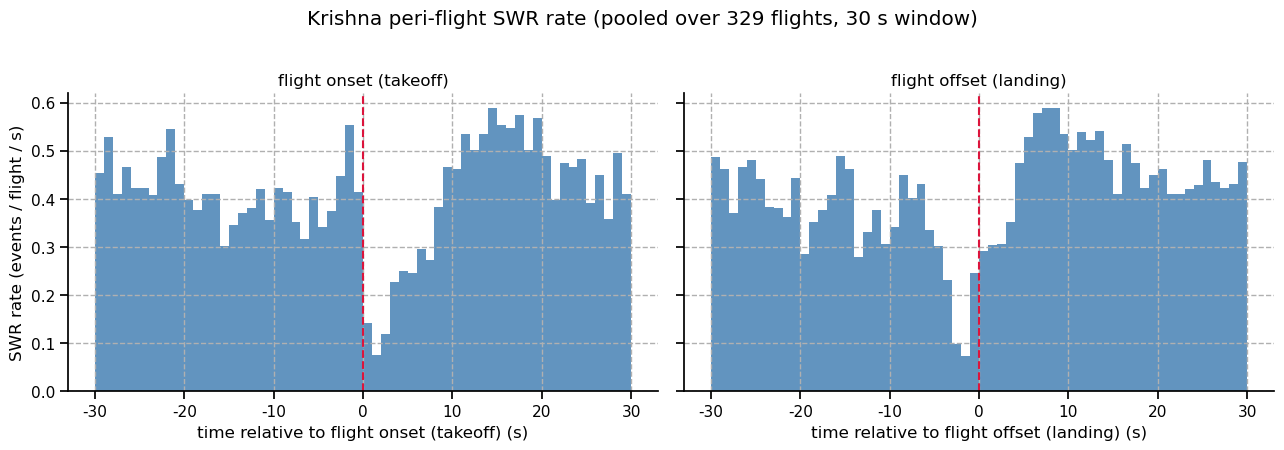

In [30]:
# --- Krishna peri-flight SWR rate (±30 s), takeoff & landing ---
# Mirrors the Dataset 1-3 peri-flight PSTH (events/flight/s), pooled over all Krishna
# sessions that have both ripple and behavior data.
KWIN, KBW = 30.0, 1.0
kbins = np.arange(-KWIN, KWIN + KBW, KBW); kctr = kbins[:-1] + KBW / 2
k_sessions = [s for s in KRISHNA_SESSION_NAMES
              if glob.glob(f'{PARENT}/RPL_converted/{s}/RPL_probe*.mat')
              and glob.glob(f'{PARENT}/{s}/Extracted_Behavior_*.mat')]
k_toff, k_land, k_nfl = [], [], 0
for s in k_sessions:
    st, sp = load_flight_bouts(s); swr_t, _ = load_swr_events(s)
    if len(st) == 0 or len(swr_t) == 0:
        continue
    swr_t = np.sort(swr_t)
    k_toff.append(peri_event_diffs(st, swr_t, KWIN))
    k_land.append(peri_event_diffs(sp, swr_t, KWIN))
    k_nfl += len(st)
if k_nfl:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    for ax, diffs, lab in [(axes[0], k_toff, 'flight onset (takeoff)'),
                           (axes[1], k_land, 'flight offset (landing)')]:
        d = np.concatenate(diffs) if diffs else np.zeros(0)
        ax.bar(kctr, np.histogram(d, bins=kbins)[0] / (k_nfl * KBW), width=KBW,
               color='steelblue', alpha=0.85)
        ax.axvline(0, color='crimson', ls='--', lw=1.5); ax.set(xlabel=f'time relative to {lab} (s)', title=lab)
    axes[0].set_ylabel('SWR rate (events / flight / s)')
    fig.suptitle(f'Krishna peri-flight SWR rate (pooled over {k_nfl} flights, {KWIN:.0f} s window)', y=1.02)
    fig.tight_layout(); plt.show()
else:
    print('No Krishna sessions with both ripple + behavior data.')

## Task 5 — SWR dynamics over the course of a session

Do SWRs wax or wane within a session? Tested **session-aware**: (a) overall SWR
rate across session time (10 equal-time bins per session) — per-session Spearman of
rate vs time-bin, aggregated across sessions (Wilcoxon vs 0); (b) peri-flight SWR
rate vs within-session **flight number** — per-session Spearman → Wilcoxon, plus an
LMM `rate ~ flight_num + (1 | subject/session)`. (Flight number and absolute time
are monotonically related within a session, so they give the same rank statistic;
the overlaid curves are descriptive, the tests are session-level.)

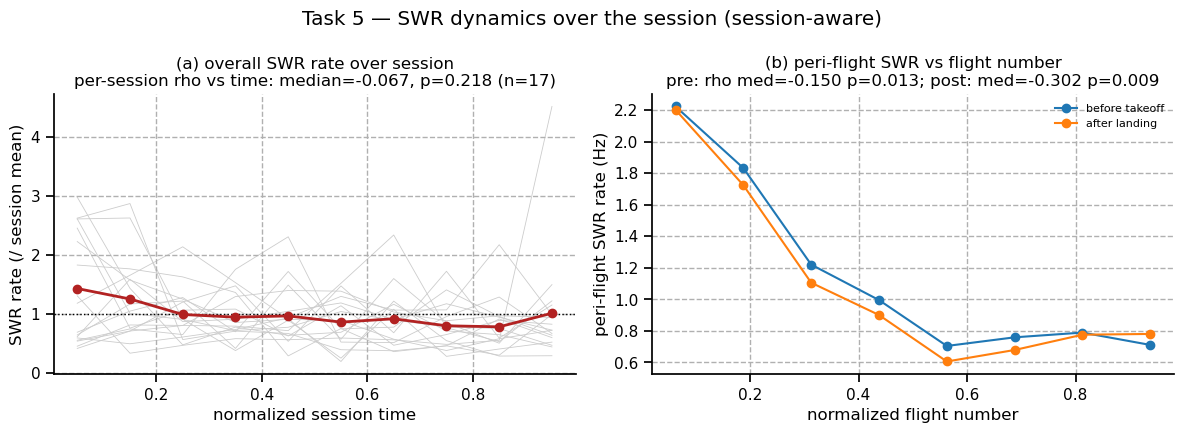

LMM pre_rate ~ flight_num + (1|bat/session): beta=-0.01434, se=0.00108, z=-13.25, p=0.000


In [31]:
# --- SWR dynamics over the session (session-aware) ---
# flight_num / flight_frac (normalized flight number) are set in the foundation cell.
import statsmodels.formula.api as smf, warnings

# (a) overall SWR rate across session time (deciles), per session -> Wilcoxon
NBIN = 10; over_rhos, curves = [], []
for sess, t in swr_times_by_session.items():
    if len(t) < 3 * NBIN:
        continue
    lo, hi = t.min(), t.max(); edges = np.linspace(lo, hi, NBIN + 1); bw = (hi - lo) / NBIN
    rate = np.histogram(t, bins=edges)[0] / bw
    over_rhos.append(spearmanr(np.arange(NBIN), rate)[0]); curves.append(rate / np.mean(rate))
over_rhos = np.array(over_rhos); _, p_over = wilcoxon_safe(over_rhos); curves = np.array(curves)

# (b) peri-flight SWR rate vs flight number, per session -> Wilcoxon + LMM
pre_rhos, post_rhos = [], []
for sess, d in flights.groupby('session'):
    if len(d) >= 8:
        pre_rhos.append(spearmanr(d['flight_num'], d['pre_rate'])[0])
        post_rhos.append(spearmanr(d['flight_num'], d['post_rate'])[0])
pre_rhos, post_rhos = np.array(pre_rhos), np.array(post_rhos)
_, p_pre = wilcoxon_safe(pre_rhos); _, p_post = wilcoxon_safe(post_rhos)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    lm = smf.mixedlm('pre_rate ~ flight_num', flights.dropna(subset=['pre_rate']), groups=flights['bat'],
                     re_formula='1', vc_formula={'session': '0 + C(session)'}).fit(
                     reml=True, method='lbfgs', maxiter=400)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
xb = (np.arange(NBIN) + 0.5) / NBIN
for c in curves:
    axes[0].plot(xb, c, color='0.8', lw=0.6, zorder=1)
axes[0].plot(xb, np.nanmean(curves, axis=0), 'o-', color='firebrick', lw=2, zorder=3)
axes[0].axhline(1, color='k', ls=':', lw=1)
axes[0].set(xlabel='normalized session time', ylabel='SWR rate (/ session mean)',
            title=f'(a) overall SWR rate over session\nper-session rho vs time: median={np.nanmedian(over_rhos):.3f}, '
                  f'p={p_over:.3f} (n={len(over_rhos)})')
fb = np.linspace(0, 1, 9); ff = flights['flight_frac'].values
idx = np.clip(np.digitize(ff, fb) - 1, 0, len(fb) - 2)
for col, lab, cc in [('pre_rate', 'before takeoff', 'tab:blue'), ('post_rate', 'after landing', 'tab:orange')]:
    v = flights[col].values
    mu = [v[idx == k].mean() for k in range(len(fb) - 1)]
    axes[1].plot((fb[:-1] + fb[1:]) / 2, mu, 'o-', color=cc, label=lab)
axes[1].legend(fontsize=8)
axes[1].set(xlabel='normalized flight number', ylabel='peri-flight SWR rate (Hz)',
            title=f'(b) peri-flight SWR vs flight number\npre: rho med={np.nanmedian(pre_rhos):.3f} p={p_pre:.3f}; '
                  f'post: med={np.nanmedian(post_rhos):.3f} p={p_post:.3f}')
fig.suptitle('Task 5 — SWR dynamics over the session (session-aware)'); fig.tight_layout(); plt.show()
print(f'LMM pre_rate ~ flight_num + (1|bat/session): beta={lm.params["flight_num"]:.5f}, '
      f'se={lm.bse["flight_num"]:.5f}, z={lm.params["flight_num"]/lm.bse["flight_num"]:.2f}, '
      f'p={lm.pvalues["flight_num"]:.3f}')

## Task 2 — Decoding error & Jacobian magnification vs peri-flight SWRs

Using the selected **joint masked transformer** (`JointMaskedTransformer`,
17-session checkpoint), we compute per-test-flight decode error as both the **3-D
Euclidean reconstruction error** (mean per-timestep) and the **3-D Fréchet
distance** (whole-trajectory shape mismatch), plus the **Jacobian magnification**
(`log Σσ` of the encode latent's Jacobian w.r.t. position — local representational
stretch, computed on the shared indoor room, Datasets 1 & 3). We then ask whether a
flight preceded / followed by more SWRs is decoded better/worse or shows different
magnification — first with simple correlations, then controlling for flight cluster
(in-domain/OOD, within-cluster demeaning) and finally a linear mixed model with
nested `subject / trajectory-cluster` random effects.

In [ ]:
# --- Load joint model, decode test flights, validate flight_path_index alignment ---
import torch
from digitalbat.datasets.defaults import make_data_config
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.joint import JointMaskedTransformer
from digitalbat.utility.utils import set_random_state

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 0
import pickle as _pkl
from digitalbat.datasets.kinematics import make_joint_dataloaders, KIN_BEHAVIOR_DIM
_JV2 = os.path.expanduser('~/Documents/code/digitalbat/notebooks/out/joint/joint_optuna_v2.pkl')
_JSTART = dict(num_layers=4, latent_dim=64, ff_dim=64, dropout=0.2, lr=3e-3, weight_decay=1e-2,
               w_encode=1.0, w_decode=1.0, w_aux=1.0, lam=1.0, pos_weight=1.0, use_kinematics=False)
_jbp = dict(_JSTART); _jbp.update(max(
    (t for t in _pkl.load(open(_JV2, 'rb')).trials
     if t.state.name == 'COMPLETE' and t.params.get('use_kinematics') is False),
    key=lambda t: t.value).params)
_jbp['use_kinematics'] = False                            # force position-only (dim-3)
_use_kin = bool(_jbp['use_kinematics']); _bd = KIN_BEHAVIOR_DIM if _use_kin else 3
SELECTED = dict(num_layers=int(_jbp['num_layers']), latent_dim=_jbp['latent_dim'],
                ff_dim=_jbp['ff_dim'], dropout=_jbp['dropout'])
CKPT = os.path.expanduser('~/Documents/code/digitalbat/notebooks/out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth')  # cross_1000 production model (encode+decode+cross, tuned 1000ep; joint-encode-decode.ipynb §6.10)

import io, contextlib
data_config = make_data_config(session_names=FLIGHT_SESSIONS)
with contextlib.redirect_stdout(io.StringIO()):
    dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
session_to_room = {s: session_room(s) for s in FLIGHT_SESSIONS}
_dlp, _dlk, _, joint_meta = make_joint_dataloaders(data_config)  # joint-loader z-score stats (IMU-on universe)
joint_loaders = _dlk if _use_kin else _dlp

set_random_state(SEED)
joint_model = JointMaskedTransformer(
    unit_num_dict, behavior_dim=_bd, latent_dim=SELECTED['latent_dim'], num_heads=4, ff_dim=SELECTED['ff_dim'],
    num_layers=SELECTED['num_layers'], dropout=SELECTED['dropout'], input_transform='identity',
    session_to_room=session_to_room)
joint_model.load_state_dict(torch.load(CKPT, map_location=device))
joint_model = joint_model.to(device).eval()

from digitalbat.decoding import discrete_frechet

def decoding_records(model, loaders, meta, device):
    rows = []
    for s, sd in loaders.items():
        bm = np.asarray(meta['behavior_mean'][s]).squeeze()[:3]
        bs = np.asarray(meta['behavior_std'][s]).squeeze()[:3]
        for b in sd:
            m = b.mask.to(device); bt = b.mask.clone().to(device); nt = torch.zeros_like(bt)
            with torch.no_grad():
                _, beh_pred, _ = model(s, b.spike.to(device), b.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy()*bs[None,None,:]+bm[None,None,:]
            yt = b.behavior[:,:,:3].numpy()*bs[None,None,:]+bm[None,None,:]
            mk = b.mask.numpy().astype(bool); B, T = mk.shape
            fpi = np.broadcast_to(b.flight_path_index.numpy()[:,None], (B,T))
            tix = np.broadcast_to(np.arange(T)[None,:], (B,T))
            ytf, ypf, fpf, tif = yt[mk], yp[mk], fpi[mk], tix[mk]
            err3 = np.sqrt(((ytf-ypf)**2).sum(1))
            for i in range(len(err3)):
                rows.append(dict(session=s, flight_id=int(fpf[i]), t_idx=int(tif[i]),
                                 x_true=ytf[i,0], y_true=ytf[i,1], z_true=ytf[i,2],
                                 x_pred=ypf[i,0], y_pred=ypf[i,1], z_pred=ypf[i,2], err_3d=float(err3[i])))
    return pd.DataFrame(rows)

def frechet_per_flight(df):
    rows = []
    for (s, fid), g in df.groupby(['session','flight_id'], sort=False):
        g = g.sort_values('t_idx')
        tr = g[['x_true','y_true','z_true']].to_numpy(float)
        pr = g[['x_pred','y_pred','z_pred']].to_numpy(float)
        rows.append(dict(session=s, flight_id=int(fid), frechet_3d=float(discrete_frechet(tr, pr))))
    return pd.DataFrame(rows)

dec_ts_df = decoding_records(joint_model, joint_loaders['test'], joint_meta, device)
dec_fl = dec_ts_df.groupby(['session','flight_id']).agg(err_3d=('err_3d','mean'),
                                                        n_t=('err_3d','size')).reset_index()
dec_fl = dec_fl.merge(frechet_per_flight(dec_ts_df), on=['session','flight_id'])  # per-flight 3-D Fréchet

# The joint (IMU-on) loaders truncate each session at the IMU end time (data.py: global_t_end
# = min(bhv_t[-1], imu_t[-1])), dropping a temporal *suffix* of flights. Because flights are
# enumerated cluster-major (not by time), that shifts their flight_path_index vs the (IMU-off)
# flight_df / base dataloaders. Rebuild the local(truncated) -> true flight_path_index map from
# the IMU end time: the kept flights are exactly flight_df's flights with start_t <= imu_end, in
# the same cluster-major order, so their position in that list is the loader's local flight id.
def _imu_end_time(session):
    imu = loadmat(glob.glob(f'{PARENT}/{session}/IMU_data.mat')[0])
    return float(imu['NP_imu'][0][0]['t'][0, :][-1])

_idmap_parts = []
for _s in FLIGHT_SESSIONS:
    _kept = (flight_df[(flight_df.session == _s) & (flight_df.start_t <= _imu_end_time(_s))]
             .sort_values('flight_path_index'))
    _idmap_parts.append(_kept[['session','flight_path_index']].assign(local_id=np.arange(len(_kept))))
joint_id_map = pd.concat(_idmap_parts, ignore_index=True)   # (session, local_id) -> true flight_path_index

def remap_joint_ids(df, id_col='flight_id'):
    '''Replace joint-loader local flight ids with flight_df's true flight_path_index
    (undo the per-session IMU-end truncation shift). Unmapped flights are dropped.'''
    out = df.merge(joint_id_map.rename(columns={'local_id': id_col, 'flight_path_index': '_true'}),
                   on=['session', id_col], how='left')
    n_bad = int(out['_true'].isna().sum())
    if n_bad:
        print(f'  WARNING: dropping {n_bad} joint flights unmapped to flight_df (IMU-truncation boundary)')
    out = out.dropna(subset='_true').copy()
    out[id_col] = out['_true'].astype(int)
    return out.drop(columns='_true')

dec_fl = remap_joint_ids(dec_fl)                            # local -> true flight_path_index

# alignment check: flight_df takeoff == decode first-timestep truth, at the REMAPPED id
_first = (dec_ts_df.sort_values('t_idx').groupby(['session','flight_id'])[['x_true','y_true','z_true']]
          .first().reset_index())
_chk = remap_joint_ids(_first).merge(flight_df, left_on=['session','flight_id'],
                                     right_on=['session','flight_path_index'])
_d = np.sqrt((_chk.x_true-_chk.toff_x)**2+(_chk.y_true-_chk.toff_y)**2+(_chk.z_true-_chk.toff_z)**2)
print(f'decode median err_3d={dec_ts_df.err_3d.median():.3f} m, frechet_3d={dec_fl.frechet_3d.median():.3f} m; '
      f'{len(dec_fl)} test flights; remap alignment max mismatch={_d.max():.4f} m')
assert _d.max() < 1e-6, 'remap failed: takeoff positions do not match flight_df'

In [ ]:
# --- Jacobian magnification per test flight (encode latent vs position; D1/D3) ---
from torch.nn.attention import SDPBackend, sdpa_kernel
JAC_TIME_STRIDE = 2   # subsample timesteps (per-flight mean is robust to this)
_basis = torch.eye(3, device=device); _jrec = []
if device.type == 'cuda':
    with sdpa_kernel(SDPBackend.MATH):
        for s, sd in dataloaders['test'].items():
            if not s.startswith(('Dataset_1','Dataset_3')):
                continue                                   # shared indoor room only
            bm = np.asarray(meta_info_dict['behavior_mean'][s]).squeeze()[:3]
            bs = np.asarray(meta_info_dict['behavior_std'][s]).squeeze()[:3]
            for batch in sd:
                for b in range(batch.behavior.shape[0]):
                    beh_b = batch.behavior[b:b+1].to(device); spk_b = batch.spike[b:b+1].to(device)
                    mask_b = batch.mask[b:b+1].to(device); fid = int(batch.flight_path_index[b].item())
                    valid_t = torch.where(mask_b[0] == 1.0)[0]
                    if len(valid_t) < 2:
                        continue
                    nt_b = mask_b.clone(); bt_b = torch.zeros_like(mask_b)
                    def _latent(p3, t_int):
                        bl = beh_b.clone(); bl[0, t_int, :3] = p3
                        _, _, xfull = joint_model(s, spk_b, bl, mask_b, nt_b, bt_b)
                        return xfull[0, t_int]
                    for ti in range(0, len(valid_t), JAC_TIME_STRIDE):
                        t_int = int(valid_t[ti].item()); pos3 = beh_b[0, t_int, :3].detach().clone()
                        f = lambda p3, _t=t_int: _latent(p3, _t)
                        J = torch.stack([torch.autograd.functional.jvp(f, (pos3,), v=(_basis[k],))[1]
                                         for k in range(3)], dim=1)
                        _jrec.append((s, fid, float(torch.linalg.svdvals(J).log().sum())))
    jac_df = pd.DataFrame(_jrec, columns=['session','flight_id','log_mag'])
    jac_fl = jac_df.groupby(['session','flight_id']).log_mag.mean().reset_index()
    print(f'Jacobian: {len(jac_df)} samples over {len(jac_fl)} D1/D3 test flights; '
          f'log_mag median={jac_df.log_mag.median():.2f}')
else:
    jac_fl = pd.DataFrame(columns=['session','flight_id','log_mag'])
    print('no CUDA - skipping Jacobian')

Jacobian: 3132 samples over 232 D1/D3 test flights; log_mag median=-1.47


281 test flights with decode; 232 with Jacobian


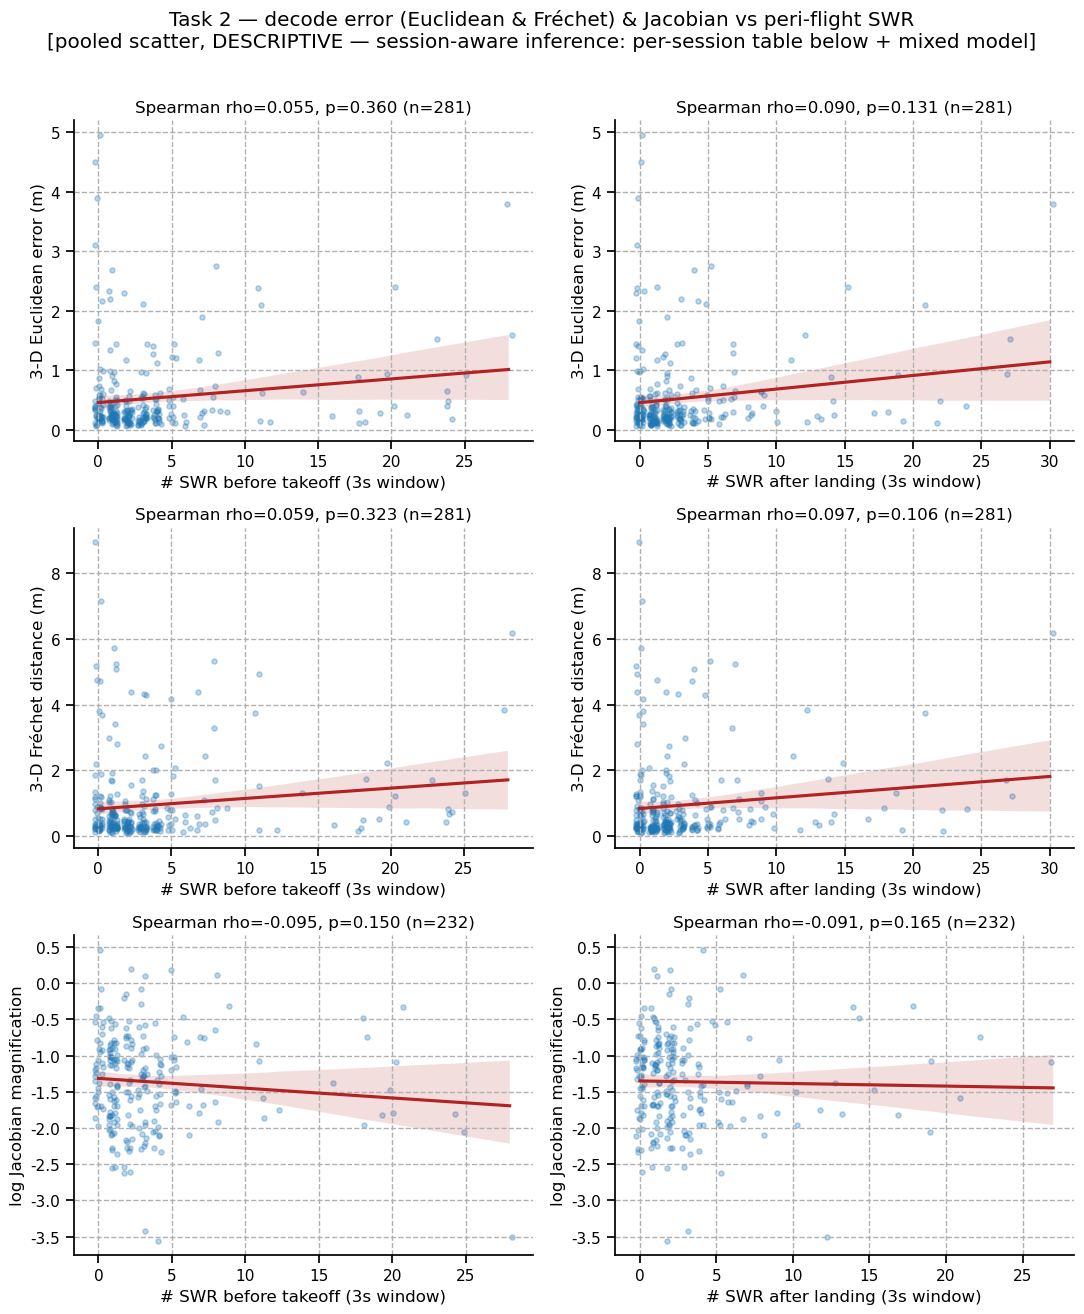

                     pair  n_sess  median_rho     p
     err_3d ~ pre_takeoff      17       0.172 0.031
    err_3d ~ post_landing      17       0.116 0.207
 frechet_3d ~ pre_takeoff      17       0.205 0.020
frechet_3d ~ post_landing      17       0.067 0.404
    log_mag ~ pre_takeoff      13      -0.131 0.191
   log_mag ~ post_landing      13      -0.082 0.168


In [ ]:
# --- Relate decode error / magnification to peri-flight SWRs ---
mf = flights.merge(dec_fl, left_on=['session','flight_path_index'],
                   right_on=['session','flight_id'], how='inner')
mf = mf.merge(jac_fl, left_on=['session','flight_path_index'],
              right_on=['session','flight_id'], how='left', suffixes=('','_j'))
print(f'{len(mf)} test flights with decode; {mf.log_mag.notna().sum()} with Jacobian')

# three decode/representation metrics x two peri-flight SWR sides
METRICS = [('err_3d', '3-D Euclidean error (m)'),
           ('frechet_3d', '3-D Fréchet distance (m)'),
           ('log_mag', 'log Jacobian magnification')]
SIDES2 = [('pre_takeoff', 'SWR before takeoff'), ('post_landing', 'SWR after landing')]

fig, axes = plt.subplots(3, 2, figsize=(11, 13))
for r, (ycol, ylab) in enumerate(METRICS):
    for c, (xcol, xlab) in enumerate(SIDES2):
        ax = axes[r, c]; d = mf.dropna(subset=[xcol, ycol])
        sns.regplot(data=d, x=xcol, y=ycol, ax=ax, x_jitter=0.3, scatter_kws=dict(s=14, alpha=0.3),
                    line_kws=dict(color='firebrick'))
        rho, p = spearmanr(d[xcol], d[ycol])
        ax.set(xlabel=f'# {xlab} ({W_PERI:g}s window)', ylabel=ylab,
               title=f'Spearman rho={rho:.3f}, p={p:.3f} (n={len(d)})')
fig.suptitle('Task 2 — decode error (Euclidean & Fréchet) & Jacobian vs peri-flight SWR\n'
             '[pooled scatter, DESCRIPTIVE — session-aware inference: per-session table below + mixed model]', y=1.01)
fig.tight_layout(); plt.show()

# session-level: per-session Spearman, tested across sessions (sign vs 0)
recs = []
for ycol, _ in METRICS:
    for xcol, _ in SIDES2:
        rhos = []
        for s, d in mf.dropna(subset=[xcol,ycol]).groupby('session'):
            if d[xcol].nunique() > 2 and len(d) >= 6:
                rhos.append(spearmanr(d[xcol], d[ycol])[0])
        rhos = np.array(rhos); _, pp = wilcoxon_safe(rhos)
        recs.append(dict(pair=f'{ycol} ~ {xcol}', n_sess=len(rhos),
                         median_rho=np.nanmedian(rhos), p=pp))
print(pd.DataFrame(recs).round(3).to_string(index=False))

### Task 2 control — are these relationships confounded by flight cluster?

The raw correlations could be driven by cluster identity: **in-domain** flights
(cluster also seen in train/valid) are decoded better *and* may be preceded by
fewer SWRs, while **OOD** flights (cluster unique to test) are decoded worse. If
so, a correlation is a between-cluster artefact, not a within-cluster SWR→metric
link. We run the same control for **all three metrics** (3-D Euclidean error, 3-D
Fréchet distance, log Jacobian magnification): (1) confirm the confound
(in-domain vs OOD differ in each metric and in `pre_takeoff`); (2) within-domain
correlations; (3) **partial** Spearman controlling for domain / cluster size;
(4) **within-cluster demeaned** correlation and a **per-session partial** test.

**Two complementary cluster controls.**
- *Within-cluster (demeaned).* For every `(session, trajectory-cluster)` group
  with ≥2 test flights, subtract the group mean from both the metric **and** the
  SWR count, then correlate the residuals. This removes **all** between-cluster
  variance (cluster identity, in-domain/OOD status, the cluster's mean error and
  mean SWR count) — it asks only: *when one flight has more pre-flight SWRs than
  is typical for its own trajectory, is its error higher than typical for that
  trajectory?* Strictest cluster control, but it discards single-flight clusters
  and pools all sessions/bats into one correlation.
- *Per-session partial ρ.* Within each session, the partial Spearman of
  `(metric, SWR)` given only the **binary in-domain/OOD** label, then aggregated
  across sessions (Wilcoxon vs 0). This controls for the coarse domain dichotomy
  (not full cluster identity) but keeps every flight and respects session/bat
  structure.

They differ in *granularity of the control* (full per-cluster mean vs a 2-level
domain covariate) and *unit of inference* (one pooled correlation vs a
distribution of per-session estimates). The mixed model below unifies them: a
fixed SWR slope with nested random intercepts for `subject / trajectory-cluster`.

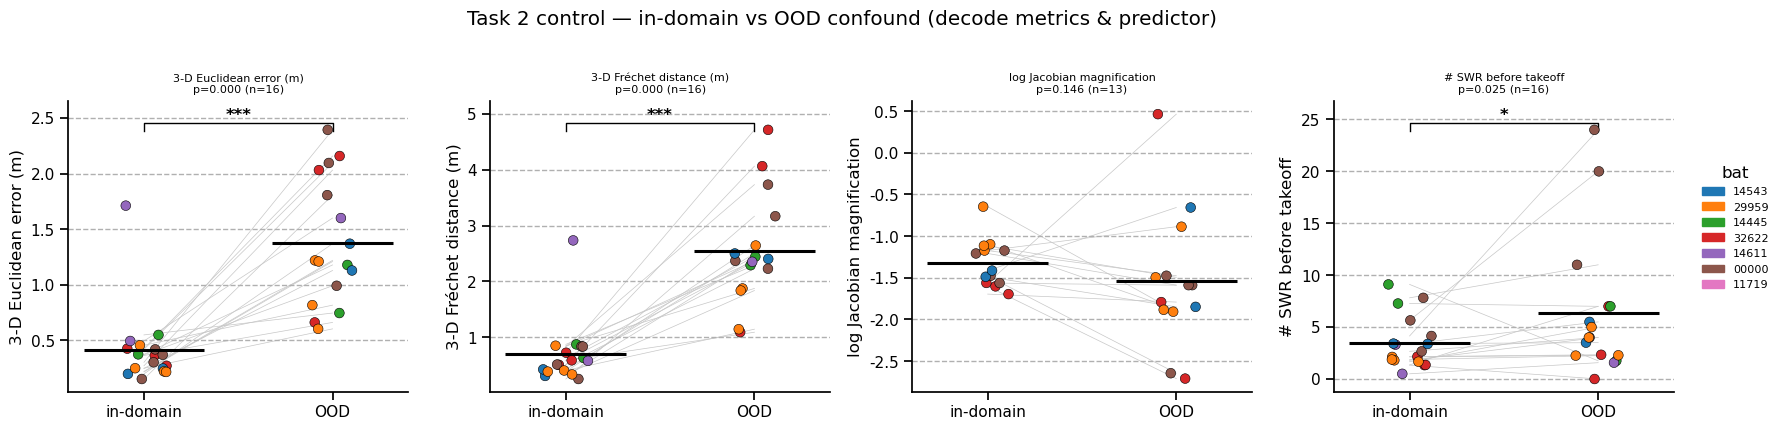

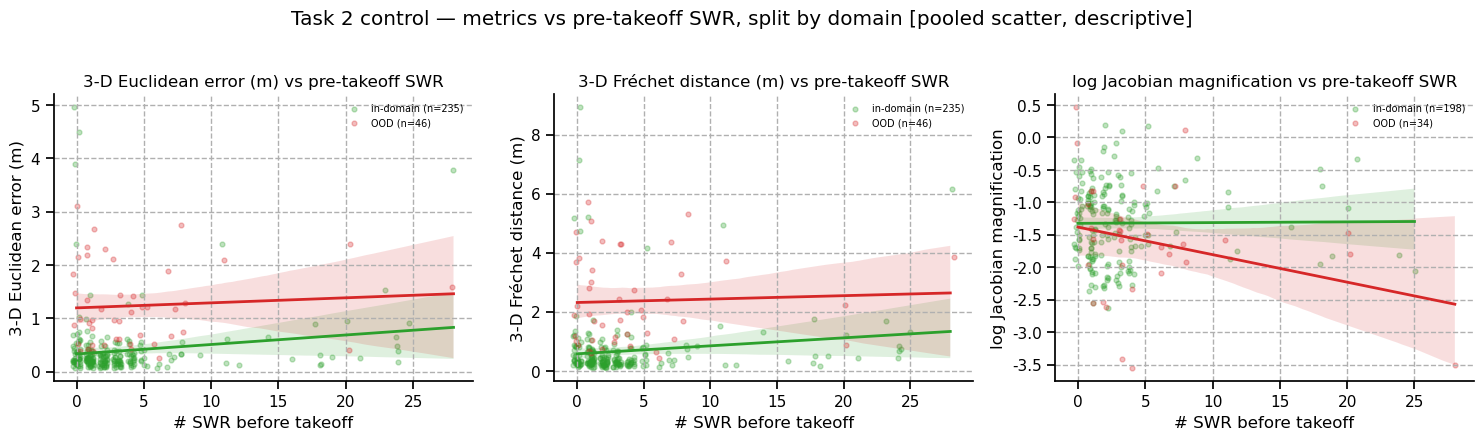

confound (means by domain):
  3-D Euclidean error (m)        in-domain=0.393  OOD=1.237
  3-D Fréchet distance (m)       in-domain=0.674  OOD=2.368
  log Jacobian magnification     in-domain=-1.320  OOD=-1.601
  # SWR before takeoff           in-domain=3.485  OOD=4.370

    metric         side   n  rho_in  rho_ood    raw  partial_dom  partial_clu  demean  demean_p  demean_n  psess_partial  psess_p  psess_n
    err_3d  pre_takeoff 281   0.006    0.009  0.055        0.008       -0.003   0.183     0.010       198          0.126    0.074       16
    err_3d post_landing 281   0.079    0.096  0.090        0.071        0.015   0.144     0.043       198          0.042    0.298       16
frechet_3d  pre_takeoff 281   0.013    0.007  0.059        0.013        0.002   0.173     0.015       198          0.130    0.117       16
frechet_3d post_landing 281   0.094    0.084  0.097        0.078        0.023   0.226     0.001       198         -0.005    0.528       16
   log_mag  pre_takeoff 232  -0.02

In [ ]:
# --- Control for flight cluster (in-domain vs OOD), all three metrics ---
from notebook_helpers import partial_r, spearman
indom = {s: set(int(x) for x in np.atleast_1d(meta_info_dict['flight_type_test_indomain'][s]))
         for s in dataloaders['test']}
mf['domain'] = np.where([int(c) in indom.get(s, set())
                         for s, c in zip(mf.session, mf.flight_type_index)], 'in-domain', 'OOD')

# Figure 1: in-domain vs OOD confound — each metric + the predictor (pre_takeoff)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (col, lab) in zip(axes[:3], METRICS):
    d = (mf.dropna(subset=[col]).groupby(['session','bat','domain'])[col].mean()
         .reset_index().rename(columns={col:'val', 'domain':'cond'}))
    session_contrast(ax, d, ['in-domain','OOD'], lab); ax.set_title(f'{lab}\n' + ax.get_title(), fontsize=8)
d = (mf.groupby(['session','bat','domain'])['pre_takeoff'].mean()
     .reset_index().rename(columns={'pre_takeoff':'val', 'domain':'cond'}))
session_contrast(axes[3], d, ['in-domain','OOD'], '# SWR before takeoff')
axes[3].set_title('# SWR before takeoff\n' + axes[3].get_title(), fontsize=8)
bat_legend(fig); fig.suptitle('Task 2 control — in-domain vs OOD confound (decode metrics & predictor)', y=1.02)
fig.tight_layout(); plt.show()

# Figure 2: each metric vs pre-takeoff SWR, split by domain
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (col, lab) in zip(axes, METRICS):
    for dom, c in [('in-domain','tab:green'), ('OOD','tab:red')]:
        dd = mf[mf.domain == dom].dropna(subset=[col])
        sns.regplot(data=dd, x='pre_takeoff', y=col, ax=ax, color=c, x_jitter=0.3,
                    scatter_kws=dict(s=12, alpha=0.3), line_kws=dict(lw=2), label=f'{dom} (n={len(dd)})')
    ax.legend(fontsize=7); ax.set(xlabel='# SWR before takeoff', ylabel=lab, title=f'{lab} vs pre-takeoff SWR')
fig.suptitle('Task 2 control — metrics vs pre-takeoff SWR, split by domain '
             '[pooled scatter, descriptive]', y=1.02)
fig.tight_layout(); plt.show()

def control_stats(col, side):
    d = mf.dropna(subset=[col, side]).copy()
    x, y = d[side].values.astype(float), d[col].values.astype(float)
    dom = (d['domain'] == 'OOD').astype(float).values
    di, do = d[d.domain=='in-domain'], d[d.domain=='OOD']
    out = dict(metric=col, side=side, n=len(d),
               rho_in=spearman(di[side], di[col]), rho_ood=spearman(do[side], do[col]),
               raw=spearman(x, y), partial_dom=partial_r(x, y, dom),
               partial_clu=partial_r(x, y, d['cluster_size'].values.astype(float)))
    g = d.groupby(['session','flight_type_index']); nn = g[col].transform('size'); s2 = d[nn >= 2].copy()
    if len(s2) > 5:
        s2['yd'] = s2[col] - g[col].transform('mean')[s2.index]
        s2['xd'] = s2[side] - g[side].transform('mean')[s2.index]
        out['demean'], out['demean_p'] = spearmanr(s2['xd'], s2['yd'])
    else:
        out['demean'], out['demean_p'] = np.nan, np.nan
    out['demean_n'] = len(s2)
    pr = []
    for s, dd in d.groupby('session'):
        if dd[side].nunique() > 2 and dd['domain'].nunique() > 1 and len(dd) >= 8:
            r = partial_r(dd[side].values.astype(float), dd[col].values.astype(float),
                          (dd.domain=='OOD').astype(float).values)
            if np.isfinite(r): pr.append(r)
    out['psess_partial'] = np.nanmedian(pr) if pr else np.nan
    out['psess_p'] = wilcoxon_safe(np.array(pr))[1] if len(pr) >= 3 else np.nan
    out['psess_n'] = len(pr)
    return out

print('confound (means by domain):')
for col, lab in METRICS:
    mm = mf.dropna(subset=[col]).groupby('domain')[col].mean().round(3)
    print(f'  {lab:30s} in-domain={mm.get("in-domain", np.nan):.3f}  OOD={mm.get("OOD", np.nan):.3f}')
print(f'  {"# SWR before takeoff":30s} in-domain={mf[mf.domain=="in-domain"].pre_takeoff.mean():.3f}  '
      f'OOD={mf[mf.domain=="OOD"].pre_takeoff.mean():.3f}\n')
ctrl = pd.DataFrame([control_stats(col, side) for col, _ in METRICS
                     for side in ['pre_takeoff','post_landing']])
print(ctrl.round(3).to_string(index=False))
print('\\ncolumns: rho_in/rho_ood/raw/partial_dom/partial_clu = POOLED across sessions '
      '(descriptive/confound illustration);')
print('         demean = within-(session,cluster) residual corr; psess_partial = SESSION-AWARE '
      '(per-session partial rho -> Wilcoxon). Primary inference = psess_partial + the mixed model (t2-lmm).')

### Task 2 — linear mixed model with nested random effects

To test the SWR→metric link while properly accounting for the nested data
structure, we fit `metric ~ #SWR + (1 | subject / session / trajectory-cluster)` —
random intercepts for **bat**, **session-within-bat**, and **trajectory-cluster
within session** — separately for each predictor (**pre-takeoff**, **post-landing**
SWR count) and each outcome (**3-D Euclidean error**, **3-D Fréchet distance**,
**log Jacobian magnification**). The fixed-effect slope β is the change in the
metric per additional peri-flight SWR, after absorbing per-bat, per-session and
per-trajectory baselines (so it isolates the within-trajectory effect the demeaned
correlation targeted, with session-respecting inference).

Decode error and Fréchet distance are positive and right-skewed, so we also fit
**log-transformed** versions and plot residual-vs-fitted diagnostics; if the raw
residuals are heteroscedastic (spread growing with the fitted value) the log fit is
preferred. Jacobian magnification is already log-scaled, so it is not transformed.

Each model also includes **normalized flight number** (`flight_frac`) as a
covariate, so the SWR→decoding effect is separated from the within-session decline
(Task 5); the table reports the SWR slope (`beta`/`p`) controlling session time and
the `flight_frac` slope (`beta_ff`/`p_ff`).

LMM  metric ~ #SWR + flight_frac + (1 | bat/session/trajectory_cluster)
  beta/p = peri-flight SWR (controlling session time); beta_ff/p_ff = normalized flight number
                          outcome    predictor   n   beta     se      z      p  beta_ff   p_ff  conv
            3-D Euclidean err (m)  pre_takeoff 281 0.0276 0.0079 3.4849 0.0005   0.2437 0.0797 False
            3-D Euclidean err (m) post_landing 281 0.0232 0.0084 2.7704 0.0056   0.2023 0.1467  True
            log 3-D Euclidean err  pre_takeoff 281 0.0335 0.0091 3.6825 0.0002   0.2018 0.2091  True
            log 3-D Euclidean err post_landing 281 0.0302 0.0097 3.1196 0.0018   0.1625 0.3118 False
                  3-D Fréchet (m)  pre_takeoff 281 0.0425 0.0092 4.5987 0.0000   0.6899 0.0045 False
                  3-D Fréchet (m) post_landing 281 0.0352 0.0156 2.2605 0.0238   0.6187 0.0172 False
                  log 3-D Fréchet  pre_takeoff 281 0.0379 0.0096 3.9689 0.0001   0.4223 0.0125 False
                  log 3-D

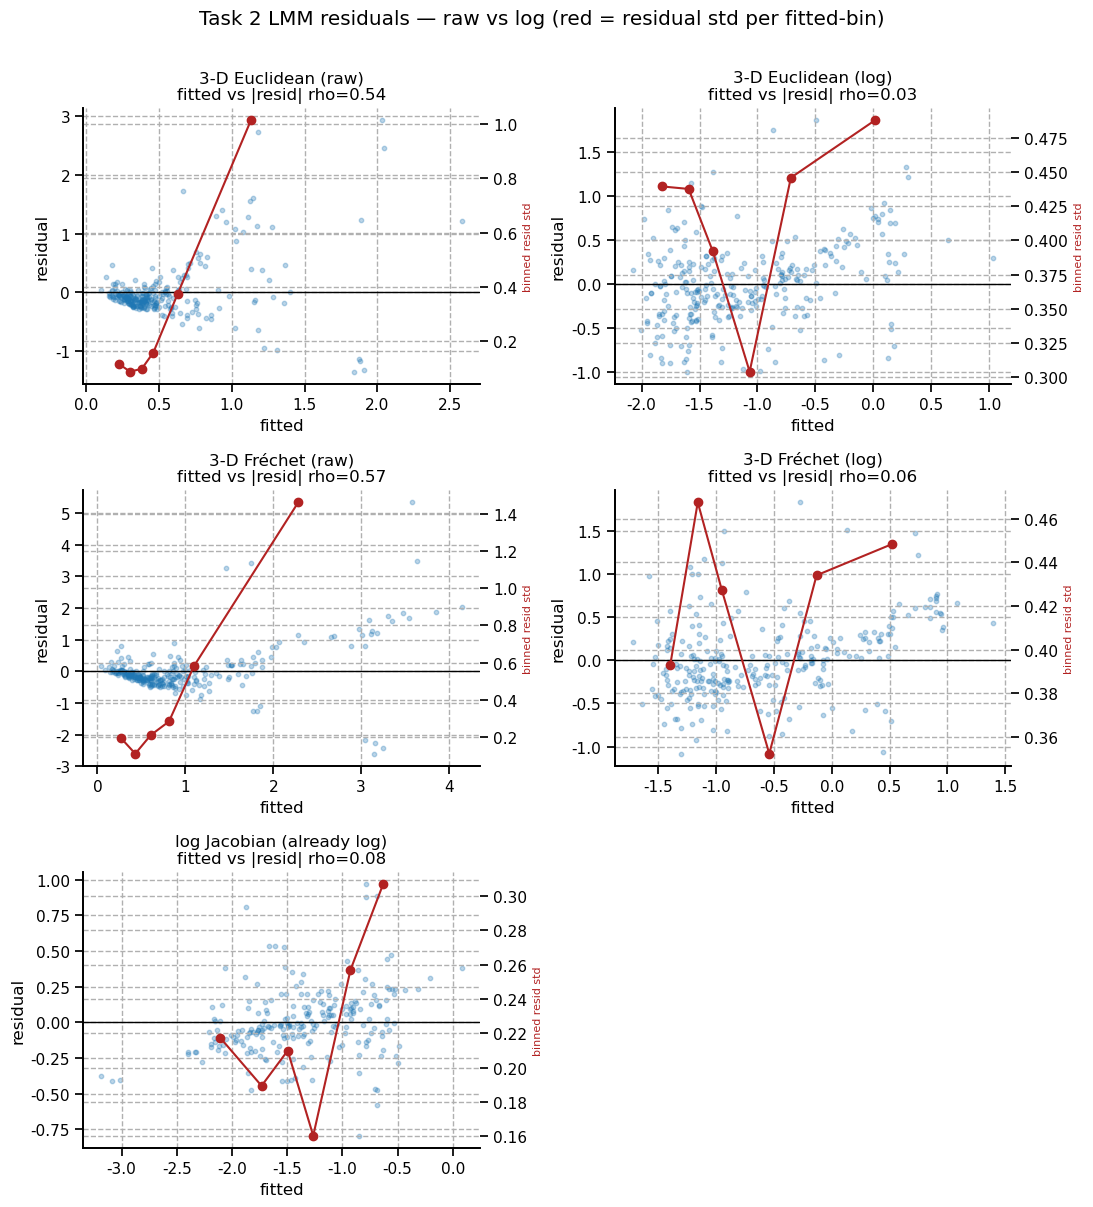

In [ ]:
# --- LMM: metric ~ #SWR + (1 | bat / session / trajectory_cluster) ---
import statsmodels.formula.api as smf
import warnings

mf['cluster_uid'] = mf['session'] + '__' + mf['flight_type_index'].astype(str)
mf['log_err_3d'] = np.log(mf['err_3d'])
mf['log_frechet_3d'] = np.log(mf['frechet_3d'])

OUTCOMES = [('err_3d', '3-D Euclidean err (m)'),
            ('log_err_3d', 'log 3-D Euclidean err'),
            ('frechet_3d', '3-D Fréchet (m)'),
            ('log_frechet_3d', 'log 3-D Fréchet'),
            ('log_mag', 'log Jacobian magnif (already log)')]

def fit_lmm(ycol, xcol):
    d = mf.dropna(subset=[ycol, xcol, 'bat', 'cluster_uid', 'flight_frac']).copy()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        # (1 | subject / session / trajectory-cluster): random intercepts for bat,
        # session-within-bat, and cluster-within-session (uids encode the nesting).
        # flight_frac (normalized flight number) added as a session-time covariate.
        m = smf.mixedlm(f'{ycol} ~ {xcol} + flight_frac', d, groups=d['bat'], re_formula='1',
                        vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(cluster_uid)'})
        r = m.fit(reml=True, method='lbfgs', maxiter=400)
    return d, r

results, rows = {}, []
for ycol, ylab in OUTCOMES:
    for xcol in ['pre_takeoff', 'post_landing']:
        try:
            d, r = fit_lmm(ycol, xcol); results[(ycol, xcol)] = (d, r)
            rows.append(dict(outcome=ylab, predictor=xcol, n=len(d), beta=r.params[xcol],
                             se=r.bse[xcol], z=r.params[xcol]/r.bse[xcol], p=r.pvalues[xcol],
                             beta_ff=r.params['flight_frac'], p_ff=r.pvalues['flight_frac'],
                             conv=bool(r.converged)))
        except Exception as e:
            rows.append(dict(outcome=ylab, predictor=xcol, n=0, beta=np.nan, se=np.nan,
                             z=np.nan, p=np.nan, beta_ff=np.nan, p_ff=np.nan, conv=str(e)[:24]))
lmm = pd.DataFrame(rows)
print('LMM  metric ~ #SWR + flight_frac + (1 | bat/session/trajectory_cluster)')
print('  beta/p = peri-flight SWR (controlling session time); beta_ff/p_ff = normalized flight number')
print(lmm.round(4).to_string(index=False))

# residual-vs-fitted diagnostics (pre-takeoff models): raw vs log
diag = [('err_3d','3-D Euclidean (raw)'), ('log_err_3d','3-D Euclidean (log)'),
        ('frechet_3d','3-D Fréchet (raw)'), ('log_frechet_3d','3-D Fréchet (log)'),
        ('log_mag','log Jacobian (already log)')]
fig, axes = plt.subplots(3, 2, figsize=(11, 12))
print('\\nheteroscedasticity (Spearman fitted vs |resid|; near 0 = homoscedastic):')
for ax, (ycol, lab) in zip(axes.ravel(), diag):
    d, r = results[(ycol, 'pre_takeoff')]
    fitted, resid = np.asarray(r.fittedvalues), np.asarray(r.resid)
    ax.scatter(fitted, resid, s=10, alpha=0.3); ax.axhline(0, color='k', lw=1)
    q = np.quantile(fitted, np.linspace(0, 1, 7)); bx, by = [], []
    for k in range(len(q)-1):
        sel = (fitted >= q[k]) & (fitted <= q[k+1])
        if sel.sum() > 5: bx.append(np.median(fitted[sel])); by.append(resid[sel].std())
    if bx:
        ax2 = ax.twinx(); ax2.plot(bx, by, 'o-', color='firebrick', lw=1.5)
        ax2.set_ylabel('binned resid std', color='firebrick', fontsize=8)
    rho_h, _ = spearmanr(fitted, np.abs(resid))
    ax.set(xlabel='fitted', ylabel='residual', title=f'{lab}\nfitted vs |resid| rho={rho_h:.2f}')
    print(f'  {lab:28s} rho={rho_h:.3f}')
axes.ravel()[-1].axis('off')
fig.suptitle('Task 2 LMM residuals — raw vs log (red = residual std per fitted-bin)', y=1.005)
fig.tight_layout(); plt.show()

### Visualizing the mixed model

Three views of the headline fit `log 3-D error ~ #SWR + flight_frac +
(1|bat/session/cluster)`: **(1)** the naïve pooled scatter (ignores structure, so the
slope is diluted/confounded by between-group baselines); **(2)** per-session
**parallel lines** — each session gets its own intercept (the random effect) but
shares the single fixed slope, showing the model threads one SWR→error slope through
clouds sitting at different baselines; **(3)** an **added-variable (partial-regression)
plot** — both axes residualized on `flight_frac` **and the nested random effects
(bat/session/cluster)** via the mixed model's conditional residuals (lme4), so the
remaining slope is the partial #SWR effect the LMM estimates. We use the mixed-model
residuals rather than cluster *fixed* effects on purpose: full cluster dummies would
collapse every single-flight cluster to the origin (≈ the within-cluster demeaned
view), whereas partial pooling shrinks them, keeping all flights.

Shown as a single **4×3** figure — rows = {3-D Euclidean, 3-D Fréchet (log-scaled)}
× {SWRs before takeoff, after landing}; columns = the three views above.

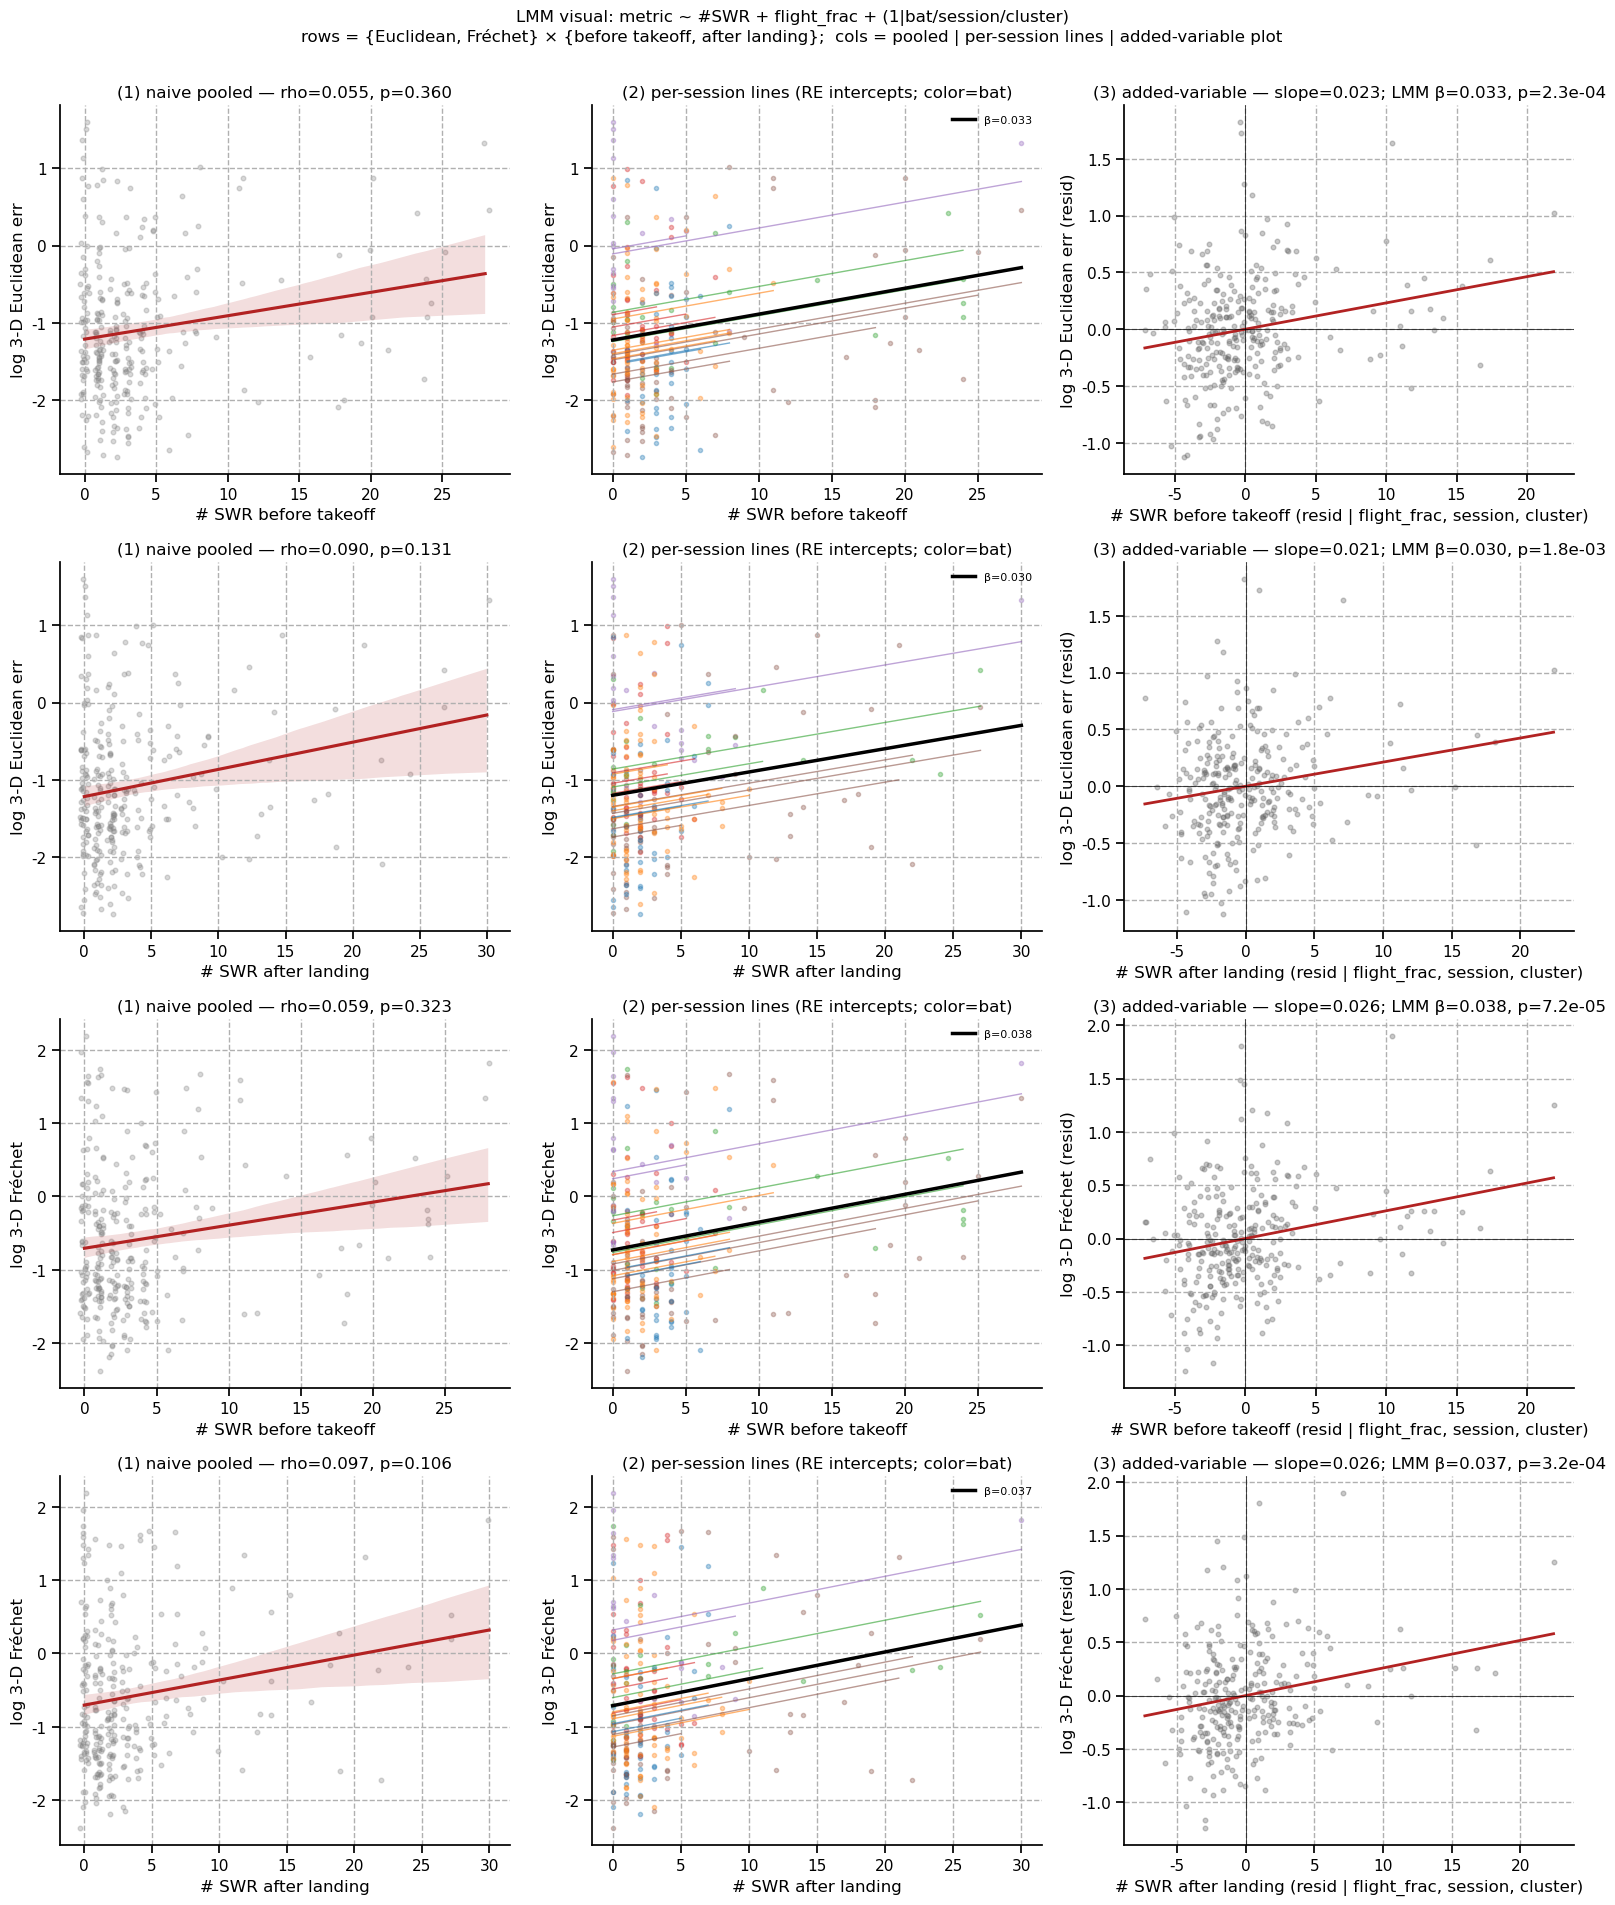

In [ ]:
# --- Intuitive 3-panel visualization of the LMM fixed effect ---
def _mixed_resid(d, lhs):
    '''Conditional residuals of `lhs ~ flight_frac + (1|bat/session) + (1|cluster_uid)`
    via lme4 (partial pooling -> singleton clusters shrink, not collapsed). Falls back
    to cluster fixed-effects OLS if rpy2/R is unavailable.'''
    if _HAVE_NB_MIXED:
        sub = d[[lhs, 'flight_frac', 'bat', 'session', 'cluster_uid']].copy()
        with (_ro.default_converter + _p2r.converter).context():
            _ro.globalenv['dd'] = sub
            _ro.r('dd$bat<-factor(dd$bat); dd$session<-factor(dd$session); dd$cluster_uid<-factor(dd$cluster_uid)')
            _ro.r(f'mm <- suppressWarnings(lme4::lmer({lhs} ~ flight_frac + (1|bat/session) '
                  f'+ (1|cluster_uid), data=dd, REML=TRUE, control=lme4::lmerControl(calc.derivs=FALSE)))')
            return np.asarray(_ro.r('as.numeric(residuals(mm))'))
    return smf.ols(f'{lhs} ~ flight_frac + C(cluster_uid)', d).fit().resid.values

def lmm_panels(axrow, ycol, xcol, ylabel, xlabel):
    d, r = results[(ycol, xcol)]; d = d.copy(); b = r.params[xcol]
    a0, a1, a2 = axrow
    # (1) naive pooled scatter
    sns.regplot(data=d, x=xcol, y=ycol, ax=a0, x_jitter=0.3,
                scatter_kws=dict(s=11, alpha=0.3, color='0.5'), line_kws=dict(color='firebrick'))
    rho, pp = spearmanr(d[xcol], d[ycol])
    a0.set(xlabel=xlabel, ylabel=ylabel, title=f'(1) naive pooled — rho={rho:.3f}, p={pp:.3f}')
    # (2) per-session parallel lines: shared fixed slope b, session-specific intercept (= random effect)
    for sess, g in d.groupby('session'):
        col = BAT_PALETTE.get(g['bat'].iloc[0], '0.5')
        a1.scatter(g[xcol], g[ycol], s=9, color=col, alpha=0.35)
        xs = np.array([g[xcol].min(), g[xcol].max()])
        a1.plot(xs, (g[ycol] - b * g[xcol]).mean() + b * xs, color=col, alpha=0.6, lw=1)
    xs = np.array([d[xcol].min(), d[xcol].max()])
    a1.plot(xs, (d[ycol] - b * d[xcol]).mean() + b * xs, 'k-', lw=2.5, label=f'β={b:.3f}')
    a1.legend(fontsize=8)
    a1.set(xlabel=xlabel, ylabel=ylabel, title='(2) per-session lines (RE intercepts; color=bat)')
    # (3) added-variable plot: both axes residualized on flight_frac + nested RE (bat/session/cluster)
    #     via the mixed model's conditional residuals (matches the LMM's controls).
    yr, xr = _mixed_resid(d, ycol), _mixed_resid(d, xcol)
    sl = np.polyfit(xr, yr, 1)[0]; xx = np.array([xr.min(), xr.max()])
    a2.scatter(xr, yr, s=11, alpha=0.35, color='0.4'); a2.plot(xx, sl * xx, 'firebrick', lw=2)
    a2.axhline(0, color='k', lw=0.5); a2.axvline(0, color='k', lw=0.5)
    a2.set(xlabel=f'{xlabel} (resid | flight_frac, session, cluster)', ylabel=f'{ylabel} (resid)',
           title=f'(3) added-variable — slope={sl:.3f}; LMM β={b:.3f}, p={r.pvalues[xcol]:.1e}')

combos = [('log_err_3d', 'pre_takeoff', 'log 3-D Euclidean err', '# SWR before takeoff'),
          ('log_err_3d', 'post_landing', 'log 3-D Euclidean err', '# SWR after landing'),
          ('log_frechet_3d', 'pre_takeoff', 'log 3-D Fréchet', '# SWR before takeoff'),
          ('log_frechet_3d', 'post_landing', 'log 3-D Fréchet', '# SWR after landing')]
fig, axes = plt.subplots(4, 3, figsize=(16, 19))
for axrow, (ycol, xcol, ylab, xlab) in zip(axes, combos):
    lmm_panels(axrow, ycol, xcol, ylab, xlab)
fig.suptitle('LMM visual: metric ~ #SWR + flight_frac + (1|bat/session/cluster)\n'
             'rows = {Euclidean, Fréchet} × {before takeoff, after landing};  '
             'cols = pooled | per-session lines | added-variable plot', y=1.002, fontsize=12)
fig.tight_layout(); plt.show()

## Task 6 — does the peri-flight SWR effect hold for a Naive Bayes decoder?

The joint transformer showed decode error rising with peri-flight SWR count. Is that a
property of the *neural data* or of the *flexible model*? We repeat the test with a basic
**Naive Bayes spatial decoder** (Poisson rate-map / argmax population decoder,
`digitalbat.models.decoder.NaiveBayes_Decoder`, as built in
`decode-position-comparison.ipynb`) — same train/test split, same flights, best 3-D
hyperparameters from that notebook's Optuna study. We fit per session on the train split,
decode 3-D position on the held-out test flights (per-flight Euclidean error + Fréchet),
then re-run `log error ~ #SWR + flight_frac + (1|bat/session/cluster)` and **compare the
SWR slope directly between the joint and NB decoders**.

In [ ]:
# --- Naive Bayes spatial decoder on the same test flights ---
import pickle
from digitalbat.models.decoder import NaiveBayes_Decoder

def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for b in loader:
        spk.append(b.spike.numpy()); beh.append(b.behavior.numpy())
        msk.append(b.mask.numpy().astype(bool)); fpi.append(b.flight_path_index.numpy())
    spk = np.concatenate(spk, 0); beh = np.concatenate(beh, 0)
    msk = np.concatenate(msk, 0); fpi = np.concatenate(fpi, 0)
    bm = np.asarray(bm).squeeze(); bs = np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs[None, None, :3] + bm[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos=pos[msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))

# best 3-D NB hyperparameters from decode-position-comparison.ipynb's Optuna study (seed 1)
NB_CKPT = os.path.expanduser('~/Documents/code/digitalbat/notebooks/out/nb_decoder/nb_decoder_3d_seed_1_optuna.pkl')
with open(NB_CKPT, 'rb') as f:
    nb_par = pickle.load(f).best_params
print('NB 3-D best params:', nb_par)

nb_rows = []
for s in dataloaders['test'].keys():
    bm = meta_info_dict['behavior_mean'][s]; bs = meta_info_dict['behavior_std'][s]
    r_lim = meta_info_dict['r_lim'][s]
    tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
    te = gather_session_arrays(dataloaders['test'][s], bm, bs)
    if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
        continue
    nb = NaiveBayes_Decoder(n_bins=(nb_par['n_bins_x'], nb_par['n_bins_y'], nb_par['n_bins_z']),
                            lims=[tuple(r_lim[d]) for d in range(3)], sigma=nb_par['sigma'],
                            dt=BIN_WIDTH, min_occupancy=nb_par['min_occupancy'],
                            use_uniform_prior=nb_par['use_uniform_prior']).fit(tr['spikes'], tr['pos'])
    pred, _ = nb.predict(te['spikes'])
    err3 = np.sqrt(((te['pos'] - pred) ** 2).sum(1))
    nb_rows.append(pd.DataFrame(dict(session=s, flight_id=te['flight_id'], t_idx=te['t_idx'],
                                     xt=te['pos'][:, 0], yt=te['pos'][:, 1], zt=te['pos'][:, 2],
                                     xp=pred[:, 0], yp=pred[:, 1], zp=pred[:, 2], err_3d=err3)))
nb_ts = pd.concat(nb_rows, ignore_index=True)

def _nb_frechet(g):
    g = g.sort_values('t_idx')
    return discrete_frechet(g[['xt', 'yt', 'zt']].to_numpy(float), g[['xp', 'yp', 'zp']].to_numpy(float))

nb_fl = nb_ts.groupby(['session', 'flight_id']).agg(nb_err_3d=('err_3d', 'mean')).reset_index()
nb_fl['nb_frechet_3d'] = nb_ts.groupby(['session', 'flight_id']).apply(_nb_frechet, include_groups=False).values

# merge NB per-flight metrics onto the joint per-flight table (same flights)
cmp = mf.merge(nb_fl, left_on=['session', 'flight_path_index'],
               right_on=['session', 'flight_id'], how='inner', suffixes=('', '_nb'))
cmp['nb_log_err_3d'] = np.log(cmp['nb_err_3d']); cmp['nb_log_frechet_3d'] = np.log(cmp['nb_frechet_3d'])
print(f'{len(cmp)} test flights; decode median err_3d  joint={cmp.err_3d.median():.3f} m  '
      f'NB={cmp.nb_err_3d.median():.3f} m')

NB 3-D best params: {'sigma': 0.5695804684392846, 'n_bins_x': 30, 'n_bins_y': 40, 'min_occupancy': 1, 'use_uniform_prior': True, 'n_bins_z': 15}
281 test flights; decode median err_3d  joint=0.288 m  NB=0.695 m


LMM: log decode error ~ #SWR + flight_frac + (1|bat/session/cluster) — joint vs Naive Bayes
decoder      metric         side   beta     se      z      p
  joint  log Euclid  pre_takeoff 0.0335 0.0091 3.6825 0.0002
  joint  log Euclid post_landing 0.0302 0.0097 3.1196 0.0018
     NB  log Euclid  pre_takeoff 0.0203 0.0067 3.0333 0.0024
     NB  log Euclid post_landing 0.0173 0.0071 2.4258 0.0153
  joint log Fréchet  pre_takeoff 0.0379 0.0096 3.9689 0.0001
  joint log Fréchet post_landing 0.0367 0.0102 3.5968 0.0003
     NB log Fréchet  pre_takeoff 0.0213 0.0088 2.4303 0.0151
     NB log Fréchet post_landing 0.0203 0.0093 2.1882 0.0287


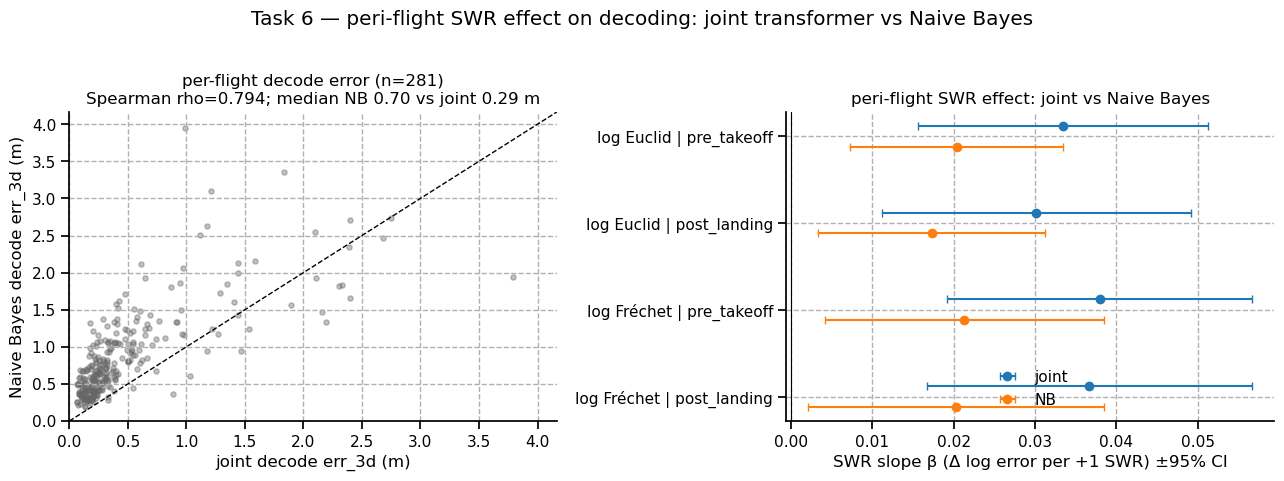

In [ ]:
# --- Compare the peri-flight SWR effect: joint vs Naive Bayes ---
import statsmodels.formula.api as smf, warnings

def swr_lmm(d, ycol, xcol):
    d = d.dropna(subset=[ycol, xcol, 'flight_frac', 'bat', 'cluster_uid']).copy()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m = smf.mixedlm(f'{ycol} ~ {xcol} + flight_frac', d, groups=d['bat'], re_formula='1',
                        vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(cluster_uid)'}).fit(
                        reml=True, method='lbfgs', maxiter=400)
    return dict(beta=m.params[xcol], se=m.bse[xcol], z=m.params[xcol] / m.bse[xcol], p=m.pvalues[xcol])

SPECS = [('joint', 'log_err_3d', 'log Euclid'), ('NB', 'nb_log_err_3d', 'log Euclid'),
         ('joint', 'log_frechet_3d', 'log Fréchet'), ('NB', 'nb_log_frechet_3d', 'log Fréchet')]
rows = []
for dec, ycol, metric in SPECS:
    for xcol in ['pre_takeoff', 'post_landing']:
        rows.append(dict(decoder=dec, metric=metric, side=xcol, **swr_lmm(cmp, ycol, xcol)))
cmp_lmm = pd.DataFrame(rows)
print('LMM: log decode error ~ #SWR + flight_frac + (1|bat/session/cluster) — joint vs Naive Bayes')
print(cmp_lmm.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.7))
# (a) per-flight decode error: joint vs NB
lim = [0, np.nanpercentile(np.r_[cmp['err_3d'].values, cmp['nb_err_3d'].values], 99)]
ax[0].scatter(cmp['err_3d'], cmp['nb_err_3d'], s=14, alpha=0.4, color='0.4')
ax[0].plot(lim, lim, 'k--', lw=1)
rho, _ = spearmanr(cmp['err_3d'], cmp['nb_err_3d'])
ax[0].set(xlabel='joint decode err_3d (m)', ylabel='Naive Bayes decode err_3d (m)', xlim=lim, ylim=lim,
          title=f'per-flight decode error (n={len(cmp)})\nSpearman rho={rho:.3f}; '
                f'median NB {cmp.nb_err_3d.median():.2f} vs joint {cmp.err_3d.median():.2f} m')
# (b) SWR-effect coefficient (forest): joint vs NB
keys = ['log Euclid | pre_takeoff', 'log Euclid | post_landing',
        'log Fréchet | pre_takeoff', 'log Fréchet | post_landing']
combos = cmp_lmm.assign(key=cmp_lmm.metric + ' | ' + cmp_lmm.side)
for dec, off, c in [('joint', -0.12, 'tab:blue'), ('NB', 0.12, 'tab:orange')]:
    sub = combos[combos.decoder == dec].set_index('key').loc[keys]
    ax[1].errorbar(sub['beta'], np.arange(len(keys)) + off, xerr=1.96 * sub['se'],
                   fmt='o', color=c, capsize=3, label=dec)
ax[1].axvline(0, color='k', lw=0.8)
ax[1].set_yticks(range(len(keys))); ax[1].set_yticklabels(keys); ax[1].invert_yaxis()
ax[1].set(xlabel='SWR slope β (Δ log error per +1 SWR) ±95% CI',
          title='peri-flight SWR effect: joint vs Naive Bayes'); ax[1].legend()
fig.suptitle('Task 6 — peri-flight SWR effect on decoding: joint transformer vs Naive Bayes', y=1.02)
fig.tight_layout(); plt.show()

## Task 7 — Encoding performance vs peri-flight SWRs (joint transformer & place GLM)

Tasks 2/6 asked whether peri-flight SWRs track how well behaviour is **decoded** from
neural activity. Here we flip the arrow to the **encoding** direction (behaviour ->
spikes) and ask the complementary question: *are flights flanked by more SWRs encoded
better or worse -- even holding the flight trajectory fixed?*

Two encoders are scored on the exact same held-out test flights:

- **Joint transformer** under its `encode` mask (neural tokens hidden -> the model
  predicts each neuron's Poisson rate from position; `neural_target = valid_mask`,
  `beh_target = 0`).
- **Vanilla place GLM** -- the position-basis Poisson GLM `GLM_3DCosineBasis`
  (16^3 3-D cosine place bumps -> session-wise linear-exp readout), loaded from the
  checkpoint trained in `model_comparison.ipynb`.

Per flight we compute two encoding scores over that flight's valid bins, on the
neurons that fired at least once (the encoding-signal carriers):

- **rate-count corr** -- mean per-neuron Pearson correlation between predicted rate and
  observed count;
- **population Poisson FDE** -- fraction of deviance explained, pooled across
  neurons+timesteps (null = each neuron's own mean rate over the flight; robust to
  silent neurons).

We then relate both scores to the peri-flight SWR counts (`pre_takeoff` /
`post_landing`, the same `W_PERI`-s windows as Task 2) -- pooled, per-session, and
finally **within trajectory cluster** (within-(session, cluster) demeaning + the same
nested `(1 | bat / session / cluster)` mixed model as Task 2), which is what "holding
the flight path fixed" means here.


In [ ]:
# --- Encoding direction: per-flight corr / population-FDE for joint transformer & place GLM ---
from digitalbat.models.glm import GLM_3DCosineBasis
from digitalbat.utility.utils import corr as _corr

# Vanilla position-basis Poisson GLM: identical arch + checkpoint as model_comparison.ipynb
# (16^3 cosine place bumps, exp link, per-session readouts over the same 17-session split).
GLM_CKPT = os.path.expanduser(
    '~/Documents/code/digitalbat/notebooks/out/bat_glm/bat_glm_position_seed_1_optuna_acc50_default17.pth')
place_glm = GLM_3DCosineBasis(output_dim_dict=unit_num_dict, n_bases_per_dim=16,
                              pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                              activation='exp', bin_width=0.10).to(device)
place_glm.load_state_dict(torch.load(GLM_CKPT, map_location=device))
place_glm.eval()

MIN_ENC_T = 3   # a flight needs >= 3 valid bins to score

def _pop_fde(yt, yp):
    '''Population Poisson fraction-deviance-explained, pooled over neurons+timesteps
    within a flight (null = each neuron's own mean rate over the flight). Silent
    neurons contribute ~0 to both deviances, so this is robust to short flights.'''
    eps = 1e-9
    yp = np.clip(yp, eps, None); ytc = np.clip(yt, eps, None)
    mu0 = np.broadcast_to(np.clip(yt.mean(0, keepdims=True), eps, None), ytc.shape)
    dev = lambda mu: 2.0 * np.sum(ytc * (np.log(ytc) - np.log(mu)) - (ytc - mu))
    return 1.0 - dev(yp) / (dev(mu0) + eps)

def _flight_scores(yt, yp):
    '''(T, K) observed counts & predicted rates for one flight -> (corr, fde, n_active),
    scored on neurons that fired >= 1 spike in the flight.'''
    active = yt.sum(0) >= 1
    if active.sum() == 0:
        return np.nan, np.nan, 0
    yt, yp = yt[:, active], yp[:, active]
    return float(np.nanmean(_corr(yt, yp, axis=0))), float(_pop_fde(yt, yp)), int(active.sum())

def _encoding_records(predict_rate, loaders):
    '''predict_rate(session, batch) -> (B, T, K) rate array. Returns per-flight scores.'''
    rows = []
    for s, sd in loaders.items():
        for b in sd:
            yp = predict_rate(s, b); yt = b.spike.numpy(); mk = b.mask.numpy().astype(bool)
            fpi = b.flight_path_index.numpy()
            for i in range(yp.shape[0]):
                tv = mk[i]
                if tv.sum() < MIN_ENC_T:
                    continue
                c, f, na = _flight_scores(yt[i, tv], yp[i, tv])
                rows.append(dict(session=s, flight_id=int(fpi[i]), enc_corr=c, enc_fde=f,
                                 n_active=na, n_t=int(tv.sum())))
    return pd.DataFrame(rows)

def _joint_rate(s, b):                         # encode: neural tokens hidden -> predict spikes
    m = b.mask.to(device); nt = b.mask.clone().to(device); bt = torch.zeros_like(m)
    with torch.no_grad():
        rate, _, _ = joint_model(s, b.spike.to(device), b.behavior.to(device), m, nt, bt)
    return rate.cpu().numpy()

def _glm_rate(s, b):
    with torch.no_grad():
        return place_glm(s, b.behavior.to(device), b.mask.to(device)).cpu().numpy()

enc_joint = remap_joint_ids(_encoding_records(_joint_rate, joint_loaders['test']))  # IMU-trunc -> true ids
enc_glm   = _encoding_records(_glm_rate,   dataloaders['test'])                      # base loaders aligned

# long form (one row per flight x model) merged with peri-flight SWR context
enc_long = pd.concat([enc_joint.assign(model='Joint transformer'),
                      enc_glm.assign(model='Place GLM')], ignore_index=True)
ef = flights.merge(enc_long, left_on=['session', 'flight_path_index'],
                   right_on=['session', 'flight_id'], how='inner')
MODEL_COLORS = {'Joint transformer': 'tab:blue', 'Place GLM': 'tab:orange'}
print(f'{len(enc_joint)} joint / {len(enc_glm)} GLM per-flight encoding scores; '
      f'{ef.flight_path_index.nunique()} flights merged with SWR context')
print(enc_long.groupby('model')[['enc_corr', 'enc_fde', 'n_active', 'n_t']].median().round(3).to_string())


In [ ]:
# --- Encoding quality vs peri-flight SWRs: joint transformer vs place GLM ---
ENC_METRICS = [('enc_corr', 'mean rate-count corr'), ('enc_fde', 'population Poisson FDE')]
SIDES2 = [('pre_takeoff', 'SWR before takeoff'), ('post_landing', 'SWR after landing')]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for r, (ycol, ylab) in enumerate(ENC_METRICS):
    for c, (xcol, xlab) in enumerate(SIDES2):
        ax = axes[r, c]
        for mdl, col in MODEL_COLORS.items():
            d = ef[ef.model == mdl].dropna(subset=[xcol, ycol])
            sns.regplot(data=d, x=xcol, y=ycol, ax=ax, color=col, x_jitter=0.3,
                        scatter_kws=dict(s=12, alpha=0.22), line_kws=dict(lw=2),
                        label=f'{mdl} (n={len(d)})')
        ax.legend(fontsize=8)
        ax.set(xlabel=f'# {xlab} ({W_PERI:g}s window)', ylabel=ylab, title=f'{ylab} vs {xlab}')
        if ycol == 'enc_fde':
            ax.set_ylim(-1, 1)   # FDE unbounded below; bound the axis, not the raw stats
fig.suptitle('Task 7 - encoding performance vs peri-flight SWR '
             '[pooled scatter, DESCRIPTIVE; session-aware table below + mixed model]', y=1.01)
fig.tight_layout(); plt.show()

# session-aware: per-session Spearman -> sign test across sessions, per model
recs = []
for mdl in MODEL_COLORS:
    dm = ef[ef.model == mdl]
    for ycol, _ in ENC_METRICS:
        for xcol, _ in SIDES2:
            rhos = []
            for s, d in dm.dropna(subset=[xcol, ycol]).groupby('session'):
                if d[xcol].nunique() > 2 and len(d) >= 6:
                    rhos.append(spearmanr(d[xcol], d[ycol])[0])
            rhos = np.array(rhos); _, pp = wilcoxon_safe(rhos)
            recs.append(dict(model=mdl, pair=f'{ycol} ~ {xcol}', n_sess=len(rhos),
                             median_rho=np.nanmedian(rhos), p=pp))
print(pd.DataFrame(recs).round(3).to_string(index=False))


### Task 7 control — holding the flight trajectory fixed

Does any encoding-vs-SWR relationship survive once we condition on *which flight path*
the bat took? Two session-aware controls, mirroring Task 2:

- **within-(session, cluster) demeaning** — subtract each trajectory cluster's mean
  before correlating, so only *within-cluster* variation (same path, different SWR
  count) drives the residual Spearman;
- **nested mixed model** — `metric ~ #SWR + flight_frac + (1 | bat / session / cluster)`,
  with `flight_frac` (normalized flight number) absorbing the within-session decline
  (Task 5) and the cluster random intercept absorbing the trajectory.


In [ ]:
# --- Holding the flight path fixed: within-(session,cluster) demeaning + nested LMM ---
from notebook_helpers import spearman
import statsmodels.formula.api as smf
import warnings

ef = ef.copy()
ef['cluster_uid'] = ef['session'] + '__' + ef['flight_type_index'].astype(str)

def _demean_corr(d, ycol, xcol):
    '''within-(session, cluster) residual Spearman (holds trajectory cluster fixed).'''
    d = d.dropna(subset=[ycol, xcol]).copy()
    g = d.groupby(['session', 'flight_type_index'])
    s2 = d[g[ycol].transform('size') >= 2].copy()
    if len(s2) < 6:
        return np.nan, np.nan, len(s2)
    yd = s2[ycol] - g[ycol].transform('mean')[s2.index]
    xd = s2[xcol] - g[xcol].transform('mean')[s2.index]
    rho, p = spearmanr(xd, yd)
    return rho, p, len(s2)

def _fit_lmm(d, ycol, xcol):
    dd = d.dropna(subset=[ycol, xcol, 'bat', 'cluster_uid', 'flight_frac']).copy()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m = smf.mixedlm(f'{ycol} ~ {xcol} + flight_frac', dd, groups=dd['bat'], re_formula='1',
                        vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(cluster_uid)'})
        r = m.fit(reml=True, method='lbfgs', maxiter=400)
    return dd, r

enc_results, rows = {}, []                        # enc_results[(model, ycol, xcol)] = (data, fit)
for mdl in MODEL_COLORS:
    dm = ef[ef.model == mdl]
    for ycol, ylab in ENC_METRICS:
        for xcol in ['pre_takeoff', 'post_landing']:
            rho_dm, p_dm, n_dm = _demean_corr(dm, ycol, xcol)
            try:
                d_fit, r = _fit_lmm(dm, ycol, xcol); n = len(d_fit)
                enc_results[(mdl, ycol, xcol)] = (d_fit, r)
                beta, se = r.params[xcol], r.bse[xcol]
                z, p, conv = beta / se, r.pvalues[xcol], bool(r.converged)
            except Exception as e:
                beta = z = p = np.nan; n = 0; conv = str(e)[:20]
            rows.append(dict(model=mdl, outcome=ylab, predictor=xcol,
                             raw_rho=spearman(dm[xcol], dm[ycol]),
                             demean_rho=rho_dm, demean_p=p_dm, demean_n=n_dm,
                             lmm_beta=beta, lmm_z=z, lmm_p=p, n=n, conv=conv))
enc_lmm = pd.DataFrame(rows)
print('Encoding ~ #SWR, holding the flight trajectory fixed')
print('  raw_rho    = pooled Spearman (descriptive)')
print('  demean_rho = within-(session, cluster) residual Spearman (trajectory held fixed)')
print('  lmm_beta/p = #SWR fixed effect in  metric ~ #SWR + flight_frac + (1 | bat/session/cluster)')
print(enc_lmm.round(4).to_string(index=False))


### Task 7 — visualizing the encoding LMM (same staggered plot as Task 2)

The three-panel view of Task 2, now for the encoding LMMs (one figure per encoder). Each
row is a (metric, peri-flight side); columns peel back the nuisance structure:

1. **naive pooled** — raw metric vs #SWR, ignoring all grouping (what the descriptive
   scatter shows).
2. **per-session lines** — the LMM's shared fixed slope β with a session-specific
   intercept (the random effect), points/lines colored by bat.
3. **added-variable plot** — both axes residualized on `flight_frac` **and** the nested
   `(1 | bat / session / cluster)` random effects (lme4 conditional residuals, matching the
   fitted model), so the visible slope *is* the LMM's β for #SWR with session time and
   trajectory cluster held fixed.

In [ ]:
# --- Staggered LMM visual for the encoding models (mirrors t2-lmm-viz) ---
def enc_lmm_panels(axrow, d, r, ycol, xcol, ylabel, xlabel):
    d = d.copy(); b = r.params[xcol]; a0, a1, a2 = axrow
    # (1) naive pooled scatter
    sns.regplot(data=d, x=xcol, y=ycol, ax=a0, x_jitter=0.3,
                scatter_kws=dict(s=11, alpha=0.3, color='0.5'), line_kws=dict(color='firebrick'))
    rho, pp = spearmanr(d[xcol], d[ycol])
    a0.set(xlabel=xlabel, ylabel=ylabel, title=f'(1) naive pooled - rho={rho:.3f}, p={pp:.3f}')
    # (2) per-session parallel lines: shared fixed slope b, session-specific intercept (RE)
    for sess, g in d.groupby('session'):
        col = BAT_PALETTE.get(g['bat'].iloc[0], '0.5')
        a1.scatter(g[xcol], g[ycol], s=9, color=col, alpha=0.35)
        xs = np.array([g[xcol].min(), g[xcol].max()])
        a1.plot(xs, (g[ycol] - b * g[xcol]).mean() + b * xs, color=col, alpha=0.6, lw=1)
    xs = np.array([d[xcol].min(), d[xcol].max()])
    a1.plot(xs, (d[ycol] - b * d[xcol]).mean() + b * xs, 'k-', lw=2.5, label=f'β={b:.3f}')
    a1.legend(fontsize=8)
    a1.set(xlabel=xlabel, ylabel=ylabel, title='(2) per-session lines (RE intercepts; color=bat)')
    # FDE is unbounded below; bound the display axis (raw values keep driving the fit)
    if ycol == 'enc_fde':
        a0.set_ylim(-1, 1); a1.set_ylim(-1, 1)
    # (3) added-variable plot: both axes residualized on flight_frac + nested RE (bat/session/cluster)
    yr, xr = _mixed_resid(d, ycol), _mixed_resid(d, xcol)
    sl = np.polyfit(xr, yr, 1)[0]; xx = np.array([xr.min(), xr.max()])
    a2.scatter(xr, yr, s=11, alpha=0.35, color='0.4'); a2.plot(xx, sl * xx, 'firebrick', lw=2)
    a2.axhline(0, color='k', lw=0.5); a2.axvline(0, color='k', lw=0.5)
    a2.set(xlabel=f'{xlabel} (resid | flight_frac, session, cluster)', ylabel=f'{ylabel} (resid)',
           title=f'(3) added-variable - slope={sl:.3f}; LMM β={b:.3f}, p={r.pvalues[xcol]:.1e}')

_enc_combos = [(yc, xc, yl, xl) for yc, yl in ENC_METRICS
               for xc, xl in [('pre_takeoff', '# SWR before takeoff'),
                              ('post_landing', '# SWR after landing')]]
for mdl in MODEL_COLORS:
    fig, axes = plt.subplots(len(_enc_combos), 3, figsize=(16, 4.7 * len(_enc_combos)))
    for axrow, (yc, xc, yl, xl) in zip(np.atleast_2d(axes), _enc_combos):
        if (mdl, yc, xc) not in enc_results:
            for ax in axrow:
                ax.axis('off')
            continue
        d, r = enc_results[(mdl, yc, xc)]
        enc_lmm_panels(axrow, d, r, yc, xc, yl, xl)
    fig.suptitle(f'{mdl} — encoding LMM visual: metric ~ #SWR + flight_frac + (1|bat/session/cluster)\n'
                 'rows = {rate-count corr, population FDE} × {before takeoff, after landing};  '
                 'cols = pooled | per-session lines | added-variable plot', y=1.001, fontsize=12)
    fig.tight_layout(); plt.show()


## Bonus — further questions

(a) **Does the rest period drive SWR count?** Longer post-landing dwell should
accumulate more SWRs (rate roughly constant), a sanity check on the peri-flight
metric. (b) **Do pre-takeoff SWRs anticipate longer flights, beyond cluster
identity?** Rarer (smaller-cluster) flights tend to be longer *and* (Task 3) carry
more pre-takeoff SWRs, so we ask whether `#SWR before takeoff` predicts upcoming
flight **duration** beyond cluster commonness.

Inference here is **session-aware**: (a) a per-session Spearman aggregated across
sessions (Wilcoxon vs 0); (b) a linear mixed model
`duration ~ #SWR + (1 | subject/session/trajectory_cluster)`, which controls for
subject, session and cluster at once. The scatters are descriptive only.

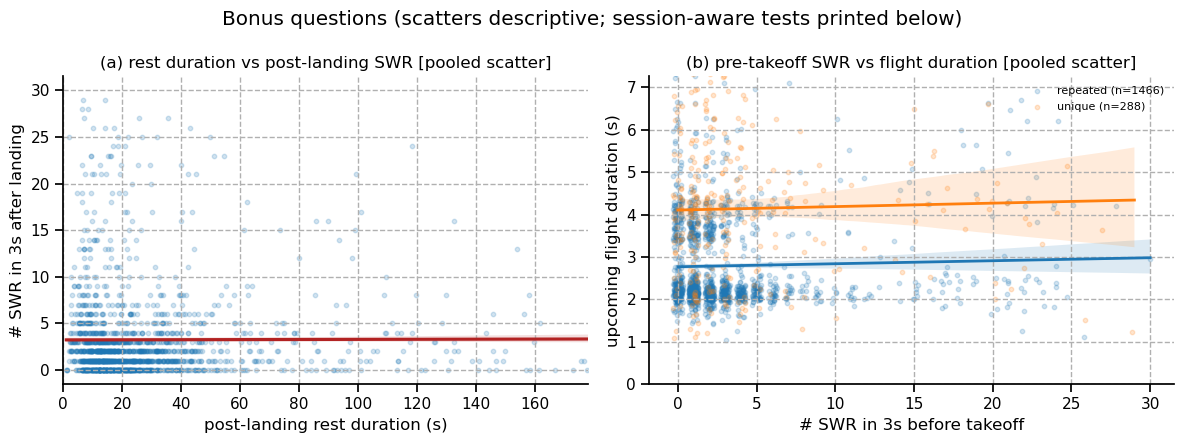

(a) per-session rho(rest duration, post-landing SWR): median=0.007, p=0.818, n=17 sessions  (expect ~0: fixed-window count not driven by dwell)
(b) LMM dur ~ pre_takeoff + flight_frac + (1|bat/session/cluster): beta(pre)=-0.0022, p(pre)=0.234; beta(flight_frac)=-0.100, p(flight_frac)=0.000  (n=1754)
    cluster commonness: duration (s) {'repeated': 2.79, 'unique': 4.14} | pre-takeoff SWR {'repeated': 3.25, 'unique': 4.56}


In [ ]:
from notebook_helpers import partial_r, spearman
import statsmodels.formula.api as smf
import warnings

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
# (a) sanity: post-landing SWR count vs post-landing rest duration (expect ~flat)
d = flights.dropna(subset=['dwell_after']); d = d[d['dwell_after'] > 0]
sns.regplot(data=d, x='dwell_after', y='post_landing', ax=ax[0],
            scatter_kws=dict(s=10, alpha=0.2), line_kws=dict(color='firebrick'))
ax[0].set(xlabel='post-landing rest duration (s)', ylabel=f'# SWR in {W_PERI:g}s after landing',
          xlim=(0, np.percentile(d['dwell_after'], 95)),
          title='(a) rest duration vs post-landing SWR [pooled scatter]')
# (b) pre-takeoff SWR (x) vs upcoming flight duration (y), split by cluster commonness
for grp, c in [('repeated','tab:blue'), ('unique','tab:orange')]:
    dd = flights[flights.repeated == grp]
    sns.regplot(data=dd, x='pre_takeoff', y='dur', ax=ax[1], color=c, x_jitter=0.3,
                scatter_kws=dict(s=10, alpha=0.2), line_kws=dict(lw=2), label=f'{grp} (n={len(dd)})')
ax[1].legend(fontsize=8)
ax[1].set(xlabel=f'# SWR in {W_PERI:g}s before takeoff', ylabel='upcoming flight duration (s)',
          ylim=(0, np.percentile(flights['dur'], 99)),
          title='(b) pre-takeoff SWR vs flight duration [pooled scatter]')
fig.suptitle('Bonus questions (scatters descriptive; session-aware tests printed below)')
fig.tight_layout(); plt.show()

# --- session-aware inference ---
# (a) per-session Spearman(rest duration, post-landing SWR) -> Wilcoxon across sessions
rhos = [spearmanr(s['dwell_after'], s['post_landing'])[0]
        for _, s in d.groupby('session') if len(s) >= 6 and s['dwell_after'].nunique() > 2]
rhos = np.array([r for r in rhos if np.isfinite(r)]); _, pa = wilcoxon_safe(rhos)
print(f'(a) per-session rho(rest duration, post-landing SWR): median={np.nanmedian(rhos):.3f}, '
      f'p={pa:.3f}, n={len(rhos)} sessions  (expect ~0: fixed-window count not driven by dwell)')

# (b) LMM: duration ~ pre_takeoff + flight_frac + (1 | bat / session / trajectory_cluster)
b = flights.dropna(subset=['dur', 'pre_takeoff', 'flight_frac']).copy()
b['clu_uid'] = b['session'] + '_' + b['flight_type_index'].astype(str)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    mb = smf.mixedlm('dur ~ pre_takeoff + flight_frac', b, groups=b['bat'], re_formula='1',
                     vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(clu_uid)'}).fit(
                     reml=True, method='lbfgs', maxiter=400)
print(f'(b) LMM dur ~ pre_takeoff + flight_frac + (1|bat/session/cluster): '
      f'beta(pre)={mb.params["pre_takeoff"]:.4f}, p(pre)={mb.pvalues["pre_takeoff"]:.3f}; '
      f'beta(flight_frac)={mb.params["flight_frac"]:.3f}, p(flight_frac)={mb.pvalues["flight_frac"]:.3f}  (n={len(b)})')
print('    cluster commonness: duration (s)', flights.groupby('repeated')['dur'].mean().round(2).to_dict(),
      '| pre-takeoff SWR', flights.groupby('repeated')['pre_takeoff'].mean().round(2).to_dict())

## Krishna replication — novel-flight & decode-error vs peri-flight SWRs (held separate)

Re-run **Task 3** (do rarer / novel-cluster flights carry more peri-flight SWRs?) and
**Task 2** (does more peri-flight SWR activity track worse decoding?) on the **Krishna**
sessions, kept **completely separate** from the Dataset 1-3 analysis above: its own
flight table `k_flights`, its own decoder, never pooled into `flights` / `mf`.

Two structural differences force separate handling:

- **No joint model for Krishna.** The transformer checkpoint was trained on the 17
  Dataset 1-3 sessions only, so Task 2 here uses the **Naive Bayes** spatial decoder
  (same `decode-position-comparison` Optuna hyper-parameters as Task 6), trained
  per-session on that session's train split. Jacobian magnification (model-derived) is
  not available and is dropped.
- **Single bat.** Every Krishna session with ripple data is bat **11719** (7 sessions
  over 3 days, lab + field station). With one subject the random-effects grouping drops
  to `(1 | session)` with cluster nested in session, and session-level dots are coloured
  by **environment** (bat is constant). Absolute NB error is also larger than in the lab
  datasets because the field-station room is much bigger.

*Caveat: n is small (7 sessions, one bat, ~21-74 flights each) - these are underpowered
replications, reported as effect directions + tests, not strong claims.*

In [ ]:
# --- Krishna flight table (separate from `flights`): reconstruct + peri-flight SWR counts ---
from digitalbat.datasets.defaults import KRISHNA_SESSION_NAMES

K_SESSIONS = [s for s in KRISHNA_SESSION_NAMES
              if glob.glob(f'{PARENT}/RPL_converted/{s}/RPL_probe*.mat')
              and glob.glob(f'{PARENT}/{s}/Extracted_Behavior_*.mat')]

k_swr_times, _kparts = {}, []
for sess in K_SESSIONS:
    fdf = reconstruct_flights(sess)                       # same reconstruction as Dataset 1-3
    swr_t = np.sort(load_swr_events(sess)[0]); k_swr_times[sess] = swr_t
    st, sp = fdf['start_t'].to_numpy(), fdf['stop_t'].to_numpy()
    fdf['pre_takeoff']  = np.searchsorted(swr_t, st) - np.searchsorted(swr_t, st - W_PERI)
    fdf['post_landing'] = np.searchsorted(swr_t, sp + W_PERI) - np.searchsorted(swr_t, sp)
    _kparts.append(fdf)
k_flights = pd.concat(_kparts, ignore_index=True)

# cluster annotations + within-session position (mirror the main `flights` table)
k_flights['cluster_size'] = k_flights.groupby(['session','flight_type_index'])['flight_path_index'].transform('size')
k_flights['repeated'] = np.where(k_flights['cluster_size'] > 1, 'repeated', 'unique')
k_flights['top_cluster'] = k_flights.groupby('session')['flight_type_index'].transform(
    lambda s: s == s.value_counts().idxmax())
k_flights['env'] = np.where(k_flights['session'].str.contains('_fs'), 'field station', 'lab')
k_flights['flight_num'] = k_flights.groupby('session')['start_t'].rank(method='first').astype(int) - 1
k_flights['flight_frac'] = k_flights.groupby('session')['flight_num'].transform(lambda s: s / max(s.max(), 1))
k_flights['pre_rate'] = k_flights['pre_takeoff'] / W_PERI
k_flights['post_rate'] = k_flights['post_landing'] / W_PERI
k_flights['clu_uid'] = k_flights['session'] + '__' + k_flights['flight_type_index'].astype(str)

ENV_PAL = {'lab': 'tab:blue', 'field station': 'tab:orange'}
print(f'{len(k_flights)} Krishna flights, {k_flights.session.nunique()} sessions, '
      f'{k_flights.bat.nunique()} bat(s); {(k_flights.repeated=="repeated").mean():.0%} in repeated clusters')
print('flights/session:', k_flights.groupby('session').size().to_dict())
print('mean pre/post SWR per flight:', k_flights[['pre_takeoff','post_landing']].mean().round(2).to_dict())

318 Krishna flights, 7 sessions, 1 bat(s); 36% in repeated clusters
flights/session: {'Dataset_Krishna_11719_250812_fs': 65, 'Dataset_Krishna_11719_250812_social_evening': 33, 'Dataset_Krishna_11719_250812_solo_evening': 58, 'Dataset_Krishna_11719_250812_solo_morning': 37, 'Dataset_Krishna_11719_250813_solo_morning': 21, 'Dataset_Krishna_11719_250814_fs_s2': 74, 'Dataset_Krishna_11719_250814_solo_morning': 30}
mean pre/post SWR per flight: {'pre_takeoff': 1.41, 'post_landing': 0.87}


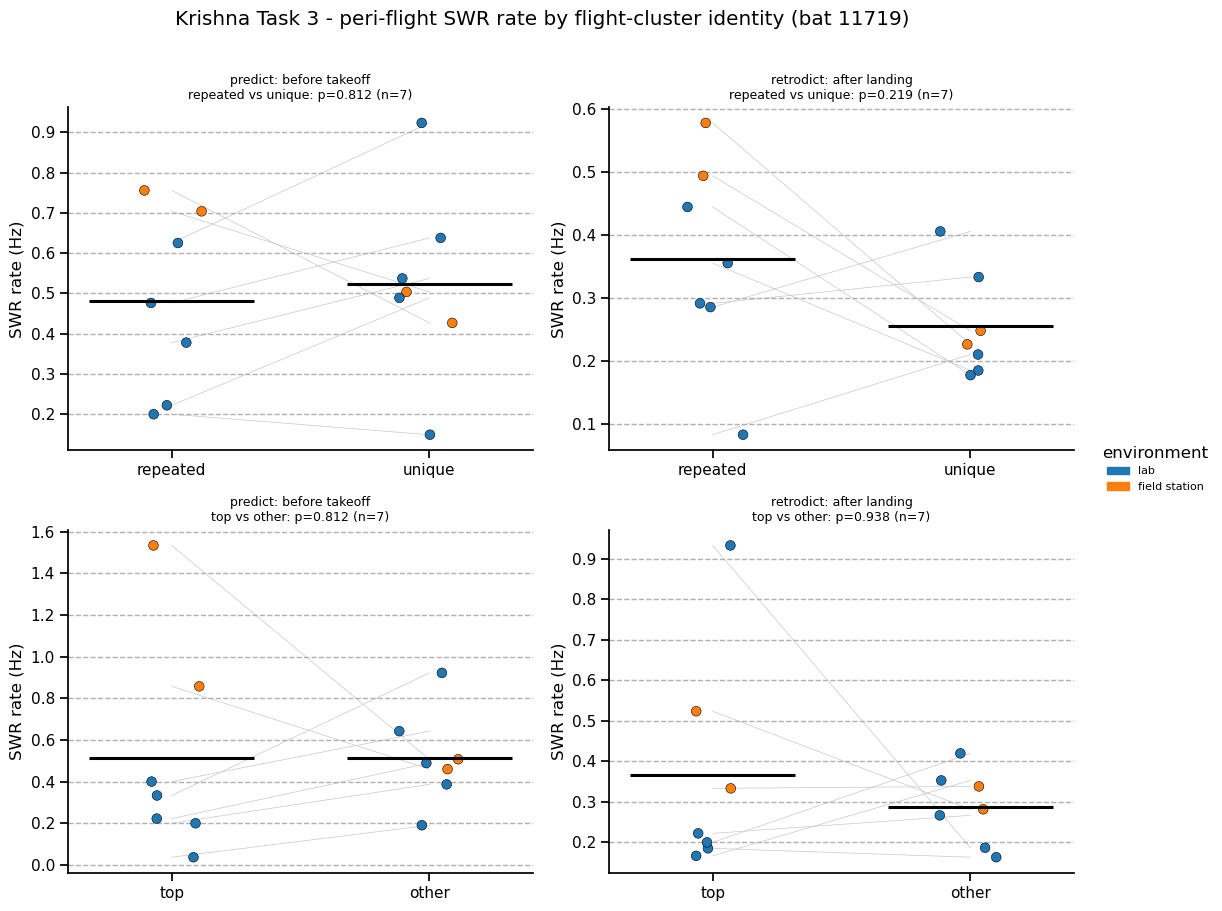

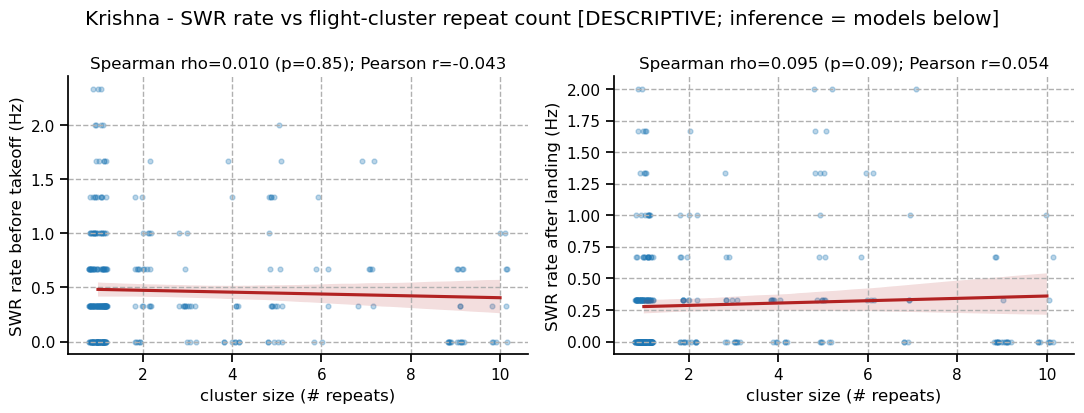

Krishna SWR ~ cluster_size + flight_frac (single bat -> 1|session, cluster nested) [p two-sided]
        side    predictor               model   n    beta      p
 pre-takeoff cluster_size            LMM rate 311 -0.0024 0.7978
 pre-takeoff cluster_size     NB GLM (offset) 311 -0.0129 0.6751
 pre-takeoff cluster_size        Poisson GLMM 311  0.0036 0.2641
 pre-takeoff cluster_size NB mixed (glmer.nb) 311 -0.0097 0.5550
 pre-takeoff       log_cs            LMM rate 311 -0.0042 0.8872
 pre-takeoff       log_cs     NB GLM (offset) 311 -0.0328 0.7268
 pre-takeoff       log_cs        Poisson GLMM 311  0.0110 0.3198
 pre-takeoff       log_cs NB mixed (glmer.nb) 311 -0.0267 0.6101
post-landing cluster_size            LMM rate 311 -0.0067 0.5790
post-landing cluster_size     NB GLM (offset) 311 -0.0125 0.7600
post-landing cluster_size        Poisson GLMM 311 -0.0008 0.7802
post-landing cluster_size NB mixed (glmer.nb) 311 -0.0135 0.4076
post-landing       log_cs            LMM rate 311 -0.0047 

In [ ]:
# --- Krishna Task 3: do rarer / novel-cluster flights carry more peri-flight SWRs? ---
import matplotlib.patches as mpatches

# session-level contrast coloured by environment (single bat -> bat colour is constant)
def k_contrast(ax, long_df, order, value_label):
    sns.stripplot(data=long_df, x='cond', y='val', order=order, hue='env', palette=ENV_PAL,
                  ax=ax, size=7, jitter=0.12, edgecolor='k', linewidth=0.4, zorder=3, legend=False)
    means = long_df.groupby('cond')['val'].mean()
    for i, c in enumerate(order):
        if c in means.index:
            ax.hlines(means[c], i - 0.32, i + 0.32, color='k', lw=2.2, zorder=4)
    piv = long_df.pivot_table(index='session', columns='cond', values='val').dropna()
    for _, r in piv.iterrows():
        ax.plot([0, 1], [r[order[0]], r[order[1]]], color='0.78', lw=0.5, zorder=1)
    _, p = wilcoxon_safe((piv[order[0]] - piv[order[1]]).values) if len(piv) else (np.nan, np.nan)
    add_significance_bracket(ax, 0, 1, p)
    ax.set(ylabel=value_label, xlabel=''); ax.set_title(f'p={p:.3f} (n={len(piv)})', fontsize=9)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
specs = [(axes[0,0], 'pre_rate', 'repeated', ['repeated','unique'], 'predict: before takeoff'),
         (axes[0,1], 'post_rate', 'repeated', ['repeated','unique'], 'retrodict: after landing'),
         (axes[1,0], 'pre_rate', 'top', ['top','other'], 'predict: before takeoff'),
         (axes[1,1], 'post_rate', 'top', ['top','other'], 'retrodict: after landing')]
for ax, metric, flag, order, ttl in specs:
    g = k_flights.copy()
    g['cond'] = g['repeated'] if flag == 'repeated' else np.where(g['top_cluster'], 'top', 'other')
    ps = g.groupby(['session','env','cond'])[metric].mean().reset_index().rename(columns={metric:'val'})
    k_contrast(ax, ps, order, 'SWR rate (Hz)')
    ax.set_title(f'{ttl}\n{order[0]} vs {order[1]}: ' + ax.get_title(), fontsize=9)
fig.legend(handles=[mpatches.Patch(color=c, label=e) for e, c in ENV_PAL.items()],
           title='environment', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8)
fig.suptitle('Krishna Task 3 - peri-flight SWR rate by flight-cluster identity (bat 11719)', y=1.01)
fig.tight_layout(); plt.show()

# descriptive pooled scatter: SWR rate vs cluster size
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (metric, lab) in zip(axes, [('pre_rate','before takeoff'), ('post_rate','after landing')]):
    cs = k_flights['cluster_size'].astype(float); rate = k_flights[metric].astype(float)
    rho, p_s = spearmanr(cs, rate); r_d, _ = pearsonr(cs, rate)
    sns.regplot(x=cs, y=rate, ax=a, x_jitter=0.2, scatter_kws=dict(s=12, alpha=0.3),
                line_kws=dict(color='firebrick'))
    a.set(xlabel='cluster size (# repeats)', ylabel=f'SWR rate {lab} (Hz)',
          title=f'Spearman rho={rho:.3f} (p={p_s:.2f}); Pearson r={r_d:.3f}')
fig.suptitle('Krishna - SWR rate vs flight-cluster repeat count [DESCRIPTIVE; inference = models below]')
fig.tight_layout(); plt.show()

# nested count/rate models (single bat -> 1|session, cluster nested): SWR ~ cluster_size + flight_frac
fl = k_flights.sort_values(['session','start_t']).copy(); gg = fl.groupby('session')
fl['prev_stop'] = gg['stop_t'].shift(1); fl['next_start'] = gg['start_t'].shift(-1)
fl['exp_pre'] = fl['start_t'] - fl['prev_stop']; fl['exp_post'] = fl['next_start'] - fl['stop_t']
fl['pre_cnt'] = np.nan; fl['post_cnt'] = np.nan
for sess, idx in fl.groupby('session').groups.items():
    t = k_swr_times[sess]; d = fl.loc[idx]
    m1 = d['prev_stop'].notna().values; pc = np.full(len(d), np.nan)
    pc[m1] = np.searchsorted(t, d['start_t'].values[m1]) - np.searchsorted(t, d['prev_stop'].values[m1])
    fl.loc[idx, 'pre_cnt'] = pc
    m2 = d['next_start'].notna().values; qc = np.full(len(d), np.nan)
    qc[m2] = np.searchsorted(t, d['next_start'].values[m2]) - np.searchsorted(t, d['stop_t'].values[m2])
    fl.loc[idx, 'post_cnt'] = qc
fl['log_cs'] = np.log(fl['cluster_size'])

def k_lmm_rate(d, x):
    m = smf.mixedlm(f'rate ~ {x} + flight_frac', d, groups=d['session'], re_formula='1',
                    vc_formula={'cluster': '0 + C(clu_uid)'}).fit(reml=True, method='lbfgs', maxiter=400)
    return dict(model='LMM rate', beta=m.params[x], p=m.pvalues[x])
def k_nb_glm(d, x):
    X = sm.add_constant(d[[x, 'flight_frac']].astype(float))
    r = sm.NegativeBinomial(d['count'].astype(float), X, offset=d['log_exp'].values).fit(
        disp=0, cov_type='cluster', cov_kwds={'groups': d['session']})
    return dict(model='NB GLM (offset)', beta=r.params[x], p=r.pvalues[x])
def k_pois_glmm(d, x):
    pm = PoissonBayesMixedGLM.from_formula(f'count ~ {x} + log_exp + flight_frac', {'session': '0 + C(session)'}, d)
    r = pm.fit_map(); nm = list(r.model.exog_names); i = nm.index(x); z = r.fe_mean[i]/r.fe_sd[i]
    return dict(model='Poisson GLMM', beta=r.fe_mean[i], p=2*(1 - norm.cdf(abs(z))))
def k_nb_mixed(d, x):
    sub = d[['count','log_exp','session','flight_frac', x]].copy()
    with (_ro.default_converter + _p2r.converter).context():
        _ro.globalenv['d'] = sub; _ro.r('d$session <- factor(d$session)')
        _ro.r(f'm <- suppressWarnings(lme4::glmer.nb(count ~ {x} + flight_frac + offset(log_exp) + (1|session), data=d))')
        co = np.array(_ro.r('summary(m)$coefficients')); rn = list(_ro.r('rownames(summary(m)$coefficients)'))
    i = rn.index(x); return dict(model='NB mixed (glmer.nb)', beta=co[i, 0], p=co[i, 3])

t3_rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for side, (ccol, ecol) in {'pre-takeoff': ('pre_cnt','exp_pre'), 'post-landing': ('post_cnt','exp_post')}.items():
        d0 = fl.dropna(subset=[ccol, ecol]).copy(); d0 = d0[d0[ecol] > 0]
        d0['count'] = d0[ccol].astype(float); d0['log_exp'] = np.log(d0[ecol].astype(float))
        d0['rate'] = d0['count'] / d0[ecol]
        fns = [k_lmm_rate, k_nb_glm, k_pois_glmm] + ([k_nb_mixed] if _HAVE_NB_MIXED else [])
        for x in ['cluster_size', 'log_cs']:
            dd = d0.dropna(subset=[x, 'rate'])
            for fn in fns:
                try: res = fn(dd, x)
                except Exception as e: res = dict(model=fn.__name__, beta=np.nan, p=np.nan)
                res.update(side=side, predictor=x, n=len(dd)); t3_rows.append(res)
k_t3 = pd.DataFrame(t3_rows)[['side','predictor','model','n','beta','p']]
print('Krishna SWR ~ cluster_size + flight_frac (single bat -> 1|session, cluster nested) [p two-sided]')
print(k_t3.round(4).to_string(index=False))
print('\npre/post repeated-vs-unique SWR rate (Hz):')
print(k_flights.groupby('repeated')[['pre_rate','post_rate']].mean().round(3).to_string())

55 Krishna test flights decoded; median NB err=2.93 m, frechet=5.50 m; alignment max mismatch=0.0000 m


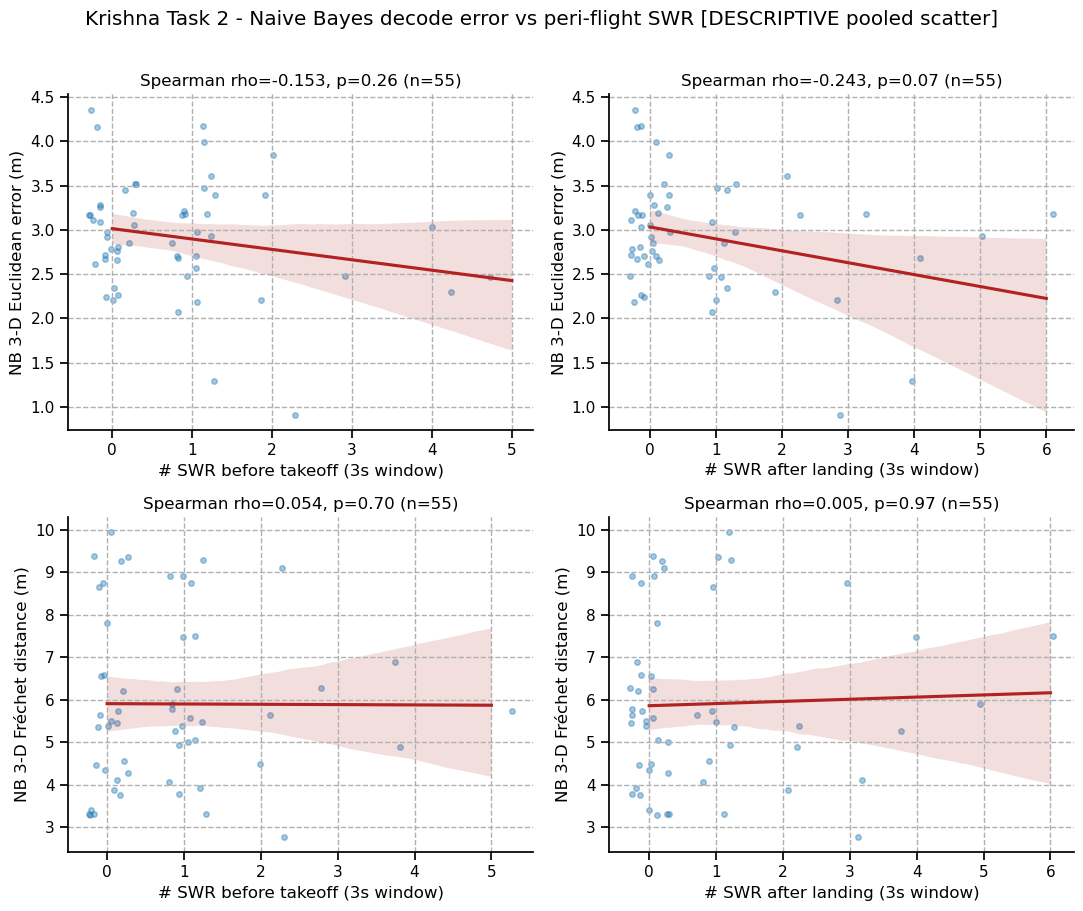

session-level (per-session Spearman, tested across sessions):
                        pair  n_sess  median_rho     p
     nb_err_3d ~ pre_takeoff       3       0.278 1.000
    nb_err_3d ~ post_landing       5      -0.234 0.625
 nb_frechet_3d ~ pre_takeoff       3      -0.133 0.250
nb_frechet_3d ~ post_landing       5      -0.034 1.000

Krishna LMM: log NB error ~ #SWR + flight_frac + (1|session/cluster)
          outcome    predictor  n    beta      p  beta_ff   p_ff
    nb_log_err_3d  pre_takeoff 55 -0.0308 0.3623  -0.0731 0.5604
    nb_log_err_3d post_landing 55 -0.0458 0.0729  -0.0335 0.7850
nb_log_frechet_3d  pre_takeoff 55  0.0161 0.6518  -0.0947 0.4809
nb_log_frechet_3d post_landing 55  0.0162 0.5237  -0.1062 0.4272


In [ ]:
# --- Krishna Task 2: peri-flight SWRs vs Naive Bayes decode error (no joint model on Krishna) ---
cfg_k = make_data_config(session_names=K_SESSIONS)
with contextlib.redirect_stdout(io.StringIO()):
    dl_k, _bdim_k, _units_k, meta_k = bat_data_loader(**cfg_k)

k_nb_rows = []
for s in dl_k['test'].keys():
    bm, bs, r_lim = meta_k['behavior_mean'][s], meta_k['behavior_std'][s], meta_k['r_lim'][s]
    tr = gather_session_arrays(dl_k['train'][s], bm, bs)
    te = gather_session_arrays(dl_k['test'][s], bm, bs)
    if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
        continue
    nb = NaiveBayes_Decoder(n_bins=(nb_par['n_bins_x'], nb_par['n_bins_y'], nb_par['n_bins_z']),
                            lims=[tuple(r_lim[d]) for d in range(3)], sigma=nb_par['sigma'],
                            dt=BIN_WIDTH, min_occupancy=nb_par['min_occupancy'],
                            use_uniform_prior=nb_par['use_uniform_prior']).fit(tr['spikes'], tr['pos'])
    pred, _ = nb.predict(te['spikes'])
    err3 = np.sqrt(((te['pos'] - pred) ** 2).sum(1))
    k_nb_rows.append(pd.DataFrame(dict(session=s, flight_id=te['flight_id'], t_idx=te['t_idx'],
        xt=te['pos'][:,0], yt=te['pos'][:,1], zt=te['pos'][:,2],
        xp=pred[:,0], yp=pred[:,1], zp=pred[:,2], err_3d=err3)))
k_nb_ts = pd.concat(k_nb_rows, ignore_index=True)

def _k_frechet(g):
    g = g.sort_values('t_idx')
    return discrete_frechet(g[['xt','yt','zt']].to_numpy(float), g[['xp','yp','zp']].to_numpy(float))
k_nb_fl = k_nb_ts.groupby(['session','flight_id']).agg(nb_err_3d=('err_3d','mean')).reset_index()
k_nb_fl['nb_frechet_3d'] = k_nb_ts.groupby(['session','flight_id']).apply(_k_frechet, include_groups=False).values

km = k_flights.merge(k_nb_fl, left_on=['session','flight_path_index'],
                     right_on=['session','flight_id'], how='inner')
km['nb_log_err_3d'] = np.log(km['nb_err_3d']); km['nb_log_frechet_3d'] = np.log(km['nb_frechet_3d'])
# alignment: NB first-timestep truth == reconstructed takeoff (same flight_path_index)
_chk = (k_nb_ts.sort_values('t_idx').groupby(['session','flight_id'])[['xt','yt','zt']].first().reset_index()
        .merge(k_flights, left_on=['session','flight_id'], right_on=['session','flight_path_index']))
_d = np.sqrt((_chk.xt-_chk.toff_x)**2+(_chk.yt-_chk.toff_y)**2+(_chk.zt-_chk.toff_z)**2)
print(f'{len(km)} Krishna test flights decoded; median NB err={km.nb_err_3d.median():.2f} m, '
      f'frechet={km.nb_frechet_3d.median():.2f} m; alignment max mismatch={_d.max():.4f} m')
assert _d.max() < 1e-6, 'Krishna flight_path_index misaligned!'

METR = [('nb_err_3d','NB 3-D Euclidean error (m)'), ('nb_frechet_3d','NB 3-D Fréchet distance (m)')]
SIDES2 = [('pre_takeoff','SWR before takeoff'), ('post_landing','SWR after landing')]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, (ycol, ylab) in enumerate(METR):
    for c, (xcol, xlab) in enumerate(SIDES2):
        ax = axes[r, c]; d = km.dropna(subset=[xcol, ycol])
        sns.regplot(data=d, x=xcol, y=ycol, ax=ax, x_jitter=0.3, scatter_kws=dict(s=16, alpha=0.4),
                    line_kws=dict(color='firebrick'))
        rho, p = spearmanr(d[xcol], d[ycol])
        ax.set(xlabel=f'# {xlab} ({W_PERI:g}s window)', ylabel=ylab,
               title=f'Spearman rho={rho:.3f}, p={p:.2f} (n={len(d)})')
fig.suptitle('Krishna Task 2 - Naive Bayes decode error vs peri-flight SWR [DESCRIPTIVE pooled scatter]', y=1.01)
fig.tight_layout(); plt.show()

# session-level Spearman across the 7 sessions + single-bat LMM (1|session/cluster)
recs = []
for ycol, _ in METR:
    for xcol, _ in SIDES2:
        rhos = [spearmanr(g[xcol], g[ycol])[0] for _s, g in km.dropna(subset=[xcol,ycol]).groupby('session')
                if g[xcol].nunique() > 2 and len(g) >= 6]
        _, pp = wilcoxon_safe(np.array(rhos)) if rhos else (np.nan, np.nan)
        recs.append(dict(pair=f'{ycol} ~ {xcol}', n_sess=len(rhos),
                         median_rho=np.nanmedian(rhos) if rhos else np.nan, p=pp))
print('session-level (per-session Spearman, tested across sessions):')
print(pd.DataFrame(recs).round(3).to_string(index=False))

t2_rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for ycol in ['nb_log_err_3d','nb_log_frechet_3d']:
        for xcol in ['pre_takeoff','post_landing']:
            d = km.dropna(subset=[ycol, xcol, 'flight_frac', 'clu_uid'])
            m = smf.mixedlm(f'{ycol} ~ {xcol} + flight_frac', d, groups=d['session'], re_formula='1',
                            vc_formula={'cluster': '0 + C(clu_uid)'}).fit(reml=True, method='lbfgs', maxiter=400)
            t2_rows.append(dict(outcome=ycol, predictor=xcol, n=len(d), beta=m.params[xcol],
                                p=m.pvalues[xcol], beta_ff=m.params['flight_frac'], p_ff=m.pvalues['flight_frac']))
print('\nKrishna LMM: log NB error ~ #SWR + flight_frac + (1|session/cluster)')
print(pd.DataFrame(t2_rows).round(4).to_string(index=False))

### Krishna replication — summary

Both effects seen in Dataset 1-3 are **not reproduced significantly** in Krishna, as
expected for a single bat (11719) across only 7 sessions with ~21-74 flights each:

- **Novel flights vs #SWRs (Task 3).** No significant cluster-size or cluster-identity
  effect on peri-flight SWR rate in any model (per-session Wilcoxon, LMM rate, NB GLM,
  Poisson GLMM, and glmer.nb where available; all p well above 0.05). Descriptively the
  *post-landing* rate is slightly higher for **repeated** than unique flights (~0.37 vs
  0.26 Hz) — the **opposite** sign to the main datasets' "rarer carry more", and n.s. —
  so there is no replication of the trajectory-novelty signal here.
- **SWRs vs decode error (Task 2).** Using a per-session **Naive Bayes** decoder (no
  joint model exists for Krishna), peri-flight SWR count shows **no significant**
  association with NB decode error or Fréchet distance — neither pooled (Spearman),
  session-level (across the 7 sessions), nor in the `(1|session/cluster)` LMM (all
  p ≳ 0.07). Absolute NB error is high (~2.9 m median) because the field-station room is
  far larger than the lab arenas and training flights are few.

Net: the Krishna data are underpowered to confirm or refute the Dataset 1-3 effects;
they are kept entirely separate so they do not dilute or contaminate the main analysis.

## Summary of findings

- **Peri-flight structure (Task 1).** SWRs are strongly suppressed *during*
  flight and rebound sharply right after landing and ramp up just before takeoff.
  **Perch vs reward** endpoints do not differ (pairwise n.s.), but the **three-way**
  test shows endpoints that are **neither perch nor reward ("other")** carry
  markedly higher peri-flight SWR rates (landing Friedman p<0.001, other > perch
  *** and > reward **; takeoff p=0.056, other > perch *). So the burst *is*
  endpoint-modulated — just not along the perch/reward axis.
- **Task 2 — decode error vs peri-flight SWRs (cluster-controlled + mixed model).**
  Both decode-error metrics (3-D **Euclidean** and 3-D **Fréchet**) rise with
  peri-flight SWR count. Naive pooled/partial correlations are confounded by
  in-domain vs OOD clusters (OOD flights have higher error *and* more SWRs; pooled
  partial-on-domain ≈0). But the effect **survives strict cluster control**: the
  within-cluster demeaned correlation is significant (Euclidean ρ=0.18, p=0.01;
  Fréchet ρ=0.17, p=0.015; post-landing Fréchet ρ=0.23, p=0.001), and a **linear
  mixed model** `metric ~ #SWR + (1 | subject/session/trajectory-cluster)` gives
  positive, significant slopes for **both** pre- and post-flight SWRs and **both**
  error metrics. Raw error residuals are strongly heteroscedastic (ρ(fitted,|resid|)≈0.5);
  **log-transforming** fixes this (ρ≈0.04–0.08) and the log-error models are the
  most significant (log-Euclidean: pre p=7e-4, post p=4e-3; log-Fréchet: pre p=1e-3,
  post p=3e-3; β≈+0.03 ⇒ ~3% higher error per extra peri-flight ripple). **Jacobian
  magnification** shows no significant SWR link in any test. Net: more peri-flight
  ripple activity robustly tracks *worse* decoding of that flight — within the same
  trajectory and across subjects — not merely as a cluster artefact. It also
  **survives controlling for normalized flight number** (session time): adding
  `flight_frac` leaves the SWR slopes significant and slightly larger (log-Euclidean
  pre p=2e-4, post p=2e-3; log-Fréchet pre p=1e-4, post p=3e-4), so it is not a
  within-session-time artefact either.
- **Task 3 — SWRs and flight-cluster identity.** Flights from **rarer / smaller
  clusters** carry **more** peri-flight SWRs (repeated 1.08 vs unique 1.52 Hz
  before takeoff; 1.01 vs 1.54 after landing). The session-level fixed-window test
  flagged this for pre-takeoff only, but better-powered nested models — an LMM
  `rate ~ cluster_size + (1|subject/session/cluster)`, a Poisson GLMM, a true
  **NB mixed model** `glmer.nb(count ~ cluster_size + offset(log interval) +
  (1|subject/session))` (fit in R via pymer4/rpy2), and an overdispersion-aware NB
  GLM (rest-interval counts; Poisson overdispersion χ²/df≈52, so NB is essential) —
  all show a **significant negative** cluster-size effect for **both** pre- and
  post-flight windows, raw and log cluster size (glmer.nb p<1e-4 throughout; the
  cluster-robust NB GLM, most conservative, p≈0.013–0.07). Log-transforming the SWR
  rate strengthens the descriptive linear fit (Pearson r −0.06→−0.14, matching
  Spearman). So peri-flight ripple density scales with trajectory novelty/rarity on
  both sides, rather than cleanly dissociating prediction from retrodiction. The
  cluster-size effect **survives adding normalized flight number** (glmer.nb p<1e-4;
  NB GLM p=0.018–0.04), and `flight_frac` is *independently* significant (p<1e-4) —
  so trajectory novelty and within-session time are separable, both lowering ripple
  density for repeated/late flights.
- **Task 4 — lab vs field station.** Field-station (Dataset 2) SWRs are
  significantly more **peri-flight-enriched** than lab SWRs (p≈0.01) and show a
  higher rate around landings; overall baseline rate and event duration do not differ
  significantly. *Note enrichment is <1 everywhere*: the whole-session baseline is
  dominated by **far-from-flight quiescent rest** (~1.0–1.3 Hz, the densest SWR epochs),
  while the ±3 s peri-flight windows abut the movement-suppression dip (in-flight ≈0.1
  Hz) — so "enrichment" means ripples are *less suppressed* near flights in the field
  station, not literally elevated above the session mean. A **within-animal** comparison
  (Krishna bat 11719, days 250812 & 250814 — both environments the same day, shared sort
  / same channels) **replicates this within-subject**: field station > lab in both
  pre-takeoff enrichment (lab→fs 0.44→0.56 and 0.35→0.87) and post-landing enrichment
  (0.31→0.37 and 0.30→0.50) on both days (raw rates likewise). For Krishna, **pre-takeoff
  > post-landing** (the 3 s post window catches the dip extending past landing; rebound
  peaks ~+2–7 s). The pooled peri-landing PSTH overlaps between environments because it
  mixes days with different baselines; the within-day paired metric is the cleaner
  comparison. (n=2 same-day pairs — descriptive, not formally tested.)
- **Task 5 — SWRs over the session.** Whole-session SWR rate is roughly **stable**
  across a session (per-session ρ vs time median −0.07, p=0.22), but **peri-flight**
  SWR rate is markedly higher for the **first few flights** and declines sharply
  (~2.2→0.7 Hz over the first third, then flat): per-session Spearman vs flight number
  median ρ=−0.15 (pre, p=0.013) and −0.30 (post, p=0.009); LMM
  `pre_rate ~ flight_num + (1|subject/session)` β=−0.014, z=−13, p<1e-3. Early-session
  flights are also the novel/rare ones, dovetailing with Task 3.
- **Task 6 — joint vs Naive Bayes decoder.** Repeating Task 2 with a basic **Naive
  Bayes** spatial decoder (Poisson rate-map / argmax; same flights, best HPs from
  `decode-position-comparison`) **replicates the effect**: more peri-flight SWRs →
  higher NB decode error / Fréchet, significant for both pre- and post-flight (β≈0.017–
  0.021, p=0.002–0.029), same sign as the joint model (β≈0.030–0.038, somewhat larger).
  NB is much worse overall (median err 0.70 vs 0.29 m; per-flight errors correlate
  ρ=0.79). So the peri-flight-SWR→worse-decoding link is a property of the **neural
  data**, not of the flexible transformer.
- **Bonus.** Post-landing SWR count is independent of total rest duration
  (per-session Spearman ≈0; the fixed-window metric is not confounded by dwell).
  Pre-takeoff SWR count does **not** predict upcoming flight duration once subject,
  session and cluster are accounted for (mixed model `dur ~ #SWR +
  (1|subject/session/cluster)`, p=0.23) — no "planning-for-longer-flights" signature;
  flight duration instead tracks session time (`flight_frac` p<1e-4, later flights
  shorter).

*Inference is session-aware throughout:* every reported test is either session-level
(per-session statistic → nonparametric test across sessions, dots coloured by bat)
or a mixed/count model with random intercepts for subject (and session, cluster
where applicable). Pooled scatters/correlations are kept only as **descriptive**
visualisations (labelled as such) — each has a session-aware counterpart that is the
basis for inference.

*Caveats:* session-level n is small (17 sessions, 6 bats; field station = 2 bats),
SWRs are pooled across probes (probe-merged), decode/Jacobian are on the held-out
test split only, and these are exploratory analyses.